In [1]:
# ============================================================
# CELL 1 — IMPORTS AND ENVIRONMENT
# ============================================================
import importlib, subprocess, sys

def _ensure(module, pip_name=None):
    # --no-deps: never let pip touch the PyTorch that Kaggle already has (a pip upgrade of torch inside
    # a running kernel breaks it with "module 'torch' has no attribute '_utils'").
    try:
        importlib.import_module(module)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", pip_name or module], check=False)

_ensure("pytorch_msssim", "pytorch-msssim")   # pure-python, needs only torch

import os, gc, glob, math, random, time, json, copy, hashlib, csv
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
from PIL import Image
import cv2
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from pytorch_msssim import ssim as torch_ssim

os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 65)
print("ENVIRONMENT")
print("=" * 65)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print("Device:", device)

ENVIRONMENT
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
GPU memory: 15.64 GB
Device: cuda


In [2]:
# ============================================================
# CELL 2 — CONFIGURATION + SMALL EXPERIMENT PLAN (V5)
# ============================================================
# Dataset paths are UNCHANGED. Every experiment overrides only what it changes; everything else
# comes from BASE_CONFIG, so two experiments differ only in the keys listed in their entry.
# The registry is deliberately small: every entry is part of the plan and answers one question.
# ============================================================

BASE_CONFIG = {
    # ---------------- dataset (unchanged) ----------------
    "data_root":  "/kaggle/input/datasets/kmljts/reside-6k/RESIDE-6K",
    "train_hazy": "/kaggle/input/datasets/kmljts/reside-6k/RESIDE-6K/train/hazy",
    "train_gt":   "/kaggle/input/datasets/kmljts/reside-6k/RESIDE-6K/train/GT",
    "test_hazy":  "/kaggle/input/datasets/kmljts/reside-6k/RESIDE-6K/test/hazy",
    "test_gt":    "/kaggle/input/datasets/kmljts/reside-6k/RESIDE-6K/test/GT",

    # ---------------- data / split ----------------
    "crop_size": 256,
    "batch_size": 8,
    # crop_schedule: None = every batch is batch_size x crop_size. Otherwise a list of
    # (crop, batch, probability); crop "full" = the whole 400x400 training image.
    "crop_schedule": None,
    # augment: "v3"    = h-flip p.5 + v-flip p.5 + rot90 p.3 (what V3 and C_v3_psnr_loss used)
    #          "hflip" = horizontal flip only (keeps "sky up / ground down"; DehazeFormer's RESIDE-6K setting)
    "augment": "hflip",
    "grad_accum_steps": 1,
    "num_workers": 2,
    "val_fraction": 0.10,
    "split_mode": "scene_disjoint",
    "pairing_prefix_fallback": True,
    "audit_pairs_sample": 400,

    # ---------------- evaluation ----------------
    "eval_max_dim": None,       # None = full resolution (corrected). V3 used 512 (legacy protocol).
    "eval_pad_multiple": 8,
    "val_every": 1,
    "eval_num_workers": 2,
    "probe_train_images": 300,  # fixed training images evaluated like val (full image, no augmentation)
    "probe_every": 10,          # -> train-probe vs val PSNR = over/under-fitting, measured on the same protocol

    # ---------------- optimisation ----------------
    "epochs": 60,
    "base_lr": 2e-4,
    "min_lr": 1e-6,
    "warmup_epochs": 3,
    "warmup_start_factor": 1e-2,
    "scheduler": "cosine",      # cosine | flat_cosine | onecycle | plateau
    "flat_fraction": 0.0,
    "weight_decay": 1e-4,
    "wd_exclude_norm_bias": False,
    "grad_clip_mode": "adaptive",
    "grad_clip_factor": 5.0,
    "grad_clip_norm": 1.0,
    "ema_decay": 0.999,
    "ema_warmup": False,
    "amp": True,
    "channels_last": False,     # CELL 12 measures the train-step time with/without; switch on only if faster on your GPU
    "compile": False,           # optional torch.compile of the TRAINING forward only (eval stays eager)

    # ---------------- loss ----------------
    "loss": "psnr",             # see CELL 15: psnr | mse | charb | img_psnr | v5_fixed | v5_staged | v3_bug
    "ssim_share": 0.10,         # target gradient-norm share of SSIM relative to the main term (balanced online)
    "stage_bounds": (0.30, 0.85),   # v5_staged: stage A < 30% of epochs <= stage B < 85% <= stage C
    "img_mse_momentum": 0.5,    # running per-image MSE used by img_psnr (metric-aligned weighting)

    # ---------------- architecture ----------------
    "arch": "E1",               # see CELL 11: v3 | E1 | P | L | S | V5

    # ---------------- initialisation ----------------
    "init_from": None,          # None | "legacy_v3" | "exp:<EXPERIMENT>" (its best checkpoint) | path
    "init_use_ema": True,

    # ---------------- run control ----------------
    "mode": "train",            # train | legacy_repro | diagnose
    "diagnose_experiment": "C_v3_psnr_loss",
    "run_final_test": True,
    "max_train_hours": 11.0,

    # ---------------- outputs ----------------
    "checkpoint_root": "/kaggle/working/HAFR_checkpoints",
    "results_dir": "/kaggle/working/HAFR_results",
    "legacy_v3_checkpoints": [
        "/kaggle/working/HAFR_checkpoints/best_psnr.pth",
        "/kaggle/working/HAFR_checkpoints/last.pth",
    ],
    "legacy_v3_search_globs": [            # shallow on purpose (fast)
        "/kaggle/input/*/HAFR_checkpoints/*.pth",
        "/kaggle/input/*/*/HAFR_checkpoints/*.pth",
        "/kaggle/input/*/*/*/HAFR_checkpoints/*.pth",
        "/kaggle/input/*/*.pth",
        "/kaggle/input/*/*/*.pth",
    ],
    # V3's numbers from the ORIGINAL notebook's log (legacy protocol, final-epoch EMA in last.pth)
    "legacy_v3_reference": {"test_psnr": 27.7508, "test_ssim": 0.9587},
    "legacy_tolerance": {"psnr": 0.005, "ssim": 0.0005},

    "seed": SEED,
    "split_seed": 42,
}

# ------------------------------------------------------------
# Choices made FROM MEASURED RESULTS (fill in after the screening stage; CELL 21 prints the rule).
# ------------------------------------------------------------
SCREEN_EPOCHS = 60            # identical budget for every screening run (E0-E6)
FINAL_EPOCHS = 265
BEST_ARCH = "V5"              # <- E1-E5 winner (val PSNR, beyond the E1/E1s noise floor)
BEST_LOSS = "v5_fixed"        # <- E5 / E6a / E6b winner
FT_FROM = "E6a_v5_loss"       # <- the screening run whose checkpoint E7a/E7b fine-tune

_ft = dict(arch=BEST_ARCH, init_from=f"exp:{FT_FROM}", epochs=20, base_lr=5e-5, warmup_epochs=0,
           loss="img_psnr", ema_decay=0.999)

EXPERIMENTS = {
    # ---------- already trained (kept so its checkpoint can be re-evaluated / diagnosed) ----------
    "C_v3_psnr_loss":      dict(arch="v3", loss="psnr", augment="v3", epochs=180, warmup_epochs=8),

    # ---------- no training ----------
    "R0_legacy_repro":     dict(mode="legacy_repro", arch="v3", split_mode="original_random"),
    "R1_diagnose":         dict(mode="diagnose", arch="v3", diagnose_experiment="C_v3_psnr_loss"),

    # ---------- screening: SAME split, seed, epochs, crop, LR, schedule ----------
    "E0_v3_baseline":      dict(arch="v3", loss="psnr", augment="v3", epochs=SCREEN_EPOCHS),    # current pipeline
    "E1_v3_fixed":         dict(arch="E1", loss="psnr", epochs=SCREEN_EPOCHS),                  # + h-flip only, eval-only clamp
    "E1s_v3_fixed_seed43": dict(arch="E1", loss="psnr", epochs=SCREEN_EPOCHS, seed=43),         # noise floor
    "E2_phys_head":        dict(arch="P",  loss="psnr", epochs=SCREEN_EPOCHS),                  # E1 + spatial transmission/airlight head
    "E3_lf_context":       dict(arch="L",  loss="psnr", epochs=SCREEN_EPOCHS),                  # E1 + low-frequency context (replaces DASFR)
    "E4_film_skip":        dict(arch="S",  loss="psnr", epochs=SCREEN_EPOCHS),                  # E1 + haze-modulated skips
    "E5_v5":               dict(arch="V5", loss="psnr", epochs=SCREEN_EPOCHS),                  # P + L + S
    "E6a_v5_loss":         dict(arch="V5", loss="v5_fixed", epochs=SCREEN_EPOCHS),              # E5 + metric-aligned loss
    "E6b_v5_staged":       dict(arch="V5", loss="v5_staged", epochs=SCREEN_EPOCHS),             # E6a + staged curriculum

    # ---------- conditional capacity test: run ONLY if CELL 21 reports under-fitting ----------
    "E8_v5_wide":          dict(arch="V5w", loss=BEST_LOSS, epochs=SCREEN_EPOCHS),

    # ---------- fine-tuning from FT_FROM's best checkpoint (same 20 epochs, same LR) ----------
    "E7a_ft_crop256":      dict(**_ft),                                                         # control: more epochs only
    "E7b_ft_full400":      dict(**_ft, crop_schedule=[("full", 3, 1.0)]),                       # whole 400x400 images

    # ---------- final ----------
    "FINAL":               dict(arch=BEST_ARCH, loss=BEST_LOSS, epochs=FINAL_EPOCHS, warmup_epochs=8),
    "FINAL_ft":            dict(**{**_ft, "init_from": "exp:FINAL"}, crop_schedule=[("full", 3, 1.0)]),
}

PLAN_REFERENCE = {   # experiment -> the run it is compared with (one variable apart)
    "E1_v3_fixed": "E0_v3_baseline", "E2_phys_head": "E1_v3_fixed", "E3_lf_context": "E1_v3_fixed",
    "E4_film_skip": "E1_v3_fixed", "E5_v5": "E1_v3_fixed", "E6a_v5_loss": "E5_v5",
    "E6b_v5_staged": "E6a_v5_loss", "E7b_ft_full400": "E7a_ft_crop256",
    "E8_v5_wide": {"psnr": "E5_v5", "v5_fixed": "E6a_v5_loss", "v5_staged": "E6b_v5_staged"}.get(BEST_LOSS, "E5_v5"),
}
NOISE_PAIR = ("E1_v3_fixed", "E1s_v3_fixed_seed43")

# ------------------------------------------------------------
# HCR-Net programme (CELL 11b). Same split / seed / crop / LR / schedule / augmentation as E1_v3_fixed
# (the best 60-epoch run so far: val 26.70 dB). Stage 1 = architecture, Stage 2 = loss, Stage 4 = final.
# ------------------------------------------------------------
BEST_HCR = "HD"             # <- Stage-1 winner (CELL 21 / launcher table print the rule)
BEST_HCR_LOSS = "psnr"      # <- Stage-2 winner
BEST_PIXEL = "charb"        # <- best of L_psnr / L_charb / L_mse (pixel term used by L_edge)
LOSS_SCREEN_EPOCHS = 40
HCR_FINAL_EPOCHS = 300
MAX_EPOCHS = 500            # MAX runs: long training, resumed across Kaggle sessions (10.5 h of training per session)
EXPERIMENTS.update({
    # Stage 1: one mechanism at a time, 60 epochs, the loss of E1 ("psnr")
    "H1_HA":  dict(arch="HA",  loss="psnr", epochs=SCREEN_EPOCHS),   # plain dual-mixer U-Net
    "H1_HB":  dict(arch="HB",  loss="psnr", epochs=SCREEN_EPOCHS),   # + haze-conditioned routing
    "H1_HC":  dict(arch="HC",  loss="psnr", epochs=SCREEN_EPOCHS),   # + soft reconstruction
    "H1_HD":  dict(arch="HD",  loss="psnr", epochs=SCREEN_EPOCHS),   # + both
    "H1_HB0": dict(arch="HB0", loss="psnr", epochs=SCREEN_EPOCHS),   # routing WITHOUT the haze map
    "H1_HE":  dict(arch="HE",  loss="psnr", epochs=SCREEN_EPOCHS),   # + DASFR frequency refinement
    # Stage 2: loss on the Stage-1 winner, 40 epochs
    "L_psnr":         dict(arch=BEST_HCR, loss="psnr",         epochs=LOSS_SCREEN_EPOCHS),
    "L_charb":        dict(arch=BEST_HCR, loss="charb",        epochs=LOSS_SCREEN_EPOCHS),   # A
    "L_mse":          dict(arch=BEST_HCR, loss="mse",          epochs=LOSS_SCREEN_EPOCHS),   # B
    "L_charb_ssim05": dict(arch=BEST_HCR, loss="charb_ssim05", epochs=LOSS_SCREEN_EPOCHS),   # C
    "L_charb_ssim10": dict(arch=BEST_HCR, loss="charb_ssim10", epochs=LOSS_SCREEN_EPOCHS),   # D
    "L_mse_ssim05":   dict(arch=BEST_HCR, loss="mse_ssim05",   epochs=LOSS_SCREEN_EPOCHS),   # E
    "L_edge":         dict(arch=BEST_HCR, loss=f"{BEST_PIXEL}_edge05", epochs=LOSS_SCREEN_EPOCHS),  # F
    # Stage 4: final (two seeds = the run-to-run noise of the final number)
    "FINAL_HCR":      dict(arch=BEST_HCR, loss=BEST_HCR_LOSS, epochs=HCR_FINAL_EPOCHS, warmup_epochs=8),
    "FINAL_HCR_s43":  dict(arch=BEST_HCR, loss=BEST_HCR_LOSS, epochs=HCR_FINAL_EPOCHS, warmup_epochs=8, seed=43),
})
PLAN_REFERENCE.update({"H1_HB": "H1_HA", "H1_HC": "H1_HA", "H1_HD": "H1_HA", "H1_HB0": "H1_HB",
                       "H1_HE": "H1_HD", "L_charb": "L_psnr", "L_mse": "L_psnr", "L_charb_ssim05": "L_charb",
                       "L_charb_ssim10": "L_charb", "L_mse_ssim05": "L_mse", "L_edge": f"L_{BEST_PIXEL}"})

# MAX: every training image (split_mode="all"), LAST-epoch checkpoint (no selection on any image set),
# flip-averaged test reported NEXT TO the standard number. MAX_HD = main model; MAX_HA = same widths without
# routing and soft reconstruction (the full-length ablation of the two mechanisms).
_max = dict(loss=BEST_HCR_LOSS, split_mode="all", select="last", epochs=MAX_EPOCHS, warmup_epochs=8,
            max_train_hours=10.5, tta_test=True)
EXPERIMENTS.update({"MAX_HD": dict(arch="HX", **_max), "MAX_HA": dict(arch="HXA", **_max)})
PLAN_REFERENCE.update({"MAX_HD": "MAX_HA"})

# ============================================================
# >>> CHOOSE THE EXPERIMENT TO RUN <<<
# ============================================================
EXPERIMENT = "MAX_HD"      # <- the final model: HCR-Net MAX (986,147 params), all 6,000 images, 500 epochs
# 2-GPU launcher (last cell) sets HAFR_EXPERIMENT for each background job; without it nothing changes
EXPERIMENT = os.environ.get("HAFR_EXPERIMENT", EXPERIMENT)
_hits = sorted(glob.glob("/kaggle/input/**/RESIDE-6K", recursive=True))   # dataset wherever it is mounted
if _hits and not os.path.exists(BASE_CONFIG["data_root"]):
    _r = _hits[0]
    BASE_CONFIG.update(data_root=_r, train_hazy=f"{_r}/train/hazy", train_gt=f"{_r}/train/GT",
                       test_hazy=f"{_r}/test/hazy", test_gt=f"{_r}/test/GT")

CONFIG = {**BASE_CONFIG, **EXPERIMENTS[EXPERIMENT], "experiment": EXPERIMENT}

# Offline verification hook (used only to test this notebook on a tiny synthetic dataset;
# it does nothing on Kaggle unless you set the environment variable yourself).
if os.environ.get("HAFR_SMOKE_TEST") == "1":
    _root = os.environ["HAFR_SMOKE_ROOT"]
    EXPERIMENT = os.environ.get("HAFR_SMOKE_EXPERIMENT", EXPERIMENT)
    CONFIG = {**BASE_CONFIG, **EXPERIMENTS[EXPERIMENT], "experiment": EXPERIMENT}
    if CONFIG.get("crop_schedule"):
        CONFIG["crop_schedule"] = [(c, 2, p) for c, _, p in CONFIG["crop_schedule"]]
    CONFIG.update({
        "data_root": _root,
        "train_hazy": f"{_root}/train/hazy", "train_gt": f"{_root}/train/GT",
        "test_hazy": f"{_root}/test/hazy", "test_gt": f"{_root}/test/GT",
        "checkpoint_root": f"{_root}/_ckpt", "results_dir": f"{_root}/_results",
        "legacy_v3_checkpoints": [f"{_root}/_legacy/best_psnr.pth", f"{_root}/_legacy/last.pth"],
        "legacy_v3_search_globs": [f"{_root}/_none/*.pth"],
        "batch_size": 2, "num_workers": 0, "eval_num_workers": 0, "crop_size": 64,
        "epochs": int(os.environ.get("HAFR_SMOKE_EPOCHS", "2")), "warmup_epochs": 1,
        "audit_pairs_sample": None, "probe_train_images": 4, "probe_every": 1,
        "max_train_hours": float(os.environ.get("HAFR_SMOKE_HOURS", "11.0")),
    })
    if EXPERIMENT.startswith("E7") or EXPERIMENT == "FINAL_ft":
        CONFIG["epochs"] = 1

import shutil


def restore_from_inputs(input_root="/kaggle/input"):
    """Copy HAFR_results / HAFR_checkpoints from attached notebook outputs into /kaggle/working
    (existing files are never overwritten), so runs resume and the summary accumulates."""
    copied = 0
    for name, dst_root in [("HAFR_results", CONFIG["results_dir"]), ("HAFR_checkpoints", CONFIG["checkpoint_root"])]:
        pats = [os.path.join(input_root, *(["*"] * d), name) for d in range(1, 5)]
        for src_root in sorted({p for pat in pats for p in glob.glob(pat)}):
            if not os.path.isdir(src_root):
                continue
            for dirpath, _, files in os.walk(src_root):
                for fn in files:
                    src = os.path.join(dirpath, fn)
                    dst = os.path.join(dst_root, os.path.relpath(src, src_root))
                    if not os.path.exists(dst):
                        os.makedirs(os.path.dirname(dst), exist_ok=True)
                        shutil.copy2(src, dst)
                        copied += 1
    if copied:
        print(f"Restored {copied} files from attached inputs into /kaggle/working")


if os.path.isdir("/kaggle/input") and os.environ.get("HAFR_SMOKE_TEST") != "1":
    restore_from_inputs()

EXP_CKPT_DIR = os.path.join(CONFIG["checkpoint_root"], CONFIG["experiment"])
EXP_RESULTS_DIR = os.path.join(CONFIG["results_dir"], CONFIG["experiment"])
os.makedirs(EXP_CKPT_DIR, exist_ok=True)
os.makedirs(EXP_RESULTS_DIR, exist_ok=True)

print("=" * 65)
print("CONFIGURATION")
print("=" * 65)
print("Experiment :", CONFIG["experiment"])
for k in ["mode", "arch", "loss", "augment", "crop_schedule", "split_mode", "epochs", "base_lr", "scheduler",
          "batch_size", "amp", "grad_clip_mode", "eval_max_dim", "eval_pad_multiple", "init_from", "seed"]:
    print(f"  {k:18s}: {CONFIG[k]}")
if EXPERIMENT in PLAN_REFERENCE:
    print(f"  compared with     : {PLAN_REFERENCE[EXPERIMENT]}")
print("Checkpoints:", EXP_CKPT_DIR)
print("Results    :", EXP_RESULTS_DIR)

CONFIGURATION
Experiment : MAX_HD
  mode              : train
  arch              : HX
  loss              : psnr
  augment           : hflip
  crop_schedule     : None
  split_mode        : all
  epochs            : 500
  base_lr           : 0.0002
  scheduler         : cosine
  batch_size        : 8
  amp               : True
  grad_clip_mode    : adaptive
  eval_max_dim      : None
  eval_pad_multiple : 8
  init_from         : None
  seed              : 42
  compared with     : MAX_HA
Checkpoints: /kaggle/working/HAFR_checkpoints/MAX_HD
Results    : /kaggle/working/HAFR_results/MAX_HD


In [3]:
# ============================================================
# CELL 3 — VERIFY DATASET PATHS
# ============================================================
print("=" * 65)
print("DATASET PATH VERIFICATION")
print("=" * 65)
_ok = True
for label, key in [("Dataset root", "data_root"), ("Train hazy", "train_hazy"), ("Train GT", "train_gt"),
                   ("Test hazy", "test_hazy"), ("Test GT", "test_gt")]:
    exists = os.path.exists(CONFIG[key])
    _ok &= exists
    print(f"{label:14s}: {'✓ EXISTS' if exists else '✗ MISSING'}\n    {CONFIG[key]}")
assert _ok, "Fix the dataset paths in CELL 2."
print("\n✓ ALL DATASET PATHS ARE CORRECT")

DATASET PATH VERIFICATION
Dataset root  : ✓ EXISTS
    /kaggle/input/datasets/kmljts/reside-6k/RESIDE-6K
Train hazy    : ✓ EXISTS
    /kaggle/input/datasets/kmljts/reside-6k/RESIDE-6K/train/hazy
Train GT      : ✓ EXISTS
    /kaggle/input/datasets/kmljts/reside-6k/RESIDE-6K/train/GT
Test hazy     : ✓ EXISTS
    /kaggle/input/datasets/kmljts/reside-6k/RESIDE-6K/test/hazy
Test GT       : ✓ EXISTS
    /kaggle/input/datasets/kmljts/reside-6k/RESIDE-6K/test/GT

✓ ALL DATASET PATHS ARE CORRECT


In [4]:
# ============================================================
# CELL 4 — STRICT HAZY→GT PAIRING (audited)
# ============================================================
# What the V3 build_pairs() did:
#   * gt_map = {stem: path}  -> duplicate GT stems (e.g. the same name in two sub-folders, or
#     "12.png" + "12.jpg") silently kept only the LAST file;
#   * fallback stem.split("_")[0] -> correct for RESIDE ITS/OTS naming ("1400_3_0.85.png" -> "1400.png"),
#     but it was never reported, so a wrong partial-name match would be invisible;
#   * unmatched hazy images were silently dropped.
# This version keeps exactly the same matching rule (exact stem first, then the prefix fallback),
# so dataset semantics do not change, but it FAILS LOUDLY on ambiguity and REPORTS every rule used.
# ============================================================
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp"}


def image_files(folder):
    files = []
    for ext in IMAGE_EXTENSIONS:
        for e in (ext, ext.upper()):
            files.extend(glob.glob(os.path.join(folder, f"**/*{e}"), recursive=True))
    return sorted(set(files))


def build_pairs_strict(hazy_dir, gt_dir, allow_prefix_fallback=True, strict=True, name="", n_examples=8):
    hazy_files = image_files(hazy_dir)
    gt_files = image_files(gt_dir)
    print(f"[{name}] hazy images: {len(hazy_files)} | GT images: {len(gt_files)}")

    stem_to_paths = defaultdict(list)
    for p in gt_files:
        stem_to_paths[Path(p).stem].append(p)
    duplicates = {s: ps for s, ps in stem_to_paths.items() if len(ps) > 1}
    if duplicates:
        ex = list(duplicates.items())[:3]
        raise RuntimeError(f"[{name}] {len(duplicates)} GT stems are not unique, e.g. {ex}. "
                           "V3's dict lookup would have silently kept the last one.")
    gt_map = {s: ps[0] for s, ps in stem_to_paths.items()}

    pairs, rule_used, unmatched, ambiguous = [], [], [], []
    for hp in hazy_files:
        stem = Path(hp).stem
        prefix = stem.split("_")[0]
        if stem in gt_map:
            pairs.append((hp, gt_map[stem])); rule_used.append("exact")
            if prefix != stem and prefix in gt_map:
                ambiguous.append((hp, gt_map[stem], gt_map[prefix]))
        elif allow_prefix_fallback and prefix != stem and prefix in gt_map:
            pairs.append((hp, gt_map[prefix])); rule_used.append("prefix")
        else:
            unmatched.append(hp)

    counts = Counter(rule_used)
    gt_use = Counter(g for _, g in pairs)
    multi = sum(1 for c in gt_use.values() if c > 1)
    print(f"[{name}] pairs: {len(pairs)} | exact-stem: {counts.get('exact', 0)} | "
          f"prefix-fallback: {counts.get('prefix', 0)} | unmatched: {len(unmatched)}")
    print(f"[{name}] GT files used by >1 hazy image: {multi} "
          f"(expected 0 for one-file-per-hazy datasets like the Kaggle RESIDE-6K copy; "
          f">0 is normal for ITS-style 'scene_k_beta' naming)")
    if ambiguous:
        print(f"[{name}] ⚠ {len(ambiguous)} hazy files match BOTH an exact GT and a prefix GT; "
              f"exact was used. e.g. {[(Path(a).name, Path(b).name, Path(c).name) for a, b, c in ambiguous[:3]]}")
    if unmatched:
        msg = f"[{name}] {len(unmatched)} hazy images have no GT, e.g. {[Path(u).name for u in unmatched[:5]]}"
        if strict:
            raise RuntimeError(msg + " (set strict=False to skip them explicitly)")
        print("⚠", msg, "-> skipped")

    print(f"[{name}] examples (hazy → GT):")
    shown = 0
    for (hp, gp), r in zip(pairs, rule_used):
        if shown < n_examples or (r == "prefix" and shown < n_examples + 3):
            print(f"    {Path(hp).relative_to(hazy_dir)}  →  {Path(gp).relative_to(gt_dir)}   [{r}]")
            shown += 1
    report = dict(n_pairs=len(pairs), exact=counts.get("exact", 0), prefix=counts.get("prefix", 0),
                  unmatched=len(unmatched), ambiguous=len(ambiguous), gt_reused=multi)
    return pairs, report


print("=" * 65)
print("BUILDING PAIRS")
print("=" * 65)
train_pairs_all, train_pair_report = build_pairs_strict(
    CONFIG["train_hazy"], CONFIG["train_gt"], CONFIG["pairing_prefix_fallback"], name="train")
print()
test_pairs, test_pair_report = build_pairs_strict(
    CONFIG["test_hazy"], CONFIG["test_gt"], CONFIG["pairing_prefix_fallback"], name="test")
assert len(train_pairs_all) > 0 and len(test_pairs) > 0
print("\n✓ PAIRING COMPLETE (no silent drops, no ambiguous GT stems)")

BUILDING PAIRS
[train] hazy images: 6000 | GT images: 6000
[train] pairs: 6000 | exact-stem: 6000 | prefix-fallback: 0 | unmatched: 0
[train] GT files used by >1 hazy image: 0 (expected 0 for one-file-per-hazy datasets like the Kaggle RESIDE-6K copy; >0 is normal for ITS-style 'scene_k_beta' naming)
[train] examples (hazy → GT):
    1.jpg  →  1.jpg   [exact]
    10.jpg  →  10.jpg   [exact]
    100.jpg  →  100.jpg   [exact]
    1000.jpg  →  1000.jpg   [exact]
    1001.jpg  →  1001.jpg   [exact]
    1002.jpg  →  1002.jpg   [exact]
    1003.jpg  →  1003.jpg   [exact]
    1004.jpg  →  1004.jpg   [exact]

[test] hazy images: 1000 | GT images: 1000
[test] pairs: 1000 | exact-stem: 1000 | prefix-fallback: 0 | unmatched: 0
[test] GT files used by >1 hazy image: 0 (expected 0 for one-file-per-hazy datasets like the Kaggle RESIDE-6K copy; >0 is normal for ITS-style 'scene_k_beta' naming)
[test] examples (hazy → GT):
    0001_0.8_0.2.jpg  →  0001_0.8_0.2.jpg   [exact]
    0002_0.8_0.08.jpg  →  00

sizes[train]:   0%|          | 0/6000 [00:00<?, ?it/s]

[train] most common sizes (W x H): [((400, 400), 6000)]  | distinct sizes: 1
[train] file formats (hazy, GT): {('.jpg', '.jpg'): 6000}
[train] note: GT stored as JPEG -> compression noise in GT is unpredictable from the input and caps attainable PSNR; results are only comparable to papers that used the same files.
[train] ✓ all 6000 pairs have identical hazy/GT size


sizes[test]:   0%|          | 0/1000 [00:00<?, ?it/s]

[test] most common sizes (W x H): [((620, 460), 500), ((548, 412), 273), ((548, 408), 71), ((548, 732), 47), ((548, 308), 15), ((548, 736), 11)]  | distinct sizes: 58
[test] file formats (hazy, GT): {('.jpg', '.jpg'): 500, ('.png', '.png'): 500}
[test] note: GT stored as JPEG -> compression noise in GT is unpredictable from the input and caps attainable PSNR; results are only comparable to papers that used the same files.
[test] ✓ all 1000 pairs have identical hazy/GT size
Test subsets (by size heuristic): Counter({'outdoor': 500, 'indoor': 500})


content[train]:   0%|          | 0/400 [00:00<?, ?it/s]

[train] edge-map correlation hazy vs its GT over 400 pairs: min 0.150 | 1% 0.314 | median 0.982   (deliberate mis-pairs: median 0.031)
[train] suspicious pairs (corr < 0.3): 4 [('5242.jpg', '5242.jpg', np.float64(0.208)), ('4867.jpg', '4867.jpg', np.float64(0.273)), ('5769.jpg', '5769.jpg', np.float64(0.233)), ('4902.jpg', '4902.jpg', np.float64(0.15))]


content[test]:   0%|          | 0/400 [00:00<?, ?it/s]

[test] edge-map correlation hazy vs its GT over 400 pairs: min 0.807 | 1% 0.841 | median 0.981   (deliberate mis-pairs: median 0.016)
[test] suspicious pairs (corr < 0.3): 0 []


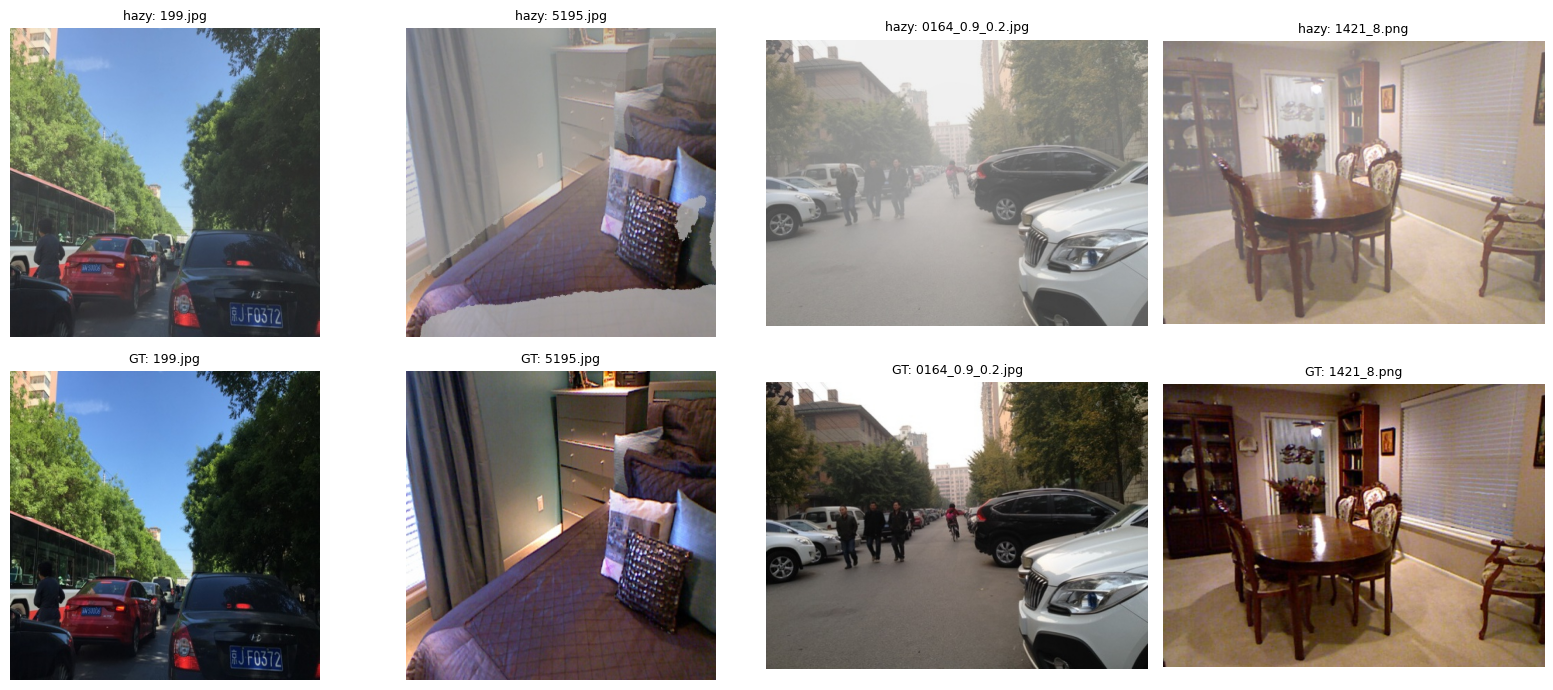

In [5]:
# ============================================================
# CELL 5 — PAIR CONTENT AUDIT (sizes, formats, subsets, mis-pair check)
# ============================================================
# V3's random_crop() and the eval crop both assume hazy and GT have the same size; that was never
# checked. A size mismatch (e.g. SOTS-indoor GT with the 10-px white border) would silently
# misalign every crop. This cell verifies it for EVERY pair (header read only, fast).
# ============================================================

def image_size(path):
    with Image.open(path) as im:
        return im.size  # (W, H)


def audit_sizes(pairs, name):
    sizes, bad = Counter(), []
    exts = Counter()
    for hp, gp in tqdm(pairs, desc=f"sizes[{name}]", leave=False):
        sh, sg = image_size(hp), image_size(gp)
        sizes[sh] += 1
        exts[(Path(hp).suffix.lower(), Path(gp).suffix.lower())] += 1
        if sh != sg:
            bad.append((Path(hp).name, sh, Path(gp).name, sg))
    print(f"[{name}] most common sizes (W x H): {sizes.most_common(6)}  | distinct sizes: {len(sizes)}")
    print(f"[{name}] file formats (hazy, GT): {dict(exts)}")
    if any(e[1] in (".jpg", ".jpeg") for e in exts):
        print(f"[{name}] note: GT stored as JPEG -> compression noise in GT is unpredictable from the input "
              "and caps attainable PSNR; results are only comparable to papers that used the same files.")
    if bad:
        raise RuntimeError(f"[{name}] {len(bad)} hazy/GT size mismatches, e.g. {bad[:5]}")
    print(f"[{name}] ✓ all {len(pairs)} pairs have identical hazy/GT size")
    return sizes


train_sizes = audit_sizes(train_pairs_all, "train")
test_sizes = audit_sizes(test_pairs, "test")


def subset_label(path):
    """SOTS-indoor images are 620x460; everything else in the RESIDE-6K test set is treated as outdoor.
    This is a heuristic — the printout below lets you check the counts (expected roughly 500/500)."""
    return "indoor" if image_size(path) == (620, 460) else "outdoor"


test_subsets = {hp: subset_label(hp) for hp, _ in test_pairs}
print("Test subsets (by size heuristic):", Counter(test_subsets.values()))


def _thumb(path, size=64):
    im = Image.open(path)
    im.draft("RGB", (size * 2, size * 2))           # JPEG: decode at reduced scale (fast)
    im = im.convert("RGB").resize((size, size), Image.BILINEAR)
    return np.asarray(im, dtype=np.float32) / 255.0


def _grad_mag(img):
    lum = img.mean(-1)
    gx = cv2.Sobel(lum, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(lum, cv2.CV_32F, 0, 1, ksize=3)
    g = np.sqrt(gx * gx + gy * gy).ravel()
    return (g - g.mean()) / (g.std() + 1e-6)


def audit_content(pairs, name, n=None, thr=0.3):
    """Mis-pair check. Haze lowers contrast (I = J t + A(1-t)) but keeps edges in the same places,
    so the edge maps of a correct hazy/GT pair are strongly correlated, while an unrelated GT gives
    a correlation near 0. Edge maps are used rather than raw intensities, because depth-dependent haze
    can make raw-intensity correlation low even for correct pairs."""
    idx = list(range(len(pairs)))
    if n is not None and n < len(idx):
        idx = random.Random(0).sample(idx, n)
    corrs = np.array([float((_grad_mag(_thumb(pairs[i][0], 128)) * _grad_mag(_thumb(pairs[i][1], 128))).mean())
                      for i in tqdm(idx, desc=f"content[{name}]", leave=False)])
    # reference: deliberately mismatched pairs (hazy i with GT of a different index)
    ref = [float((_grad_mag(_thumb(pairs[i][0], 128)) * _grad_mag(_thumb(pairs[(i + len(pairs) // 2) % len(pairs)][1], 128))).mean())
           for i in idx[:min(30, len(idx))]]
    sus = [(Path(pairs[i][0]).name, Path(pairs[i][1]).name, round(c, 3)) for i, c in zip(idx, corrs) if c < thr]
    print(f"[{name}] edge-map correlation hazy vs its GT over {len(idx)} pairs: min {corrs.min():.3f} | "
          f"1% {np.percentile(corrs, 1):.3f} | median {np.median(corrs):.3f}   "
          f"(deliberate mis-pairs: median {np.median(ref):.3f})")
    print(f"[{name}] suspicious pairs (corr < {thr}): {len(sus)} {sus[:10]}")
    return corrs


_ = audit_content(train_pairs_all, "train", CONFIG["audit_pairs_sample"])
_ = audit_content(test_pairs, "test", CONFIG["audit_pairs_sample"])

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for j, (hp, gp) in enumerate(random.Random(1).sample(train_pairs_all, 2) + random.Random(1).sample(test_pairs, 2)):
    axes[0, j].imshow(Image.open(hp).convert("RGB")); axes[0, j].set_title(f"hazy: {Path(hp).name}", fontsize=9)
    axes[1, j].imshow(Image.open(gp).convert("RGB")); axes[1, j].set_title(f"GT: {Path(gp).name}", fontsize=9)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout(); plt.show()

In [6]:
# ============================================================
# CELL 6 — TRAIN / VAL SPLIT  (original V3 split reproduced + scene-disjoint split)
# ============================================================
# MEASURED on this Kaggle copy (C_v3_psnr_loss output): 6000 training GTs form 5,939 distinct clean
# scenes (only 16 byte-identical groups), and V3's random split had only 1.7% of val images whose
# clean scene was also in train. The earlier "pigeonhole" leakage concern (ITS/OTS scene reuse) does
# NOT apply to this copy, so the scene-disjoint split is kept only for hygiene; it is NOT a reason
# for any PSNR difference between V3 (random split) and later runs — the two splits simply hold out
# DIFFERENT 600 images, so their val PSNRs are not comparable with each other.
# NEW: test images whose GT near-duplicates a training GT are flagged (test_gt_seen) so CELL 17/18
# can report test PSNR for seen vs unseen clean scenes.
# ============================================================

def _file_md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


class _UnionFind:
    def __init__(self, n):
        self.p = list(range(n))

    def find(self, a):
        while self.p[a] != a:
            self.p[a] = self.p[self.p[a]]
            a = self.p[a]
        return a

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.p[rb] = ra


def gt_thumbnails(paths, size=16):
    return np.stack([_thumb(p, size).ravel() for p in tqdm(paths, desc="GT thumbnails", leave=False)])


def scene_groups(gt_paths, thr=0.01, size=16, cache_name=None):
    """Return a scene id per GT path. Same id = identical file bytes OR 16x16 thumbnails whose
    mean absolute difference is < thr (robust to re-encoding of the same clean image)."""
    cache = os.path.join(CONFIG["results_dir"], cache_name) if cache_name else None
    key = hashlib.md5("|".join(gt_paths).encode()).hexdigest()
    if cache and os.path.exists(cache):
        with open(cache) as f:
            c = json.load(f)
        if c.get("key") == key:
            return c["scene_ids"], c["stats"]
    n = len(gt_paths)
    uf = _UnionFind(n)
    first_by_md5 = {}
    for i, p in enumerate(tqdm(gt_paths, desc="md5", leave=False)):
        m = _file_md5(p)
        if m in first_by_md5:
            uf.union(first_by_md5[m], i)
        else:
            first_by_md5[m] = i
    X = torch.from_numpy(gt_thumbnails(gt_paths, size)).to(device)
    nn_dist = []
    for s in range(0, n, 512):
        D = torch.cdist(X[s:s + 512], X, p=1) / X.shape[1]
        D[torch.arange(D.shape[0]), torch.arange(s, s + D.shape[0])] = float("inf")
        nn_dist.append(D.min(1).values.cpu())
        ii, jj = torch.nonzero(D < thr, as_tuple=True)
        for a, b in zip((ii + s).tolist(), jj.tolist()):
            uf.union(a, b)
    nn_dist = torch.cat(nn_dist).numpy()
    roots = [uf.find(i) for i in range(n)]
    remap = {r: k for k, r in enumerate(dict.fromkeys(roots))}
    scene_ids = [remap[r] for r in roots]
    sizes = Counter(Counter(scene_ids).values())
    stats = dict(n_images=n, n_scenes=len(remap), exact_md5_groups=n - len(first_by_md5),
                 group_size_hist=dict(sorted(sizes.items())),
                 nn_dist_quantiles={q: float(np.quantile(nn_dist[np.isfinite(nn_dist)], q)) for q in (0.01, 0.05, 0.5)},
                 n_borderline=int(((nn_dist >= thr) & (nn_dist < 3 * thr)).sum()))
    if cache:
        os.makedirs(os.path.dirname(cache), exist_ok=True)
        _tmp = f"{cache}.{os.getpid()}.tmp"           # atomic: two jobs may write it at the same time
        with open(_tmp, "w") as f:
            json.dump({"key": key, "scene_ids": scene_ids, "stats": stats}, f)
        os.replace(_tmp, cache)
    return scene_ids, stats


print("=" * 65)
print("SCENE GROUPING (training GT)")
print("=" * 65)
train_gt_paths = [g for _, g in train_pairs_all]
train_scene_ids, scene_stats = scene_groups(train_gt_paths, cache_name="scene_groups_train.json")
print(json.dumps(scene_stats, indent=1, default=str))
scene_of = {hp: sid for (hp, _), sid in zip(train_pairs_all, train_scene_ids)}

# ---------- 1) V3's ORIGINAL split, reproduced exactly ----------
# V3: random.seed(42) in CELL 1, no other python-random calls, then random.shuffle(train_pairs_all).
_orig = list(train_pairs_all)
random.Random(42).shuffle(_orig)
_split = int((1.0 - CONFIG["val_fraction"]) * len(_orig))
orig_train_pairs, orig_val_pairs = _orig[:_split], _orig[_split:]
_expected_first = ["4745", "5910", "566", "762", "1392"]   # first 5 shuffled pairs printed in V3's log
_got_first = [Path(p[0]).stem for p in _orig[:5]]
print("Original split reproduced:", "✓ matches V3 log" if _got_first == _expected_first
      else f"⚠ differs from V3 log (got {_got_first}, V3 showed {_expected_first})")

_train_scenes = {scene_of[hp] for hp, _ in orig_train_pairs}
orig_val_leaked = {hp: (scene_of[hp] in _train_scenes) for hp, _ in orig_val_pairs}
leak_frac = np.mean(list(orig_val_leaked.values()))
print(f"V3 split: {len(orig_train_pairs)} train / {len(orig_val_pairs)} val; "
      f"val images whose clean scene is also in train: {100 * leak_frac:.1f}%")

# ---------- 2) scene-disjoint split (same 10% budget) ----------
_groups = defaultdict(list)
for pair, sid in zip(train_pairs_all, train_scene_ids):
    _groups[sid].append(pair)
_gids = sorted(_groups)
random.Random(CONFIG["split_seed"]).shuffle(_gids)
_target = int(round(CONFIG["val_fraction"] * len(train_pairs_all)))
sd_val, sd_train = [], []
for gid in _gids:
    (sd_val if len(sd_val) < _target else sd_train).extend(_groups[gid])
sd_train.sort(); sd_val.sort()
assert not ({scene_of[h] for h, _ in sd_train} & {scene_of[h] for h, _ in sd_val})
print(f"Scene-disjoint split: {len(sd_train)} train / {len(sd_val)} val (0 shared scenes)")

# ---------- 3) does any TEST scene appear in training? (dataset property, same for all methods) ----------
_Xtr = torch.from_numpy(gt_thumbnails(train_gt_paths)).to(device)
_Xte = torch.from_numpy(gt_thumbnails([g for _, g in test_pairs])).to(device)
_d = torch.cat([(torch.cdist(_Xte[s:s + 512], _Xtr, p=1) / _Xtr.shape[1]).min(1).values
                for s in range(0, len(_Xte), 512)]).cpu().numpy()
print(f"Test images whose GT near-duplicates a training GT (thr 0.01): {(int((_d < 0.01).sum()))} / {len(_d)}")
test_gt_seen = {hp: int(dd < 0.01) for (hp, _), dd in zip(test_pairs, _d)}
_seen_by_subset = Counter(test_subsets[hp] for hp, f in test_gt_seen.items() if f)
print(f"  ...by subset: {dict(_seen_by_subset)}")
del _Xtr, _Xte

# ---------- select ----------
if CONFIG["split_mode"] == "original_random":
    train_pairs, val_pairs = orig_train_pairs, orig_val_pairs
elif CONFIG["split_mode"] == "scene_disjoint":
    train_pairs, val_pairs = sd_train, sd_val
elif CONFIG["split_mode"] == "all":
    # final models: all 6,000 training images. "val" = the same 600 scene-disjoint images, now SEEN in training:
    # it only monitors training; the checkpoint used for the test is the LAST epoch (select="last").
    train_pairs, val_pairs = sorted(sd_train + sd_val), sd_val
    print("split_mode=all: training on ALL images; val PSNR below is NOT held-out (monitor only)")
else:
    raise ValueError(CONFIG["split_mode"])
_used_train_scenes = {scene_of[h] for h, _ in train_pairs}
val_leaked = {hp: (scene_of[hp] in _used_train_scenes) for hp, _ in val_pairs}

with open(os.path.join(EXP_RESULTS_DIR, "split.json"), "w") as f:
    json.dump({"split_mode": CONFIG["split_mode"], "train": [Path(h).name for h, _ in train_pairs],
               "val": [Path(h).name for h, _ in val_pairs]}, f)

print("=" * 65)
print(f"USING SPLIT: {CONFIG['split_mode']}  ->  train {len(train_pairs)} | val {len(val_pairs)} | test {len(test_pairs)}")
print(f"Val images sharing a clean scene with train: {sum(val_leaked.values())}")
print("=" * 65)

SCENE GROUPING (training GT)
{
 "n_images": 6000,
 "n_scenes": 5939,
 "exact_md5_groups": 16,
 "group_size_hist": {
  "1": 5892,
  "2": 40,
  "3": 3,
  "4": 3,
  "7": 1
 },
 "nn_dist_quantiles": {
  "0.01": 0.004575061611831188,
  "0.05": 0.03109860233962536,
  "0.5": 0.09978554397821426
 },
 "n_borderline": 186
}
Original split reproduced: ✓ matches V3 log
V3 split: 5400 train / 600 val; val images whose clean scene is also in train: 1.7%
Scene-disjoint split: 5400 train / 600 val (0 shared scenes)


GT thumbnails:   0%|          | 0/6000 [00:00<?, ?it/s]

GT thumbnails:   0%|          | 0/1000 [00:00<?, ?it/s]

Test images whose GT near-duplicates a training GT (thr 0.01): 171 / 1000
  ...by subset: {'outdoor': 171}
split_mode=all: training on ALL images; val PSNR below is NOT held-out (monitor only)
USING SPLIT: all  ->  train 6000 | val 600 | test 1000
Val images sharing a clean scene with train: 600


In [7]:
# ============================================================
# CELL 7 — DATASETS
# ============================================================
# Training changes vs V3 / C_v3_psnr_loss:
#  * augment="hflip" (default for new runs): horizontal flip only. V3 also flipped vertically (p=.5)
#    and rotated by 90/180/270 (p=.3). In RESIDE, haze density follows depth, and depth follows the
#    image row (far = top, near ground = bottom). Vertical flips / rotations make the network blind to
#    that cue; the worst test images (CELL 22) are exactly bright NEAR ground (roads, floors, walls)
#    wrongly treated as haze. DehazeFormer's RESIDE-6K config uses only_h_flip=true, and its loader
#    labels rotations "bad data augmentations for outdoor".  augment="v3" reproduces the old behaviour.
#  * items are (idx, crop) so batches can mix crop sizes (crop "full" = whole training image) and the
#    image index reaches the metric-aligned loss (CELL 15).
# Evaluation: unchanged (full resolution, input-only reflect padding, metric on the cropped output);
#   legacy 512 protocol kept ONLY to reproduce/compare with V3's 27.7508.
# ============================================================

def load_rgb(path):
    return np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0


def to_tensor(img):
    return torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1))).float()


class RESIDE6KTrainDataset(Dataset):
    def __init__(self, pairs, crop_size=256, augment="hflip"):
        assert augment in ("v3", "hflip", "none")
        self.pairs, self.crop, self.augment_mode = pairs, crop_size, augment

    def __len__(self):
        return len(self.pairs)

    @staticmethod
    def random_crop(hazy, gt, c):
        h, w = hazy.shape[:2]
        if c == "full":
            return hazy, gt
        if h < c or w < c:  # same rule as V3 (never triggered on 400x400 RESIDE-6K images)
            nh, nw = max(h, c), max(w, c)
            hazy = cv2.resize(hazy, (nw, nh), interpolation=cv2.INTER_CUBIC)
            gt = cv2.resize(gt, (nw, nh), interpolation=cv2.INTER_CUBIC)
            h, w = nh, nw
        top, left = random.randint(0, h - c), random.randint(0, w - c)
        return hazy[top:top + c, left:left + c], gt[top:top + c, left:left + c]

    def augment(self, hazy, gt):
        if self.augment_mode == "none":
            return hazy.copy(), gt.copy()
        if random.random() < 0.5:
            hazy, gt = np.fliplr(hazy), np.fliplr(gt)
        if self.augment_mode == "v3":
            if random.random() < 0.5:
                hazy, gt = np.flipud(hazy), np.flipud(gt)
            if random.random() < 0.3:
                k = random.choice([1, 2, 3])
                hazy, gt = np.rot90(hazy, k), np.rot90(gt, k)
        return hazy.copy(), gt.copy()

    def __getitem__(self, key):
        idx, crop = key if isinstance(key, tuple) else (key, self.crop)
        hp, gp = self.pairs[idx]
        hazy, gt = load_rgb(hp), load_rgb(gp)
        assert hazy.shape == gt.shape, f"size mismatch {hp} {hazy.shape} vs {gp} {gt.shape}"
        hazy, gt = self.random_crop(hazy, gt, crop)
        hazy, gt = self.augment(hazy, gt)
        return to_tensor(hazy), to_tensor(gt), idx


class CropBatchSampler(torch.utils.data.Sampler):
    """Every training image once per epoch; each batch has ONE crop size, drawn from
    schedule = [(crop, batch, prob), ...]. Deterministic per (seed, epoch) -> resume-safe."""

    def __init__(self, n, schedule, seed):
        self.n, self.schedule, self.seed, self.epoch = n, list(schedule), seed, 1
        p = np.array([s[2] for s in self.schedule], dtype=np.float64)
        self.p = p / p.sum()
        self.expected_len = int(round(n / float(sum(pp * s[1] for pp, s in zip(self.p, self.schedule)))))
        self._plan = None

    def set_epoch(self, epoch):
        self.epoch = int(epoch)
        self._plan = None

    def _make_plan(self):
        g = torch.Generator().manual_seed(self.seed * 100003 + self.epoch)
        perm = torch.randperm(self.n, generator=g).tolist()
        rnd = random.Random(self.seed * 7919 + self.epoch)
        plan, i = [], 0
        while True:
            crop, bs, _ = self.schedule[rnd.choices(range(len(self.schedule)), weights=self.p)[0]]
            if i + bs > self.n:
                break                                     # drop_last
            plan.append([(perm[j], crop) for j in range(i, i + bs)])
            i += bs
        return plan

    def __iter__(self):
        if self._plan is None:
            self._plan = self._make_plan()
        return iter(self._plan)

    def __len__(self):
        if self._plan is None:
            self._plan = self._make_plan()
        return len(self._plan)


class RESIDE6KEvalDataset(Dataset):
    def __init__(self, pairs, max_dim=None, pad_multiple=8, subsets=None, flags=None):
        self.pairs, self.max_dim, self.mult = pairs, max_dim, pad_multiple
        self.subsets = subsets or {}
        self.flags = flags or {}

    def __len__(self):
        return len(self.pairs)

    @staticmethod
    def legacy_limit_size(hazy, gt, max_dim):  # V3's limit_size(), unchanged
        h, w = hazy.shape[:2]
        longer = max(h, w)
        if max_dim is not None and longer > max_dim:
            s = max_dim / float(longer)
            nh, nw = max(1, int(round(h * s))), max(1, int(round(w * s)))
            hazy = cv2.resize(hazy, (nw, nh), interpolation=cv2.INTER_AREA)
            gt = cv2.resize(gt, (nw, nh), interpolation=cv2.INTER_AREA)
        return hazy, gt

    def __getitem__(self, idx):
        hp, gp = self.pairs[idx]
        hazy, gt = load_rgb(hp), load_rgb(gp)
        assert hazy.shape == gt.shape, f"size mismatch {hp} vs {gp}"
        if self.max_dim is not None:
            hazy, gt = self.legacy_limit_size(hazy, gt, self.max_dim)
        h, w = hazy.shape[:2]
        ph, pw = (-h) % self.mult, (-w) % self.mult
        if ph or pw:
            hazy = np.pad(hazy, ((0, ph), (0, pw), (0, 0)), mode="reflect")
        return {"hazy": to_tensor(hazy), "gt": to_tensor(gt), "h": h, "w": w,
                "name": Path(hp).name, "subset": self.subsets.get(hp, "all"),
                "flag": int(self.flags.get(hp, 0))}


train_dataset = RESIDE6KTrainDataset(train_pairs, CONFIG["crop_size"], CONFIG["augment"])
val_dataset = RESIDE6KEvalDataset(val_pairs, CONFIG["eval_max_dim"], CONFIG["eval_pad_multiple"],
                                  subsets={hp: "val" for hp, _ in val_pairs}, flags=val_leaked)
test_dataset = RESIDE6KEvalDataset(test_pairs, CONFIG["eval_max_dim"], CONFIG["eval_pad_multiple"],
                                   subsets=test_subsets, flags=test_gt_seen)
_probe_pairs = random.Random(1234).sample(train_pairs, min(CONFIG["probe_train_images"], len(train_pairs)))
probe_dataset = RESIDE6KEvalDataset(_probe_pairs, CONFIG["eval_max_dim"], CONFIG["eval_pad_multiple"],
                                    subsets={hp: "train_probe" for hp, _ in _probe_pairs})

print("=" * 65)
print("DATASETS")
print("=" * 65)
print(f"Train: {len(train_dataset)} (augment='{CONFIG['augment']}') | Val: {len(val_dataset)} | "
      f"Test: {len(test_dataset)} | train-probe: {len(probe_dataset)}")
print("Eval resolution:", "FULL (no resize)" if CONFIG["eval_max_dim"] is None
      else f"LEGACY resize to {CONFIG['eval_max_dim']}")

DATASETS
Train: 6000 (augment='hflip') | Val: 600 | Test: 1000 | train-probe: 300
Eval resolution: FULL (no resize)


DATALOADERS
Crop schedule: [(256, 8, 1.0)]
Train batches/epoch: 750 (expected 750) x accum 1
Val images: 600 | Test images: 1000 | train-probe images: 300
Train batch: hazy (8, 3, 256, 256) [0.000, 1.000] | GT (8, 3, 256, 256) | idx [5477, 3358, 4626, 426]
Val sample: padded hazy (3, 400, 400), GT (3, 400, 400), original 400x400


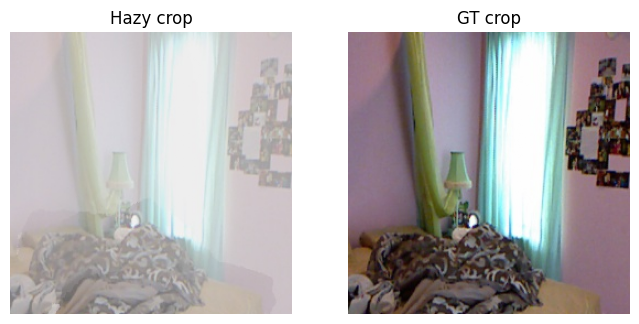

✓ DATA PIPELINE OK


In [8]:
# ============================================================
# CELL 8 — DATALOADERS + BATCH SANITY CHECK
# ============================================================
_schedule = CONFIG["crop_schedule"] or [(CONFIG["crop_size"], CONFIG["batch_size"], 1.0)]
train_sampler = CropBatchSampler(len(train_dataset), _schedule, CONFIG["seed"])


def _worker_init(worker_id):
    # python `random` drives cropping/flipping: give every worker (and every epoch) its own stream
    s = torch.initial_seed() % 2**32
    random.seed(s); np.random.seed(s % 2**32)


train_loader = DataLoader(
    train_dataset, batch_sampler=train_sampler, num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available(), worker_init_fn=_worker_init,
    persistent_workers=CONFIG["num_workers"] > 0)   # the batch plan is drawn in the main process each epoch


def make_eval_loader(ds):
    return DataLoader(ds, batch_size=1, shuffle=False, num_workers=CONFIG["eval_num_workers"],
                      pin_memory=torch.cuda.is_available())


val_loader = make_eval_loader(val_dataset)
test_loader = make_eval_loader(test_dataset)
probe_loader = make_eval_loader(probe_dataset)

print("=" * 65)
print("DATALOADERS")
print("=" * 65)
print(f"Crop schedule: {_schedule}")
print(f"Train batches/epoch: {len(train_loader)} (expected {train_sampler.expected_len}) x accum {CONFIG['grad_accum_steps']}")
print(f"Val images: {len(val_loader)} | Test images: {len(test_loader)} | train-probe images: {len(probe_loader)}")

_h, _g_, _i = next(iter(train_loader))
assert _h.shape == _g_.shape and _h.shape[0] == _i.shape[0], "hazy/GT batch shapes differ"
print(f"Train batch: hazy {tuple(_h.shape)} [{_h.min():.3f}, {_h.max():.3f}] | GT {tuple(_g_.shape)} | idx {_i[:4].tolist()}")
_b = val_dataset[0]
print(f"Val sample: padded hazy {tuple(_b['hazy'].shape)}, GT {tuple(_b['gt'].shape)}, original {_b['h']}x{_b['w']}")
assert _b["gt"].shape[-2:] == (_b["h"], _b["w"])

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(_h[0].permute(1, 2, 0).numpy()); ax[0].set_title("Hazy crop"); ax[0].axis("off")
ax[1].imshow(_g_[0].permute(1, 2, 0).numpy()); ax[1].set_title("GT crop"); ax[1].axis("off")
plt.show()
print("✓ DATA PIPELINE OK")

In [9]:
# ============================================================
# CELL 9 — BUILDING BLOCKS (V3 blocks unchanged + V5 blocks)
# ============================================================
# V3 parameter names/shapes are unchanged, so V3 checkpoints (original run and C_v3_psnr_loss)
# still load with strict=True into arch "v3".
# NEW: haze_cues (parameter-free), LKBlock (large-kernel, statistics-free), ModulatedSkip.
# ============================================================

class LayerNorm2d(nn.Module):
    """Per-pixel LayerNorm over channels (no spatial statistics -> identical for crops and full images)."""

    def __init__(self, channels, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(channels))
        self.bias = nn.Parameter(torch.zeros(channels))
        self.eps = eps

    def forward(self, x):
        xf = x.float()
        mu = xf.mean(1, keepdim=True)
        var = (xf - mu).pow(2).mean(1, keepdim=True)
        y = (xf - mu) * torch.rsqrt(var + self.eps)
        y = y * self.weight.view(1, -1, 1, 1) + self.bias.view(1, -1, 1, 1)
        return y.to(x.dtype)


def make_norm(kind, channels, groups=8):
    if kind == "gn":
        return nn.GroupNorm(min(groups, channels), channels)
    if kind == "ln":
        return LayerNorm2d(channels)
    if kind == "none":
        return nn.Identity()
    raise ValueError(kind)


class ChannelGate(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        hidden = max(channels // reduction, 4)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(nn.Conv2d(channels, hidden, 1), nn.GELU(),
                                nn.Conv2d(hidden, channels, 1), nn.Sigmoid())

    def forward(self, x):
        return x * self.fc(self.pool(x))


class SpatialGate(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, groups=channels, bias=False),
            nn.Conv2d(channels, 1, 1), nn.Sigmoid())

    def forward(self, x):
        return x * self.conv(x)


def _dw_branch(channels, dilation):
    return nn.Sequential(
        nn.Conv2d(channels, channels, 3, padding=dilation, dilation=dilation, groups=channels, bias=False),
        nn.Conv2d(channels, channels, 1), nn.GELU())


class HazeContextBlock(nn.Module):
    """V3 block (unchanged): 3 dilated depthwise branches -> 1x1 fuse -> norm -> channel gate -> spatial gate."""

    def __init__(self, channels, groups=8, norm="gn"):
        super().__init__()
        self.branch1 = _dw_branch(channels, 1)
        self.branch2 = _dw_branch(channels, 2)
        self.branch3 = _dw_branch(channels, 3)
        self.fuse = nn.Conv2d(channels * 3, channels, 1)
        self.norm = make_norm(norm, channels, groups)
        self.channel_gate = ChannelGate(channels)
        self.spatial_gate = SpatialGate(channels)
        self.alpha = nn.Parameter(torch.tensor(0.5))

    def forward(self, x):
        y = torch.cat([self.branch1(x), self.branch2(x), self.branch3(x)], dim=1)
        y = self.norm(self.fuse(y))
        y = self.spatial_gate(self.channel_gate(y))
        return x + self.alpha * y


class GlobalContextBlock(nn.Module):
    def __init__(self, channels, groups=8, norm="gn"):
        super().__init__()
        self.branches = nn.ModuleList([_dw_branch(channels, d) for d in (1, 2, 4, 8)])
        gap_hidden = max(channels // 4, 8)
        self.gap_branch = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(channels, gap_hidden, 1),
                                        nn.GELU(), nn.Conv2d(gap_hidden, channels, 1))
        self.fuse = nn.Conv2d(channels * 5, channels, 1)
        self.norm = make_norm(norm, channels, groups)

    def forward(self, x):
        feats = [b(x) for b in self.branches]
        feats.append(self.gap_branch(x).expand(-1, -1, x.shape[-2], x.shape[-1]))
        return x + self.norm(self.fuse(torch.cat(feats, dim=1)))


class GatedSkip(nn.Module):
    """V3 skip: encoder * sigmoid-gate (can only ATTENUATE encoder features) concatenated with decoder."""

    def __init__(self, channels):
        super().__init__()
        self.gate = nn.Sequential(nn.Conv2d(channels * 2, channels, 1), nn.GELU(),
                                  nn.Conv2d(channels, channels, 1), nn.Sigmoid())
        self.fuse = nn.Conv2d(channels * 2, channels, 1)

    def forward(self, encoder, decoder, cues=None):
        if encoder.shape[-2:] != decoder.shape[-2:]:
            decoder = F.interpolate(decoder, size=encoder.shape[-2:], mode="bilinear", align_corners=False)
        gate = self.gate(torch.cat([encoder, decoder], dim=1))
        return self.fuse(torch.cat([encoder * gate, decoder], dim=1))


# ---------------- parameter-free haze priors ----------------
def dark_channel_prior(x, patch=7):
    """He et al. dark channel. HIGH values = haze / bright veil (haze-free regions have a dark channel near 0)."""
    min_c = x.min(dim=1, keepdim=True)[0]
    return -F.max_pool2d(-min_c, kernel_size=patch, stride=1, padding=patch // 2)


def local_contrast(x, ksize=5):
    pad = ksize // 2
    mean = F.avg_pool2d(x, ksize, stride=1, padding=pad, count_include_pad=False)
    sq_mean = F.avg_pool2d(x * x, ksize, stride=1, padding=pad, count_include_pad=False)
    return (sq_mean - mean * mean).clamp(min=0.0).mean(dim=1, keepdim=True).sqrt()


N_CUES = 3


@torch.no_grad()
def haze_cues(x):
    """(B, 3, H, W) fp32, no parameters: dark channel (haze density cue), 4 x local contrast (haze lowers
    contrast), luminance (separates bright surfaces from veil when combined with the other two)."""
    x = x.float()
    lum = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]
    return torch.cat([dark_channel_prior(x), 4.0 * local_contrast(x), lum], 1)


def pool_to(t, size):
    return t if t.shape[-2:] == tuple(size) else F.adaptive_avg_pool2d(t, size)


# ---------------- V5 blocks ----------------
class LKBlock(nn.Module):
    """Large-kernel block, statistics-free: LN2d -> depthwise 5x5 -> depthwise 3x3 dilation 2 -> MLP.
    Receptive field 9 cells per block; two blocks = 17 cells. At 1/16 resolution that is 272 px, i.e. about
    one 256-px TRAINING crop: every tap is trained on real content, and at test time each position sees the
    same-sized neighbourhood it saw in training (a receptive field larger than the crop would integrate, at
    test time, context from distances it never saw while training). Replicate padding keeps border taps
    on image-like values instead of zeros, for the same reason."""

    def __init__(self, c, expand=2):
        super().__init__()
        self.norm = LayerNorm2d(c)
        self.dw1 = nn.Conv2d(c, c, 5, padding=2, groups=c, padding_mode="replicate")
        self.dw2 = nn.Conv2d(c, c, 3, padding=2, dilation=2, groups=c, padding_mode="replicate")
        self.pw1 = nn.Conv2d(c, c * expand, 1)
        self.act = nn.GELU()
        self.pw2 = nn.Conv2d(c * expand, c, 1)

    def forward(self, x):
        return x + self.pw2(self.act(self.pw1(self.dw2(self.dw1(self.norm(x))))))


class ModulatedSkip(nn.Module):
    """V5 skip.  enc' = enc * (1 + gamma) + beta,  [gamma, beta] = f(decoder, haze cues);  out = fuse([enc', dec]).
    Haze is a per-pixel AFFINE degradation of the scene (I = t J + A (1 - t)), so features of the clean
    scene are, to first order, an affine function of the hazy encoder features with spatially varying
    coefficients. V3's GatedSkip can only multiply encoder features by a gate in (0, 1): it can suppress the
    hazy features but cannot re-amplify contrast attenuated by t or subtract the veil offset. Here the
    decoder (which carries the low-frequency context) predicts both. Zero-init -> starts as plain concat."""

    def __init__(self, c, n_cues=N_CUES):
        super().__init__()
        self.mod = nn.Sequential(
            nn.Conv2d(c + n_cues, c + n_cues, 3, padding=1, groups=c + n_cues, bias=False),
            nn.Conv2d(c + n_cues, 2 * c, 1))
        nn.init.zeros_(self.mod[-1].weight)
        nn.init.zeros_(self.mod[-1].bias)
        self.fuse = nn.Conv2d(2 * c, c, 1)

    def forward(self, encoder, decoder, cues):
        if encoder.shape[-2:] != decoder.shape[-2:]:
            decoder = F.interpolate(decoder, size=encoder.shape[-2:], mode="bilinear", align_corners=False)
        cues = pool_to(cues, encoder.shape[-2:]).to(decoder.dtype)
        gamma, beta = self.mod(torch.cat([decoder, cues], 1)).chunk(2, dim=1)
        enc = encoder * (1.0 + gamma) + beta
        return self.fuse(torch.cat([enc, decoder], 1))


print("Building blocks ready.")

Building blocks ready.


In [10]:
# ============================================================
# CELL 10 — HAZE MODULES: DASFR + global veiling head (V3, unchanged maths)
#           + V5: LowFrequencyContext and PhysicsHead
# ============================================================
# Removed: TransmissionModulationHead / DetailRefiner (presets D/E/F) — never trained, superseded below.
# ============================================================

class DASFR(nn.Module):
    """Degradation-Aware Spatial-Frequency Router (V3), maths unchanged (FFT in fp32 under AMP).
    AUDIT: the spectral gain is 1 + sum_b w_b * band_b(r) with w in (0,1) and bands that sum to 1, so it
    lies in [1, 2]: it can only AMPLIFY, it is the same for every channel and every position, and it has
    3 degrees of freedom per image. A spatially invariant filter cannot correct haze whose density varies
    across the image (where 81% of the test error is). It costs 56.8k params and ~28% of V3's latency."""

    def __init__(self, channels, freq_gain="amplify"):
        super().__init__()
        self.channels, self.freq_gain = channels, freq_gain
        self.severity_head = nn.Sequential(nn.Conv2d(2, 8, 1), nn.GELU(), nn.Conv2d(8, 1, 1), nn.Sigmoid())
        self.spatial_branch = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, groups=channels, bias=False),
            nn.Conv2d(channels, channels, 1), nn.GELU())
        self.band_selector = nn.Sequential(nn.Conv2d(channels, channels, 1), nn.GELU(),
                                           nn.Conv2d(channels, 3, 1), nn.Sigmoid())
        self.freq_channel_refine = nn.Sequential(nn.Conv2d(channels, channels, 1), nn.GELU(),
                                                 nn.Conv2d(channels, channels, 1))
        self.router = nn.Sequential(nn.Conv2d(4, 8, 1), nn.GELU(), nn.Conv2d(8, 4, 1))

    @staticmethod
    def _bands(H, W, dev):
        fy = torch.fft.fftfreq(H, device=dev).view(H, 1)
        fx = torch.fft.rfftfreq(W, device=dev).view(1, W // 2 + 1)
        r = torch.sqrt(fx ** 2 + fy ** 2)
        r = r / (r.max() + 1e-8)
        low = torch.exp(-(r ** 2) / 0.08)
        high = 1.0 - torch.exp(-(r ** 2) / 0.20)
        mid = torch.clamp(1.0 - low - high, min=0.0)
        b = torch.stack([low, mid, high], 0)
        return (b / (b.sum(0, keepdim=True) + 1e-8)).unsqueeze(0)

    def _frequency_correction(self, x):
        B, C, H, W = x.shape
        band_importance = F.adaptive_avg_pool2d(self.band_selector(x).float(), 1)
        with torch.autocast(device_type=x.device.type, enabled=False):
            X = torch.fft.rfft2(x.float(), dim=(-2, -1), norm="ortho")
            w = (self._bands(H, W, x.device) * band_importance).sum(1, keepdim=True)
            gain = (1.0 + w) if self.freq_gain == "amplify" else (2.0 * w)
            y = torch.fft.irfft2(X * gain, s=(H, W), dim=(-2, -1), norm="ortho")
        return self.freq_channel_refine(y)

    def forward(self, x, hazy_ref):
        B, C, H, W = x.shape
        if hazy_ref.shape[-2:] != (H, W):
            hazy_ref = F.interpolate(hazy_ref, size=(H, W), mode="bilinear", align_corners=False)
        severity = self.severity_head(torch.cat([dark_channel_prior(hazy_ref), local_contrast(hazy_ref)], 1))
        y_spatial = self.spatial_branch(x)
        y_freq = self._frequency_correction(x).to(y_spatial.dtype)
        router_in = torch.cat([severity.to(y_spatial.dtype),
                               (y_spatial - y_freq).abs().mean(1, keepdim=True),
                               y_spatial.mean(1, keepdim=True), y_freq.mean(1, keepdim=True)], 1)
        logits = self.router(router_in)
        routes = torch.softmax(logits[:, :3].float(), dim=1).to(x.dtype)
        alpha = torch.sigmoid(logits[:, 3:4])
        x_corrected = routes[:, 0:1] * x + routes[:, 1:2] * y_spatial + routes[:, 2:3] * y_freq
        return x + alpha * (x_corrected - x)


class GlobalVeilingHead(nn.Module):
    """V3: one gain in (0.5, 1.5) and one bias in (-0.25, 0.25) per image and channel.
    AUDIT: undoing haze needs a per-pixel gain 1/t(x); in an oracle test on RESIDE-style haze, 84% (dense)
    / 56% (moderate) of pixels need a gain > 1.5, and even PERFECT global gain/bias only reaches
    14.6 / 19.7 dB (vs 37.0 / 43.8 dB for a perfect transmission map at 1/8 resolution)."""

    def __init__(self, channels, hidden=8):
        super().__init__()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.mlp = nn.Sequential(nn.Conv2d(channels, hidden, 1), nn.GELU(), nn.Conv2d(hidden, 6, 1))

    def forward(self, x):
        p = self.mlp(self.pool(x)).float()
        self.last_p = p.detach()                                  # for saturation diagnostics (CELL 18)
        return 1.0 + 0.5 * torch.tanh(p[:, :3]), 0.25 * torch.tanh(p[:, 3:])


class LowFrequencyContext(nn.Module):
    """V5 — replaces both DASFR routers.
    bottleneck (1/8) -> average-pool to 1/16 -> concat haze cues -> 2 large-kernel blocks -> zero-init 1x1
    -> bilinear back to 1/8, added residually.  Spatially VARYING (unlike DASFR's global spectral gain),
    receptive field ~272 px (one training crop), and no global statistics: a 256-px training crop and a
    region of a full test image are processed the same way."""

    def __init__(self, c, c_lf=64, n_blocks=2):
        super().__init__()
        self.proj_in = nn.Conv2d(c + N_CUES, c_lf, 1)
        self.blocks = nn.Sequential(*[LKBlock(c_lf) for _ in range(n_blocks)])
        self.proj_out = nn.Conv2d(c_lf, c, 1)
        nn.init.zeros_(self.proj_out.weight)
        nn.init.zeros_(self.proj_out.bias)

    def forward(self, b, cues):
        h, w = b.shape[-2:]
        size16 = ((h + 1) // 2, (w + 1) // 2)
        z = torch.cat([F.adaptive_avg_pool2d(b, size16), pool_to(cues, size16).to(b.dtype)], 1)
        z = self.blocks(self.proj_in(z))
        return b + F.interpolate(self.proj_out(z), size=(h, w), mode="bilinear", align_corners=False)


class PhysicsHead(nn.Module):
    """V5 — spatially varying reconstruction (replaces the global gain/bias head).

        J_hat(x) = I(x) + k(x) * (I(x) - a(x))          [+ decoder residual r(x), added by the network]

    With the scattering model I = J t + A (1 - t):  J = I + (1/t - 1)(I - A), i.e. k = 1/t - 1 and a = A.
      * transmission/veil branch: k(x) = exp(s) - 1, s = 3 tanh(z/3) -> k in (-0.95, 19), i.e. t down to 0.05.
        z is predicted at 1/2 resolution from decoder features + haze cues (transmission is smooth inside
        objects) and refined at full resolution by a 1x1 conv on the last decoder features (depth edges).
      * airlight/illumination branch: a(x) = sigmoid(global term + low-resolution spatial term), both from
        the 1/8 bottleneck, so a(x) can only vary at low frequency.
      * restoration branch: the existing full-resolution residual r(x) (decoder output conv).
    k multiplies the INPUT, so input detail is re-amplified by 1/t instead of being re-synthesised.
    Strictly generalises V3's head (constant k, a == global gain/bias). Zero-init: k = 0 at start.
    k and a(x) are kept (eval only) in .last_maps for CELL 22."""

    def __init__(self, c_b, c_half, c_full, hidden=24, s_max=3.0, a_init=0.85):
        super().__init__()
        cin = c_half + N_CUES
        self.t_half = nn.Sequential(
            nn.Conv2d(cin, cin, 3, padding=1, groups=cin, bias=False),
            nn.Conv2d(cin, hidden, 1), nn.GELU(),
            nn.Conv2d(hidden, hidden, 3, padding=2, dilation=2, groups=hidden, bias=False),
            nn.Conv2d(hidden, 1, 1))
        self.t_full = nn.Conv2d(c_full, 1, 1)
        self.a_global = nn.Sequential(nn.Conv2d(c_b, 16, 1), nn.GELU(), nn.Conv2d(16, 3, 1))
        self.a_local = nn.Sequential(nn.Conv2d(c_b, 16, 1), nn.GELU(), nn.Conv2d(16, 3, 1))
        for m in (self.t_half[-1], self.t_full, self.a_local[-1], self.a_global[-1]):
            nn.init.zeros_(m.weight)
            nn.init.zeros_(m.bias)
        nn.init.constant_(self.a_global[-1].bias, math.log(a_init / (1 - a_init)))
        self.s_max = s_max
        self.last_maps = None

    def forward(self, x, b, d2, d1, cues):
        H, W = x.shape[-2:]
        z = self.t_half(torch.cat([d2, pool_to(cues, d2.shape[-2:]).to(d2.dtype)], 1))
        z = F.interpolate(z.float(), size=(H, W), mode="bilinear", align_corners=False) + self.t_full(d1).float()
        s = self.s_max * torch.tanh(z / self.s_max)
        k = torch.expm1(s)
        a_low = self.a_global(b.mean((2, 3), keepdim=True)) + self.a_local(b)
        a = torch.sigmoid(F.interpolate(a_low.float(), size=(H, W), mode="bilinear", align_corners=False))
        xf = x.float()
        if not self.training:
            self.last_maps = {"k": k.detach(), "a": a.detach()}
        return xf + k * (xf - a)


print("DASFR, GlobalVeilingHead, LowFrequencyContext, PhysicsHead ready.")

DASFR, GlobalVeilingHead, LowFrequencyContext, PhysicsHead ready.


In [11]:
# ============================================================
# CELL 11 — HAFR-Net (configurable) + architecture presets
# ============================================================
# "v3" builds EXACTLY HAFR-Net-V3 (same module names, 605,053 parameters, same forward), so the original
# V3 checkpoints and C_v3_psnr_loss load with strict=True.
# Each screening preset changes ONE thing relative to E1:
#   E1 : V3 + eval-only clamp (no zero-gradient clamp in training) + unused aux heads removed
#   P  : E1 + PhysicsHead          (spatial transmission/veil + airlight; replaces the global gain/bias)
#   L  : E1 + LowFrequencyContext  (replaces BOTH DASFR routers)
#   S  : E1 + ModulatedSkip        (replaces the three GatedSkips)
#   V5 : P + L + S
#   V5w: V5 widened to ~0.88M (conditional capacity experiment)
# ============================================================

ARCH_PRESETS = {
    "v3": dict(context="dasfr", head="global", skip="gated", clamp="hard", aux=True),
    "E1": dict(context="dasfr", head="global", skip="gated", clamp="eval", aux=False),
    "P":  dict(context="dasfr", head="phys",   skip="gated", clamp="eval", aux=False),
    "L":  dict(context="lfc",   head="global", skip="gated", clamp="eval", aux=False),
    "S":  dict(context="dasfr", head="global", skip="film",  clamp="eval", aux=False),
    "V5": dict(context="lfc",   head="phys",   skip="film",  clamp="eval", aux=False),
    # capacity follow-up, run ONLY if the train-probe gap says the model under-fits (CELL 21 rule)
    "V5w": dict(context="lfc",  head="phys",   skip="film",  clamp="eval", aux=False,
                channels=(40, 56, 88, 136), lfc_ch=80),
}
ARCH_DESCRIPTIONS = {
    "v3": "HAFR-Net-V3 (original)",
    "E1": "V3 + eval-only clamp, aux heads removed",
    "P":  "E1 + spatial physics head (k(x) transmission/veil, a(x) airlight)",
    "L":  "E1 + low-frequency context module instead of DASFR",
    "S":  "E1 + haze-modulated (FiLM) skip fusion",
    "V5": "P + L + S",
    "V5w": "V5 with wider channels (40/56/88/136) - capacity follow-up",
}


class HAFRNet(nn.Module):
    def __init__(self, context="dasfr", head="global", skip="gated", clamp="hard", aux=True,
                 norm="gn", stem_norm=True, freq_gain="amplify", channels=(32, 48, 72, 112), lfc_ch=64, lfc_blocks=2):
        super().__init__()
        assert context in ("dasfr", "lfc", "none") and head in ("global", "phys") and skip in ("gated", "film")
        C1, C2, C3, C4 = channels
        self.context, self.head, self.skip_kind, self.clamp_mode = context, head, skip, clamp
        Skip = GatedSkip if skip == "gated" else ModulatedSkip
        self.stem = nn.Sequential(
            nn.Conv2d(3, C1, 3, padding=1), nn.GELU(),
            nn.Conv2d(C1, C1, 3, padding=1, groups=C1, bias=False), nn.Conv2d(C1, C1, 1),
            nn.GroupNorm(8, C1) if stem_norm else nn.Identity())
        self.enc1 = HazeContextBlock(C1, norm=norm)
        self.down1 = nn.Conv2d(C1, C2, 3, stride=2, padding=1)
        self.enc2 = HazeContextBlock(C2, norm=norm)
        self.down2 = nn.Conv2d(C2, C3, 3, stride=2, padding=1)
        self.enc3 = HazeContextBlock(C3, norm=norm)
        self.down3 = nn.Conv2d(C3, C4, 3, stride=2, padding=1)
        self.bottleneck_pre = HazeContextBlock(C4, norm=norm)
        self.global_context = GlobalContextBlock(C4, norm=norm)
        if context == "dasfr":
            self.bottleneck_router = DASFR(C4, freq_gain)
        elif context == "lfc":
            self.lf_context = LowFrequencyContext(C4, lfc_ch, lfc_blocks)
        if head == "global":
            self.veiling_head = GlobalVeilingHead(C4)
        self.up3 = nn.Sequential(nn.Conv2d(C4, C3 * 4, 1), nn.PixelShuffle(2))
        self.skip3 = Skip(C3)
        self.dec3 = HazeContextBlock(C3, norm=norm)
        if aux:
            self.aux3 = nn.Conv2d(C3, 3, 3, padding=1)   # unused in V3's forward (never trained)
        self.up2 = nn.Sequential(nn.Conv2d(C3, C2 * 4, 1), nn.PixelShuffle(2))
        self.skip2 = Skip(C2)
        self.dec2 = HazeContextBlock(C2, norm=norm)
        if aux:
            self.aux2 = nn.Conv2d(C2, 3, 3, padding=1)   # unused in V3's forward (never trained)
        self.up1 = nn.Sequential(nn.Conv2d(C2, C1 * 4, 1), nn.PixelShuffle(2))
        self.skip1 = Skip(C1)
        self.dec1 = HazeContextBlock(C1, norm=norm)
        if context == "dasfr":
            self.final_router = DASFR(C1, freq_gain)
        self.out = nn.Conv2d(C1, 3, 3, padding=1)
        if head == "phys":
            self.phys_head = PhysicsHead(C4, C2, C1)
        self.needs_cues = (context == "lfc") or (head == "phys") or (skip == "film")

    def forward(self, x, return_raw=False):
        H, W = x.shape[-2:]
        if H % 8 or W % 8:
            raise ValueError(f"input {H}x{W} must be a multiple of 8 (pad the input, crop the output)")
        cues = haze_cues(x) if self.needs_cues else None
        e1 = self.enc1(self.stem(x))
        e2 = self.enc2(self.down1(e1))
        e3 = self.enc3(self.down2(e2))
        b = self.global_context(self.bottleneck_pre(self.down3(e3)))
        if self.context == "dasfr":
            b = self.bottleneck_router(b, F.adaptive_avg_pool2d(x, b.shape[-2:]))
        elif self.context == "lfc":
            b = self.lf_context(b, cues)
        d3 = self.dec3(self.skip3(e3, self.up3(b), cues))
        d2 = self.dec2(self.skip2(e2, self.up2(d3), cues))
        d1 = self.dec1(self.skip1(e1, self.up1(d2), cues))
        if self.context == "dasfr":
            d1 = self.final_router(d1, F.adaptive_avg_pool2d(x, d1.shape[-2:]))
        residual = self.out(d1).float()
        if self.head == "global":
            gain, bias = self.veiling_head(b)
            out = x.float() * gain + bias + residual
        else:
            out = self.phys_head(x, b, d2, d1, cues) + residual
        if return_raw:
            return out
        if self.clamp_mode == "hard" or (self.clamp_mode == "eval" and not self.training):
            out = out.clamp(0.0, 1.0)
        return out


def build_model(arch, **overrides):
    return HAFRNet(**{**ARCH_PRESETS[arch], **overrides})


def HAFRNetV3():
    return build_model("v3")


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


print("Parameter counts per preset:")
for _a in ARCH_PRESETS:
    _n = count_params(build_model(_a))
    print(f"  {_a:3s} {_n:>9,d}  {'✓ <1M' if _n < 1_000_000 else '✗ >=1M'}  {ARCH_DESCRIPTIONS[_a]}")
    assert _n < 1_000_000
assert count_params(build_model("v3")) == 605_053, "V3 reproduction must have exactly 605,053 parameters"
print("✓ V3 reproduced exactly (605,053 parameters); all presets < 1,000,000")

Parameter counts per preset:
  v3    605,053  ✓ <1M  HAFR-Net-V3 (original)
  E1    601,807  ✓ <1M  V3 + eval-only clamp, aux heads removed
  P     606,548  ✓ <1M  E1 + spatial physics head (k(x) transmission/veil, a(x) airlight)
  L     597,727  ✓ <1M  E1 + low-frequency context module instead of DASFR
  S     595,656  ✓ <1M  E1 + haze-modulated (FiLM) skip fusion
  V5    596,317  ✓ <1M  P + L + S
  V5w   869,678  ✓ <1M  V5 with wider channels (40/56/88/136) - capacity follow-up
✓ V3 reproduced exactly (605,053 parameters); all presets < 1,000,000


In [12]:
# ============================================================
# CELL 11b — HCR-Net: HAZE-CONDITIONED ROUTING NETWORK (new family) + ablation presets
# ============================================================
# Why a new family (evidence from the 60-epoch screens, scene-disjoint val, same schedule):
#   E0 v3 26.41 -> E1 (flip-only, eval clamp) 26.70 (+0.29) -> E5 V5 arch 26.38 (-0.32) -> E6a V5 loss 26.04 (-0.33)
#   The V5 modules did not help. HCR-Net is built from mechanisms with independent support:
#   * RescaleNorm (DehazeFormer): per-sample normalisation whose removed mean/std are RE-INJECTED by the
#     block. GroupNorm (V3) deletes exactly the global brightness/contrast that encodes haze density.
#   * 4 levels (1, 1/2, 1/4, 1/8); 53% of the parameters at 1/8, where 80% of the test error lives (low
#     frequency) and parameters are cheap in MACs; full resolution is light (1 + 1 blocks)
#   * two token mixers per block: local depthwise 3x3 (detail) and dilated depthwise 5x5 (d=3, context)
#   * HAZE-CONDITIONED ROUTING: a one-channel haze field H (features + dark channel / contrast / luminance)
#     decides, per pixel and channel group, how much of each mixer to use. The router's last layer is
#     zero-initialised, so routing STARTS as the static average of the two mixers (= preset HA) and only
#     moves away from it where that lowers the loss.
#   * SK fusion of skips (DehazeFormer), lossless-shape stride-2 2x2 downsampling, PixelShuffle upsampling
#   * soft reconstruction J = I + K(x)*I + B(x) (K: 1 channel, B: 3 channels), zero-initialised -> J = I at start.
#     Note: J = I + R (direct residual) is the special case K = 0, so "hybrid residual + soft" adds nothing
#     beyond soft reconstruction; the only real question is whether the multiplicative K*I term helps (HA vs HC).
# Ablation presets (each differs from HA in ONE mechanism, same widths/depths):
#   HA  : plain dual-mixer U-Net, static fusion 0.5*(local+context), direct residual
#   HB  : HA + haze-conditioned routing
#   HC  : HA + soft reconstruction
#   HD  : HB + HC  (full model)
#   HB0 : HB with routing that does NOT see H (generic SK-style routing) -> does the HAZE map matter?
#   HE  : HD + DASFR frequency refinement at 1/8 scale (optional; run only if frequency is in question)
# ============================================================


class RescaleNorm(nn.Module):
    """RescaleNorm (Song et al., DehazeFormer) for NCHW tensors. Each sample is normalised over (C, H, W); the
    removed std and mean are mapped to per-channel (rescale, rebias) that the block applies to its output, so
    the global intensity statistics (haze density, veil brightness) are not lost. Statistics in fp32."""

    def __init__(self, c, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(1, c, 1, 1))
        self.bias = nn.Parameter(torch.zeros(1, c, 1, 1))
        self.meta_s = nn.Conv2d(1, c, 1)
        self.meta_m = nn.Conv2d(1, c, 1)
        nn.init.trunc_normal_(self.meta_s.weight, std=0.02); nn.init.constant_(self.meta_s.bias, 1.0)
        nn.init.trunc_normal_(self.meta_m.weight, std=0.02); nn.init.constant_(self.meta_m.bias, 0.0)

    def forward(self, x):
        xf = x.float()
        mu = xf.mean(dim=(1, 2, 3), keepdim=True)
        sd = (xf.var(dim=(1, 2, 3), keepdim=True, unbiased=False) + self.eps).sqrt()
        u = ((xf - mu) / sd).to(x.dtype) * self.weight + self.bias
        return u, self.meta_s(sd.to(x.dtype)), self.meta_m(mu.to(x.dtype))


class HazeEstimator(nn.Module):
    """H in [0,1]^(N,1,h,w): a one-channel haze field from the stage input and the physical cues pooled to the
    stage resolution. One estimator per stage; all blocks of the stage are routed by the same H.
    GELU (not ReLU) in this and the other small conditioning MLPs: no unit can be dead from initialisation on."""

    def __init__(self, c, hidden=8):
        super().__init__()
        self.inp = nn.Conv2d(c + N_CUES, hidden, 1)
        self.dw = nn.Conv2d(hidden, hidden, 3, padding=2, dilation=2, groups=hidden, padding_mode="reflect")
        self.out = nn.Conv2d(hidden, 1, 1)

    def forward(self, f, cues):
        z = torch.cat([f, pool_to(cues, f.shape[-2:]).to(f.dtype)], 1)
        return torch.sigmoid(self.out(F.gelu(self.dw(F.gelu(self.inp(z))))))


class HCRBlock(nn.Module):
    """x -> x + Mix(RN(x))*s1 + b1 -> x + FFN(RN(x))*s2 + b2.
    Mix: v = W_in u;  l = DW3x3(v);  g = DW5x5,d3(v);  [w_l, w_g] = softmax_2(R([u, H]))  per pixel, per group;
         m = w_l*l + w_g*g;  out = W_out m.   route='static' uses w_l = w_g = 1/2."""

    def __init__(self, c, route="haze", ffn=2, groups=4, k_ctx=5, d_ctx=3):
        super().__init__()
        assert route in ("static", "haze", "nohaze") and c % groups == 0
        self.route, self.groups = route, groups
        self.norm1 = RescaleNorm(c)
        self.pw_in = nn.Conv2d(c, c, 1)
        self.local = nn.Conv2d(c, c, 3, padding=1, groups=c, padding_mode="reflect")
        self.ctx = nn.Conv2d(c, c, k_ctx, padding=d_ctx * (k_ctx // 2), dilation=d_ctx, groups=c,
                             padding_mode="reflect")
        if route != "static":
            hid = max(8, c // 4)
            self.router = nn.Sequential(nn.Conv2d(c + (1 if route == "haze" else 0), hid, 1), nn.GELU(),
                                        nn.Conv2d(hid, 2 * groups, 1))
            nn.init.zeros_(self.router[2].weight); nn.init.zeros_(self.router[2].bias)   # start = static fusion
        self.pw_out = nn.Conv2d(c, c, 1)
        self.norm2 = RescaleNorm(c)
        self.ffn = nn.Sequential(nn.Conv2d(c, c * ffn, 1), nn.ReLU(), nn.Conv2d(c * ffn, c, 1))
        self.last_w = None                                         # routing weight of the local mixer (diagnostics)

    def forward(self, x, H=None):
        u, s1, b1 = self.norm1(x)
        v = self.pw_in(u)
        l, g = self.local(v), self.ctx(v)
        if self.route == "static":
            m = 0.5 * (l + g)
        else:
            r_in = torch.cat([u, H.to(u.dtype)], 1) if self.route == "haze" else u
            n, c, h, w = l.shape
            # reshape (not view): works for any memory layout, incl. channels_last (CELL 12 times both)
            wts = self.router(r_in).float().reshape(n, 2, self.groups, 1, h, w).softmax(dim=1).to(l.dtype)
            m = (wts[:, 0] * l.reshape(n, self.groups, c // self.groups, h, w)
                 + wts[:, 1] * g.reshape(n, self.groups, c // self.groups, h, w)).reshape(n, c, h, w)
            self.last_w = wts[:, 0, :, 0].detach()
        x = x + self.pw_out(m) * s1 + b1
        u2, s2, b2 = self.norm2(x)
        return x + self.ffn(u2) * s2 + b2


class HCRStage(nn.Module):
    def __init__(self, c, depth, route, **kw):
        super().__init__()
        self.est = HazeEstimator(c) if route == "haze" else None
        self.blocks = nn.ModuleList([HCRBlock(c, route=route, **kw) for _ in range(depth)])
        self.last_H = None

    def forward(self, x, cues):
        H = self.est(x, cues) if self.est is not None else None
        self.last_H = H.detach() if H is not None else None
        for b in self.blocks:
            x = b(x, H)
        return x


class SKFusion(nn.Module):
    """Selective-kernel fusion of decoder and skip features (DehazeFormer): channel-wise softmax over 2 inputs.
    GELU and >= 8 hidden units instead of DehazeFormer's ReLU/4: the MLP sees ONE pooled vector per image, and a
    4-unit bias-free ReLU layer can be entirely dead at initialisation (caught by sanity check [5]), which would
    freeze the fusion at 50/50 for the whole run."""

    def __init__(self, c, reduction=8):
        super().__init__()
        d = max(c // reduction, 8)
        self.mlp = nn.Sequential(nn.Conv2d(c, d, 1, bias=False), nn.GELU(), nn.Conv2d(d, 2 * c, 1, bias=False))

    def forward(self, a, b):
        n, c = a.shape[:2]
        w = self.mlp(F.adaptive_avg_pool2d(a + b, 1)).float().reshape(n, 2, c, 1, 1).softmax(dim=1).to(a.dtype)
        return w[:, 0] * a + w[:, 1] * b


class HCRNet(nn.Module):
    """U-Net with len(widths) levels (full, 1/2, 1/4, 1/8 ...). depths = (enc_1..enc_{L-1}, mid, dec_{L-1}..dec_1)."""

    def __init__(self, route="haze", recon="soft", widths=(24, 48, 80, 128), depths=(1, 2, 2, 4, 2, 2, 1), ffn=2,
                 groups=4, freq=False, clamp="eval"):
        super().__init__()
        assert recon in ("soft", "residual") and len(depths) == 2 * len(widths) - 1
        L = len(widths)
        self.route, self.recon, self.clamp_mode, self.levels = route, recon, clamp, L
        self.context, self.head = "hcr", None                       # (other cells check these attributes)
        kw = dict(ffn=ffn, groups=groups)
        self.stem = nn.Conv2d(3 + N_CUES, widths[0], 3, padding=1, padding_mode="reflect")
        self.enc = nn.ModuleList([HCRStage(widths[i], depths[i], route, **kw) for i in range(L - 1)])
        self.down = nn.ModuleList([nn.Conv2d(widths[i], widths[i + 1], 2, stride=2) for i in range(L - 1)])
        self.mid = HCRStage(widths[-1], depths[L - 1], route, **kw)
        self.freq = DASFR(widths[-1], "amplify") if freq else None
        self.up = nn.ModuleList([nn.Sequential(nn.Conv2d(widths[i + 1], widths[i] * 4, 1), nn.PixelShuffle(2))
                                 for i in reversed(range(L - 1))])
        self.fuse = nn.ModuleList([SKFusion(widths[i]) for i in reversed(range(L - 1))])
        self.dec = nn.ModuleList([HCRStage(widths[i], depths[2 * L - 2 - i], route, **kw)
                                  for i in reversed(range(L - 1))])
        self.out = nn.Conv2d(widths[0], 4 if recon == "soft" else 3, 3, padding=1, padding_mode="reflect")
        nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)    # J = I at initialisation
        self.multiple = 2 ** (L - 1)

    def forward(self, x, return_raw=False):
        if x.shape[-2] % self.multiple or x.shape[-1] % self.multiple:
            raise ValueError(f"input {tuple(x.shape[-2:])} must be a multiple of {self.multiple} (pad, then crop)")
        cues = haze_cues(x)
        f = self.stem(torch.cat([x, cues.to(x.dtype)], 1))
        skips = []
        for enc, down in zip(self.enc, self.down):
            f = enc(f, cues)
            skips.append(f)
            f = down(f)
        f = self.mid(f, cues)
        if self.freq is not None:
            f = self.freq(f, F.adaptive_avg_pool2d(x, f.shape[-2:]))
        for up, fuse, dec in zip(self.up, self.fuse, self.dec):
            f = dec(fuse(up(f), skips.pop()), cues)
        o = self.out(f).float()
        xf = x.float()
        if self.recon == "soft":
            out = xf + o[:, :1] * xf + o[:, 1:]                       # J = I + K*I + B
        else:
            out = xf + o                                               # J = I + R
        if return_raw:
            return out
        if self.clamp_mode == "hard" or (self.clamp_mode == "eval" and not self.training):
            out = out.clamp(0.0, 1.0)
        return out


HCR_PRESETS = {
    "HA":  dict(route="static", recon="residual"),
    "HB":  dict(route="haze",   recon="residual"),
    "HC":  dict(route="static", recon="soft"),
    "HD":  dict(route="haze",   recon="soft"),
    "HB0": dict(route="nohaze", recon="residual"),
    "HE":  dict(route="haze",   recon="soft", freq=True),
    # MAX: the full model and its plain counterpart, widened to use the 1M budget
    "HX":  dict(route="haze",   recon="soft",     widths=(24, 48, 96, 136)),
    "HXA": dict(route="static", recon="residual", widths=(24, 48, 96, 136)),
}
HCR_DESCRIPTIONS = {
    "HA":  "HCR plain: dual mixer, static fusion, direct residual",
    "HB":  "HA + haze-conditioned routing",
    "HC":  "HA + soft reconstruction (K*I + B)",
    "HD":  "HCR-Net full: routing + soft reconstruction",
    "HB0": "HB but routing without the haze map (generic routing)",
    "HE":  "HD + DASFR frequency refinement at 1/8 scale",
    "HX":  "HCR-Net MAX: HD widened to (24, 48, 96, 136)",
    "HXA": "HX without routing and soft reconstruction (plain, same widths)",
}
ARCH_PRESETS.update(HCR_PRESETS)
ARCH_DESCRIPTIONS.update(HCR_DESCRIPTIONS)
if "_build_hafr" not in globals():
    _build_hafr = build_model


def build_model(arch, **overrides):
    if arch in HCR_PRESETS:
        return HCRNet(**{**HCR_PRESETS[arch], **overrides})
    return _build_hafr(arch, **overrides)


def param_table(m):
    rows = [(name, sum(p.numel() for p in mod.parameters())) for name, mod in m.named_children()]
    return rows + [("TOTAL", count_params(m))]


print("HCR-Net presets (exact trainable parameters):")
for _a in HCR_PRESETS:
    _n = count_params(build_model(_a))
    print(f"  {_a:3s} {_n:>9,d}  {'✓ <1M' if _n < 1_000_000 else '✗ >=1M'}  {HCR_DESCRIPTIONS[_a]}")
    assert _n < 1_000_000
print("HD per module:", ", ".join(f"{k} {v:,d}" for k, v in param_table(build_model("HD"))))

HCR-Net presets (exact trainable parameters):
  HA    794,659  ✓ <1M  HCR plain: dual mixer, static fusion, direct residual
  HB    827,266  ✓ <1M  HA + haze-conditioned routing
  HC    794,876  ✓ <1M  HA + soft reconstruction (K*I + B)
  HD    827,483  ✓ <1M  HCR-Net full: routing + soft reconstruction
  HB0   822,691  ✓ <1M  HB but routing without the haze map (generic routing)
  HE    895,179  ✓ <1M  HD + DASFR frequency refinement at 1/8 scale
  HX    986,147  ✓ <1M  HCR-Net MAX: HD widened to (24, 48, 96, 136)
  HXA   947,835  ✓ <1M  HX without routing and soft reconstruction (plain, same widths)
HD per module: stem 1,320, enc 129,627, down 61,184, mid 439,193, up 61,536, fuse 4,128, dec 129,627, out 868, TOTAL 827,483


In [13]:
# ============================================================
# CELL 12 — MODEL SUMMARY + COMPLEXITY (params by module, MACs, FFT FLOPs, latency, memory, train-step time)
# ============================================================
# Fixes vs the previous version: peak memory is now the INCREASE caused by the forward pass (the old
# number, ~3.2 GB at 256x256, was dominated by tensors allocated earlier in the notebook); DASFR's FFT
# work is estimated separately (FlopCounterMode does not count FFTs); the training-step time with AMP is
# measured, because that, not inference latency, sets how many experiments fit in the GPU budget.
# ============================================================
from torch.utils.flop_counter import FlopCounterMode

COMPLEXITY_SIZES = [(256, 256), (464, 624)]   # 464x624 = a 460x620 SOTS-indoor image padded to /8
PLAN_ARCHS = list(dict.fromkeys([CONFIG["arch"], "E1", "HD"]))   # (short list: this cell runs every session)


def fft_gflops(m, H, W):
    """Rough FLOPs of DASFR's rfft2 + irfft2 (2.5 N log2 N per real 2-D transform and channel)."""
    if getattr(m, "context", None) != "dasfr":
        return 0.0
    tot = 0.0
    for C, s in [(m.bottleneck_router.channels, 8), (m.final_router.channels, 1)]:
        n = (H // s) * (W // s)
        tot += 2 * C * 2.5 * n * math.log2(max(n, 2))
    return tot / 1e9


@torch.no_grad()
def measure_complexity(m, sizes=COMPLEXITY_SIZES, n_warmup=None, n_runs=20):
    m = m.to(device).eval()
    n_warmup = n_warmup if n_warmup is not None else (5 if device.type == "cuda" else 1)
    res = {"params": count_params(m)}
    for (H, W) in sizes:
        x = torch.rand(1, 3, H, W, device=device)
        with FlopCounterMode(display=False) as fc:
            m(x)
        res[f"gmacs_{H}x{W}"] = fc.get_total_flops() / 2e9          # conv/matmul MACs
        res[f"fft_gflops_{H}x{W}"] = fft_gflops(m, H, W)
        for amp in ([False, True] if device.type == "cuda" else [False]):
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
                for _ in range(n_warmup):
                    m(x)
                if device.type == "cuda":
                    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
                base = torch.cuda.memory_allocated() if device.type == "cuda" else 0
                times = []
                for _ in range(n_runs):
                    t0 = time.perf_counter(); m(x)
                    if device.type == "cuda":
                        torch.cuda.synchronize()
                    times.append((time.perf_counter() - t0) * 1000)
            tag = "fp16" if amp else "fp32"
            res[f"latency_ms_{tag}_{H}x{W}"] = float(np.median(times))
            if device.type == "cuda":
                res[f"act_mem_MB_{tag}_{H}x{W}"] = (torch.cuda.max_memory_allocated() - base) / 2**20
    res["weights_MB_fp32"] = sum(p.numel() * 4 for p in m.parameters()) / 2**20
    return res


def train_step_ms(arch, bs=8, crop=256, channels_last=False, n=10):
    """Median wall time of one AMP training step (forward + backward + AdamW) on random data."""
    if device.type != "cuda":
        return float("nan")
    m = build_model(arch).to(device).train()
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)
    scaler = torch.amp.GradScaler("cuda")
    x = torch.rand(bs, 3, crop, crop, device=device); y = torch.rand_like(x)
    if channels_last:
        m = m.to(memory_format=torch.channels_last); x = x.contiguous(memory_format=torch.channels_last)
    times = []
    for i in range(n + 3):
        torch.cuda.synchronize(); t0 = time.perf_counter()
        with torch.autocast("cuda", dtype=torch.float16):
            out = m(x)
        loss = F.mse_loss(out.float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        torch.cuda.synchronize()
        if i >= 3:
            times.append((time.perf_counter() - t0) * 1000)
    del m, opt
    torch.cuda.empty_cache()
    return float(np.median(times))


model = build_model(CONFIG["arch"]).to(device)
print("=" * 65)
print(f"PARAMETER BREAKDOWN — arch '{CONFIG['arch']}': {ARCH_DESCRIPTIONS[CONFIG['arch']]}")
print("=" * 65)
for name, mod in model.named_children():
    print(f"{name:22s} {sum(p.numel() for p in mod.parameters()):>9,d}")
n_params = count_params(model)
print("-" * 65)
print(f"Trainable params: {n_params:,d} ({n_params / 1e6:.3f} M)")
assert n_params < 1_000_000, "HARD CONSTRAINT VIOLATED: >= 1M parameters"

_complexity_path = os.path.join(CONFIG["results_dir"], "complexity.csv")
_steps = train_sampler.expected_len
_rows = []
for _a in PLAN_ARCHS:
    r = measure_complexity(build_model(_a), n_runs=(20 if device.type == "cuda" else 1))
    r["arch"] = _a
    if device.type == "cuda":
        r["train_step_ms"] = train_step_ms(_a)
        r["train_step_ms_channels_last"] = train_step_ms(_a, channels_last=True)
        r["est_min_per_epoch"] = r["train_step_ms"] * _steps / 60000
    _rows.append(r)
complexity_df = pd.DataFrame(_rows).set_index("arch")
complexity_df.to_csv(_complexity_path + f".{os.getpid()}.tmp")       # atomic (2-GPU mode)
os.replace(_complexity_path + f".{os.getpid()}.tmp", _complexity_path)
pd.set_option("display.width", 250)
print("\nComplexity per preset (MACs = conv/matmul; DASFR FFT FLOPs listed separately; latency = median, batch 1;"
      "\nact_mem = activation memory added by one forward; est_min_per_epoch excludes validation):")
print(complexity_df.round(3).T.to_string())

PARAMETER BREAKDOWN — arch 'HX': HCR-Net MAX: HD widened to (24, 48, 96, 136)
stem                       1,320
enc                      166,731
down                      75,544
mid                      493,833
up                        75,936
fuse                       5,184
dec                      166,731
out                          868
-----------------------------------------------------------------
Trainable params: 986,147 (0.986 M)

Complexity per preset (MACs = conv/matmul; DASFR FFT FLOPs listed separately; latency = median, batch 1;
act_mem = activation memory added by one forward; est_min_per_epoch excludes validation):
arch                                 HX          E1          HD
params                       986147.000  601807.000  827483.000
gmacs_256x256                     3.760       3.750       3.358
fft_gflops_256x256                0.000       0.174       0.000
latency_ms_fp32_256x256          22.167      15.890      22.379
act_mem_MB_fp32_256x256          82.002 

In [14]:
# ============================================================
# CELL 13 — EMA
# ============================================================
# Same update rule and checkpoint format as before (so C_v3_psnr_loss's EMA still loads), but the update
# is done with fused _foreach ops over cached tensor lists instead of rebuilding two state_dicts every
# step. The sanity cell checks it against the plain formula and checks save/restore.
# AUDIT: decay 0.999 per step = ~1,000-step (1.5-epoch) horizon. At the end of a cosine run (LR ~1e-6)
# EMA and raw weights are almost identical, so EMA cannot explain a final-number difference; it only
# smooths the validation curve used for checkpoint selection. CELL 18 measures EMA vs raw.
# ============================================================

class ModelEMA:
    def __init__(self, model, decay=0.999, warmup=False):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay, self.warmup, self.updates = decay, warmup, 0
        self._pairs = None

    def _build(self, model):
        # Parameter / buffer OBJECTS (not state_dict views): they stay valid if .data is replaced later
        src = {**dict(model.named_parameters()), **dict(model.named_buffers())}
        dst = {**dict(self.module.named_parameters()), **dict(self.module.named_buffers())}
        assert src.keys() == dst.keys(), "EMA and model have different parameters"
        keys = list(dst)
        self._f_src = [src[k] for k in keys if dst[k].dtype.is_floating_point]
        self._f_dst = [dst[k] for k in keys if dst[k].dtype.is_floating_point]
        self._o_src = [src[k] for k in keys if not dst[k].dtype.is_floating_point]
        self._o_dst = [dst[k] for k in keys if not dst[k].dtype.is_floating_point]
        self._pairs = id(model)

    @torch.no_grad()
    def update(self, model):
        if self._pairs != id(model):
            self._build(model)
        self.updates += 1
        d = min(self.decay, (1 + self.updates) / (10 + self.updates)) if self.warmup else self.decay
        torch._foreach_mul_(self._f_dst, d)
        torch._foreach_add_(self._f_dst, self._f_src, alpha=1.0 - d)
        for a, b in zip(self._o_dst, self._o_src):
            a.copy_(b)

    def state_dict(self):
        return {"module": self.module.state_dict(), "updates": self.updates}

    def load_state_dict(self, sd):
        self.module.load_state_dict(sd["module"])
        self.updates = sd.get("updates", 0)
        self._pairs = None


print("EMA ready.")

EMA ready.


In [15]:
# ============================================================
# CELL 14 — CHECKPOINT UTILITIES (legacy V3 + per-experiment)
# ============================================================
# AUDIT: in the C_v3_psnr_loss session no V3 checkpoint was attached ({'best': None, 'last': None}), so
# Stage 0 never ran and the 27.7508 -> 27.6453 comparison mixed two DIFFERENT code paths (the original
# notebook's evaluation vs this notebook's re-implementation). R0 (CELL 18) closes that gap.
# The search is wider now (several input layouts), and still accepts only checkpoints written by the
# ORIGINAL V3 notebook (they carry 'val_psnrs').
# ============================================================

def _torch_load(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


def find_legacy_v3_checkpoints():
    found = {"best": None, "last": None}
    cands = list(CONFIG["legacy_v3_checkpoints"])
    for pat in CONFIG["legacy_v3_search_globs"]:
        cands += sorted(glob.glob(pat))
    for p in dict.fromkeys(cands):
        if not os.path.isfile(p):
            continue
        try:
            if "val_psnrs" not in _torch_load(p):
                continue
        except Exception:
            continue
        n = Path(p).name.lower()
        if "best" in n and found["best"] is None:
            found["best"] = p
        elif "last" in n and found["last"] is None:
            found["last"] = p
    return found


def experiment_checkpoint(exp, which="best"):
    p = os.path.join(CONFIG["checkpoint_root"], exp, "best_psnr.pth" if which == "best" else "last.pth")
    return p if os.path.isfile(p) else None


def load_weights(model, path, use_ema=True, strict=True):
    ck = _torch_load(path)
    if isinstance(ck, dict) and ("ema" in ck or "model" in ck):
        sd = ck["ema"] if (use_ema and "ema" in ck) else ck["model"]
        if isinstance(sd, dict) and "module" in sd and isinstance(sd["module"], dict):
            sd = sd["module"]
    else:
        sd = ck
    missing, unexpected = model.load_state_dict(sd, strict=strict)
    return ck, missing, unexpected


def arch_of_checkpoint(ck, default="v3"):
    cfg = ck.get("config", {}) if isinstance(ck, dict) else {}
    return cfg.get("arch", default)


LEGACY = find_legacy_v3_checkpoints()
print("Legacy V3 checkpoints:", LEGACY)
if LEGACY["best"] is None and LEGACY["last"] is None:
    print("⚠ No ORIGINAL V3 checkpoint found -> the legacy reproducibility test (R0) cannot run.\n"
          "  Attach the old notebook version's output (HAFR_checkpoints/best_psnr.pth and last.pth) as an input.")

Legacy V3 checkpoints: {'best': None, 'last': None}
⚠ No ORIGINAL V3 checkpoint found -> the legacy reproducibility test (R0) cannot run.
  Attach the old notebook version's output (HAFR_checkpoints/best_psnr.pth and last.pth) as an input.


In [16]:
# ============================================================
# CELL 15 — LOSSES (metric-aligned main term, gradient-balanced SSIM, optional staged curriculum)
# ============================================================
# The benchmark metric is the MEAN over IMAGES of PSNR_j = -10 log10(MSE_j). Its gradient w.r.t. the
# prediction of image j is proportional to e_j / MSE_j: every pixel of the SAME image has the same weight,
# and images are weighted by 1/MSE_j.
#
# AUDIT of the previous "psnr" loss = mean over 256-px CROPS of 10 log10(MSE_crop):
#   * it weights each CROP by 1/MSE_crop. Inside one image, an easy crop (sky, wall, thin haze) gets far
#     more weight than the crop holding the image's dense-haze / bright-surface error, although that
#     crop dominates the image's PSNR. Offline (error field like CELL 22's worst maps): easiest crop 8.5x
#     the weight of the hardest crop of the same image; gradient energy on the high-error region drops
#     from 91% (metric) to 75%.
#   * from the C_v3_psnr_loss log: mean crop PSNR 29.64 vs PSNR of the mean crop MSE 27.14 -> crop PSNRs
#     spread with a std of ~4.7 dB, so a crop 1 std easier than average gets ~2.9x the gradient of one
#     1 std harder. The error that dominates (low-frequency, dense haze, indoor) sits in the hard crops.
#   * SSIM had no term at all -> legacy-protocol SSIM fell 0.9587 -> 0.9481.
#
# NEW main term "img_psnr": per-crop MSE weighted by 1 / (running estimate of ITS IMAGE's MSE). This is the
#   metric's own weighting: images by 1/MSE_j, crops of the same image equally. The estimate is an
#   exponential average of that image's crop MSEs over epochs (stored per image index, checkpointed).
# Auxiliary terms — only one survives the justification test:
#   * SSIM: secondary metric that collapsed when removed. Weight is NOT hand-picked: it is re-measured
#     every 25 steps so that ||dL_ssim/dpred|| = ssim_share x ||dL_main/dpred|| (default 0.10). Under V3's
#     loss SSIM was 83% of the gradient; here it is capped at ~9%.
#   * low-frequency / colour terms: NOT added. MSE already weights every frequency band and every colour
#     channel exactly as PSNR does (Parseval); extra terms would only move the objective away from PSNR.
#   * gradient / edge / frequency terms: NOT added — high-band error is 3.6% of the test MSE.
# Staged curriculum ("v5_staged"), tested against the fixed loss in E6b vs E6a:
#   A (first 30%):  Charbonnier + SSIM share 0.20  - robust to the very large early errors of dense haze
#   B (30-85%):     img_psnr    + SSIM share 0.10  - PSNR-focused
#   C (last 15%):   img_psnr only                  - low-LR MSE fine-tuning (the cosine LR is already low)
# ============================================================

class CharbonnierLoss(nn.Module):
    def __init__(self, eps=1e-3):
        super().__init__()
        self.eps = eps

    def forward(self, pred, target):
        d = pred - target
        return torch.sqrt(d * d + self.eps * self.eps).mean()


charbonnier = CharbonnierLoss()


def edge_map(x):
    gray = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]
    gx = F.pad(gray[:, :, :, 2:] - gray[:, :, :, :-2], (1, 1, 0, 0))
    gy = F.pad(gray[:, :, 2:, :] - gray[:, :, :-2, :], (0, 0, 1, 1))
    return torch.sqrt(gx * gx + gy * gy + 1e-6)


def edge_loss(pred, target):
    return F.l1_loss(edge_map(pred), edge_map(target))


def frequency_loss(pred, target):
    return F.l1_loss(torch.fft.rfft2(pred, norm="ortho").abs(), torch.fft.rfft2(target, norm="ortho").abs())


def ssim_loss(pred, target):
    return 1.0 - torch_ssim(pred, target, data_range=1.0, size_average=True)


def per_sample_mse(pred, target):
    return (pred - target).pow(2).flatten(1).mean(1)


def psnr_loss(pred, target):
    """Previous loss (C_v3_psnr_loss): -PSNR averaged over CROPS."""
    return (10.0 / math.log(10.0)) * torch.log(per_sample_mse(pred, target) + 1e-10).mean()


V3_BUG_WEIGHTS = {"mse": 1.0, "charb": 0.5, "ssim": 0.35, "freq": 0.08, "edge": 0.05}
TERM_FNS = {"mse": F.mse_loss, "charb": charbonnier, "ssim": ssim_loss, "freq": frequency_loss, "edge": edge_loss}


class ImageMSETable:
    """Running per-image MSE (one entry per training image)."""

    def __init__(self, n, momentum=0.5):
        self.v = torch.full((n,), float("nan"))
        self.m = momentum

    @torch.no_grad()
    def weights(self, idx, crop_mse):
        if self.v.device != crop_mse.device:
            self.v = self.v.to(crop_mse.device)
        idx = idx.to(crop_mse.device)
        cm = crop_mse.detach().float()
        prev = self.v[idx]
        known = ~torch.isnan(prev)
        est = torch.where(known, prev, cm)                     # weight from the image's PAST error if known
        w = 1.0 / est.clamp_min(1e-5)
        w = (w / w.mean()).clamp(max=8.0)
        w = w / w.mean()
        self.v[idx] = torch.where(known, self.m * prev + (1 - self.m) * cm, cm)
        return w

    def state_dict(self):
        return {"v": self.v.cpu(), "m": self.m}

    def load_state_dict(self, sd):
        self.v, self.m = sd["v"].clone(), sd["m"]


class GradShareBalancer:
    """w_aux = share * ||dL_main/dpred|| / ||dL_aux/dpred||, measured on the OUTPUT (cheap), EMA-smoothed."""

    def __init__(self, every=25, beta=0.9):
        self.every, self.beta, self.ratio, self.n = every, beta, None, 0

    def weight(self, share, main, aux, pred):
        if share <= 0:
            return 0.0
        if pred.requires_grad and (self.ratio is None or self.n % self.every == 0):
            g1 = torch.autograd.grad(main, pred, retain_graph=True)[0].norm()
            g2 = torch.autograd.grad(aux, pred, retain_graph=True)[0].norm()
            r = float(g1 / (g2 + 1e-12))
            if math.isfinite(r):
                self.ratio = r if self.ratio is None else self.beta * self.ratio + (1 - self.beta) * r
        self.n += 1
        return share * (self.ratio if self.ratio is not None else 0.0)

    def state_dict(self):
        return {"ratio": self.ratio, "n": self.n}

    def load_state_dict(self, sd):
        self.ratio, self.n = sd["ratio"], sd["n"]


# Stage-2 presets: pixel term + FIXED small weights (pixel, w_ssim, w_edge); SSIM never dominates.
FIXED_WEIGHT_LOSSES = {
    "charb_ssim05": ("charb", 0.05, 0.0), "charb_ssim10": ("charb", 0.10, 0.0), "mse_ssim05": ("mse", 0.05, 0.0),
    "charb_edge05": ("charb", 0.0, 0.05), "mse_edge05": ("mse", 0.0, 0.05), "psnr_edge05": ("psnr", 0.0, 0.05),
}


def loss_plan(preset, epoch, total, cfg):
    f = (epoch - 1) / max(total, 1)
    b0, b1 = cfg["stage_bounds"]
    if preset == "v5_staged":
        if f < b0:
            return {"main": "charb", "ssim_share": 2 * cfg["ssim_share"], "stage": "A"}
        if f < b1:
            return {"main": "img_psnr", "ssim_share": cfg["ssim_share"], "stage": "B"}
        return {"main": "img_psnr", "ssim_share": 0.0, "stage": "C"}
    if preset == "v5_fixed":
        return {"main": "img_psnr", "ssim_share": cfg["ssim_share"], "stage": "-"}
    if preset in FIXED_WEIGHT_LOSSES:
        _m, _ws, _we = FIXED_WEIGHT_LOSSES[preset]
        return {"main": _m, "ssim_share": 0.0, "ssim_w": _ws, "edge_w": _we, "stage": "-"}
    if preset in ("psnr", "mse", "charb", "img_psnr", "v3_bug"):
        return {"main": preset, "ssim_share": 0.0, "stage": "-"}
    raise ValueError(f"unknown loss preset {preset}")


class HazeLoss:
    def __init__(self, preset, total_epochs, n_train, cfg):
        self.preset, self.total, self.cfg = preset, total_epochs, cfg
        self.table = ImageMSETable(n_train, cfg["img_mse_momentum"])
        self.balancer = GradShareBalancer()
        loss_plan(preset, 1, total_epochs, cfg)                   # validate the name early
        self.last_w_ssim = 0.0

    def plan(self, epoch):
        return loss_plan(self.preset, epoch, self.total, self.cfg)

    def __call__(self, pred, target, epoch, idx=None):
        if not isinstance(epoch, int) or not (1 <= epoch <= self.total):
            raise ValueError(f"loss needs the current epoch (1..{self.total}), got {epoch!r}")
        pred, target = pred.float(), target.float()
        p = self.plan(epoch)
        per = per_sample_mse(pred, target)
        comps = {"mse": per.mean().detach(),
                 "crop_psnr": (-10.0 * torch.log10(per.detach() + 1e-10)).mean()}
        m = p["main"]
        w_img = self.table.weights(idx, per) if idx is not None else None   # table updated in every stage
        if m == "psnr":
            main = (10.0 / math.log(10.0)) * torch.log(per + 1e-10).mean()
        elif m == "mse":
            main = per.mean()
        elif m == "charb":
            main = charbonnier(pred, target)
        elif m == "img_psnr":
            if idx is None:
                raise ValueError("img_psnr needs the image indices of the batch")
            main = (w_img * per).mean()
        elif m == "v3_bug":
            main = sum(w * TERM_FNS[k](pred, target) for k, w in V3_BUG_WEIGHTS.items())
        comps["main"] = main.detach()
        loss = main
        if p["ssim_share"] > 0:
            s = ssim_loss(pred, target)
            w = self.balancer.weight(p["ssim_share"], main, s, pred)
            loss = loss + w * s
            comps["ssim_loss"] = s.detach()
            self.last_w_ssim = w
        else:
            self.last_w_ssim = 0.0
        if p.get("ssim_w", 0) > 0:
            s = ssim_loss(pred, target)
            loss = loss + p["ssim_w"] * s
            comps["ssim_loss"] = s.detach()
            self.last_w_ssim = p["ssim_w"]
        if p.get("edge_w", 0) > 0:
            e_ = edge_loss(pred, target)
            loss = loss + p["edge_w"] * e_
            comps["edge_loss"] = e_.detach()
        return loss, comps

    def state_dict(self):
        return {"table": self.table.state_dict(), "balancer": self.balancer.state_dict()}

    def load_state_dict(self, sd):
        self.table.load_state_dict(sd["table"]); self.balancer.load_state_dict(sd["balancer"])


loss_fn = HazeLoss(CONFIG["loss"], CONFIG["epochs"], len(train_dataset), CONFIG)
print(f"Loss preset '{CONFIG['loss']}':")
for e in sorted({1, max(1, int(CONFIG["epochs"] * 0.5)), CONFIG["epochs"]}):
    print(f"  epoch {e:4d}: {loss_fn.plan(e)}")

Loss preset 'psnr':
  epoch    1: {'main': 'psnr', 'ssim_share': 0.0, 'stage': '-'}
  epoch  250: {'main': 'psnr', 'ssim_share': 0.0, 'stage': '-'}
  epoch  500: {'main': 'psnr', 'ssim_share': 0.0, 'stage': '-'}


In [17]:
# ============================================================
# CELL 16 — OPTIMIZER + SCHEDULER (per-iteration)
# ============================================================
# V3: AdamW(2e-4, wd 1e-4) on every parameter, LinearLR warm-up (8 epochs) -> cosine to 1e-6,
# stepped once per EPOCH. The LR printed in V3's log was the NEXT epoch's LR (printed after
# scheduler.step()).
# Here: the same shape stepped per ITERATION (smooth), plus the Stage-4 alternatives. The LR
# logged for an epoch is the LR actually used during that epoch.
# Note on V3's weight decay: AdamW shrinks weights by lr*wd per step = 2e-8 at the peak LR.
# Summed over V3's ~101k steps that is ~0.1% total shrinkage, so it was effectively OFF
# (so over-regularisation is not a plausible cause of the plateau).
# ============================================================

def build_optimizer(net):
    decay, no_decay = [], []
    for n, p in net.named_parameters():
        if not p.requires_grad:
            continue
        (no_decay if (CONFIG["wd_exclude_norm_bias"] and p.ndim <= 1) else decay).append(p)
    groups = [{"params": decay, "weight_decay": CONFIG["weight_decay"]}]
    if no_decay:
        groups.append({"params": no_decay, "weight_decay": 0.0})
    return torch.optim.AdamW(groups, lr=CONFIG["base_lr"], betas=(0.9, 0.999))


class WarmupPlateau:
    """Linear warm-up per step, then ReduceLROnPlateau on validation PSNR (per epoch)."""

    def __init__(self, opt, warm_steps, start_factor, factor=0.5, patience=8, min_lr=1e-6):
        self.opt, self.warm, self.sf, self.step_n = opt, warm_steps, start_factor, 0
        self.base = [g["lr"] for g in opt.param_groups]
        self.plateau = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=factor,
                                                                  patience=patience, min_lr=min_lr)
        self._set(self.sf)

    def _set(self, f):
        for g, b in zip(self.opt.param_groups, self.base):
            g["lr"] = b * f

    def step(self):
        self.step_n += 1
        if self.step_n <= self.warm:
            self._set(self.sf + (1 - self.sf) * self.step_n / max(1, self.warm))

    def epoch_end(self, val_psnr):
        if self.step_n > self.warm:
            self.plateau.step(val_psnr)

    def state_dict(self):
        return {"step_n": self.step_n, "plateau": self.plateau.state_dict(), "base": self.base}

    def load_state_dict(self, sd):
        self.step_n, self.base = sd["step_n"], sd["base"]
        self.plateau.load_state_dict(sd["plateau"])


def build_scheduler(opt, steps_per_epoch):
    total = CONFIG["epochs"] * steps_per_epoch
    warm = CONFIG["warmup_epochs"] * steps_per_epoch
    sf, min_ratio = CONFIG["warmup_start_factor"], CONFIG["min_lr"] / CONFIG["base_lr"]
    kind = CONFIG["scheduler"]
    if kind == "plateau":
        return WarmupPlateau(opt, warm, sf, min_lr=CONFIG["min_lr"])
    if kind == "onecycle":
        return torch.optim.lr_scheduler.OneCycleLR(
            opt, max_lr=CONFIG["base_lr"], total_steps=total, pct_start=max(warm / total, 0.05),
            anneal_strategy="cos", div_factor=1 / sf, final_div_factor=sf / min_ratio,
            cycle_momentum=False)
    flat = int(CONFIG["flat_fraction"] * (total - warm)) if kind == "flat_cosine" else 0

    def lr_lambda(step):
        if step < warm:
            return sf + (1 - sf) * step / max(1, warm)
        if step < warm + flat:
            return 1.0
        t = min(1.0, (step - warm - flat) / max(1, total - warm - flat))
        return min_ratio + (1 - min_ratio) * 0.5 * (1 + math.cos(math.pi * t))

    return torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)


class GradClipper:
    """'fixed'   : clip at grad_clip_norm (V3: 1.0). This is NOT scale-invariant: a PSNR-loss gradient
                  is ~1/MSE times larger than an MSE gradient, so a fixed 1.0 clips EVERY step for some
                  losses and never for others, which confounds a loss comparison.
       'adaptive': clip only spikes, at grad_clip_factor x the running average of recent gradient
                  norms (no clipping during the first 100 steps). Scale-invariant, so all losses are
                  treated the same. Default for new runs."""

    def __init__(self, mode, fixed_value, factor=5.0, beta=0.98, warmup=100):
        self.mode, self.fixed, self.factor, self.beta, self.warmup = mode, fixed_value, factor, beta, warmup
        self.avg, self.n = 0.0, 0

    def threshold(self):
        if self.mode == "fixed":
            return self.fixed or float("inf")
        if self.mode == "adaptive" and self.n >= self.warmup:
            return self.factor * self.avg / (1 - self.beta ** self.n)
        return float("inf")

    def __call__(self, params):
        thr = self.threshold()
        gn = float(torch.nn.utils.clip_grad_norm_(params, thr))
        if math.isfinite(gn):
            self.n += 1
            self.avg = self.beta * self.avg + (1 - self.beta) * min(gn, thr)
        return gn, (math.isfinite(gn) and gn > thr)

    def state_dict(self):
        return {"avg": self.avg, "n": self.n}

    def load_state_dict(self, sd):
        self.avg, self.n = sd["avg"], sd["n"]


_clip_desc = {"fixed": f"fixed threshold {CONFIG['grad_clip_norm']}",
              "adaptive": f"adaptive, {CONFIG['grad_clip_factor']}x running mean of |g|",
              "none": "off (norm still logged)"}[CONFIG["grad_clip_mode"]]
print("Gradient clipping:", _clip_desc)
print(f"Optimizer: AdamW lr={CONFIG['base_lr']:.1e} wd={CONFIG['weight_decay']:.0e} "
      f"(exclude norm/bias: {CONFIG['wd_exclude_norm_bias']}) | scheduler: {CONFIG['scheduler']} "
      f"| warmup {CONFIG['warmup_epochs']} ep | min_lr {CONFIG['min_lr']:.0e}")

Gradient clipping: adaptive, 5.0x running mean of |g|
Optimizer: AdamW lr=2.0e-04 wd=1e-04 (exclude norm/bias: False) | scheduler: cosine | warmup 8 ep | min_lr 1e-06


In [18]:
# ============================================================
# CELL 17 — METRICS + UNIFIED EVALUATION + ANALYSIS HELPERS (val, train-probe and test use this code)
# ============================================================
# PSNR: per image, from the MSE of the CLAMPED prediction cropped to the original size, float64, averaged
#       over images (RESIDE / DehazeFormer convention). "psnr_global" (pooled MSE) for reference only.
# SSIM: "ssim_dhf" = DehazeFormer protocol (pytorch_msssim after avg-pooling by round(min(H,W)/256));
#       "ssim_full" = same SSIM at full resolution; "ssim_tm" = torchmetrics SSIM (V3's legacy metric).
# NEW: per-subset error shares, density-matched indoor/outdoor gap, seen/unseen test scenes, paired
#      bootstrap comparison of two runs on the same images.
# ============================================================
try:
    from torchmetrics.functional.image import structural_similarity_index_measure as tm_ssim
except Exception:
    tm_ssim = None


def psnr_from_mse(mse):
    return 10.0 * math.log10(1.0 / max(mse, 1e-12))


def ssim_dehazeformer(pred, gt):
    _, _, H, W = pred.shape
    r = max(1, round(min(H, W) / 256))
    if r > 1:
        pred = F.adaptive_avg_pool2d(pred, (int(H / r), int(W / r)))
        gt = F.adaptive_avg_pool2d(gt, (int(H / r), int(W / r)))
    return torch_ssim(pred, gt, data_range=1.0, size_average=True).item()


def _band_masks(H, W, dev):
    fy = torch.fft.fftfreq(H, device=dev).abs().view(H, 1)
    fx = torch.fft.rfftfreq(W, device=dev).view(1, W // 2 + 1)
    r = torch.sqrt(fx ** 2 + fy ** 2)
    wcol = torch.full((1, W // 2 + 1), 2.0, device=dev)
    wcol[0, 0] = 1.0
    if W % 2 == 0:
        wcol[0, -1] = 1.0
    return {"low": (r < 1 / 64), "mid": (r >= 1 / 64) & (r < 1 / 8), "high": (r >= 1 / 8)}, wcol


@torch.no_grad()
def error_decomposition(pred, gt, hazy):
    """MSE contributions that sum to the total: dc (per-channel mean offset, part of low), low (period >64 px),
    mid (8-64 px), high (<8 px) [Parseval-exact]; affine-oracle PSNR; error share in the 25% densest-haze
    pixels and in bright flat (sky/wall-like) pixels; input PSNR; mean signed error per channel."""
    e = (pred - gt).double()
    n = e.numel()
    out = {"mse_dc": e.mean(dim=(2, 3)).pow(2).mean().item()}
    E = torch.fft.rfft2(e, norm="ortho").abs().pow(2)
    masks, wcol = _band_masks(e.shape[-2], e.shape[-1], e.device)
    for k, m in masks.items():
        out[f"mse_{k}"] = (E * m * wcol).sum().item() / n
    p, g = pred.double().flatten(2), gt.double().flatten(2)
    pm, gm = p.mean(-1, keepdim=True), g.mean(-1, keepdim=True)
    a = ((p - pm) * (g - gm)).mean(-1, keepdim=True) / ((p - pm).pow(2).mean(-1, keepdim=True) + 1e-12)
    out["psnr_affine_oracle"] = psnr_from_mse(((a * (p - pm) + gm).clamp(0, 1) - g).pow(2).mean().item())
    se = e.pow(2).sum(1)[0]
    dcp = dark_channel_prior(hazy.float())[0, 0]
    dense = dcp >= torch.quantile(dcp.flatten()[::max(1, dcp.numel() // 200000)], 0.75)
    lum = (0.299 * gt[0, 0] + 0.587 * gt[0, 1] + 0.114 * gt[0, 2]).float()
    lstd = local_contrast(gt.float())[0, 0]
    bright_flat = (lum > 0.75) & (lstd < 0.02)
    tot = se.sum().item() + 1e-20
    out["dense_haze_share"] = se[dense].sum().item() / tot
    out["bright_flat_share"] = se[bright_flat].sum().item() / tot
    out["bright_flat_area"] = bright_flat.float().mean().item()
    out["psnr_input"] = psnr_from_mse(F.mse_loss(hazy.double(), gt.double()).item())
    out["mean_err_r"], out["mean_err_g"], out["mean_err_b"] = [v.item() for v in e.mean(dim=(0, 2, 3))]
    return out


def _ramp(n, overlap, dev):
    w = torch.ones(n, device=dev)
    if overlap > 0:
        r = torch.linspace(0.05, 1.0, overlap, device=dev)
        w[:overlap], w[-overlap:] = r, r.flip(0)
    return w


@torch.no_grad()
def tiled_forward(net, x, tile=256, overlap=32):
    """Inference on overlapping training-size tiles (each tile sees crop-sized statistics, as in training)."""
    B, C, H, W = x.shape
    ph, pw = max(0, tile - H), max(0, tile - W)
    if ph or pw:
        x = F.pad(x, (0, pw, 0, ph), mode="reflect")
    H2, W2 = x.shape[-2:]
    stride = tile - overlap

    def starts(L):
        s = list(range(0, max(L - tile, 0) + 1, stride))
        if s[-1] != L - tile:
            s.append(L - tile)
        return s

    out = torch.zeros(B, 3, H2, W2, device=x.device)
    wsum = torch.zeros(1, 1, H2, W2, device=x.device)
    wt = _ramp(tile, overlap, x.device).view(tile, 1) * _ramp(tile, overlap, x.device).view(1, tile)
    for y0 in starts(H2):
        for x0 in starts(W2):
            o = net(x[..., y0:y0 + tile, x0:x0 + tile], return_raw=True).float()
            out[..., y0:y0 + tile, x0:x0 + tile] += o * wt
            wsum[..., y0:y0 + tile, x0:x0 + tile] += wt
    return (out / wsum)[..., :H, :W]


_OOM_FALLBACKS = [0]


TTA_FLIP = [False]          # CELL 20 turns this on for the additional flip-averaged test


@torch.no_grad()
def infer(net, hazy, tiled=False, tile=256, overlap=32):
    if TTA_FLIP[0]:                                    # average of f(x) and flip(f(flip(x)))
        TTA_FLIP[0] = False
        try:
            a = infer(net, hazy, tiled, tile, overlap)
            b = infer(net, torch.flip(hazy, dims=[-1]), tiled, tile, overlap).flip(-1)
        finally:
            TTA_FLIP[0] = True
        return 0.5 * (a + b)
    if tiled:
        return tiled_forward(net, hazy, tile, overlap)
    try:
        return net(hazy, return_raw=True).float()
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        _OOM_FALLBACKS[0] += 1
        return tiled_forward(net, hazy, tile=512, overlap=64)


@torch.no_grad()
def evaluate(net, loader, decompose=False, tiled=False, max_images=None, legacy_metrics=False, desc="eval",
             hook=None):
    """hook(net, row) is called after each image (used to record head statistics)."""
    net.eval()
    rows = []
    for i, b in enumerate(tqdm(loader, desc=desc, leave=False)):
        if max_images is not None and i >= max_images:
            break
        hazy = b["hazy"].to(device, non_blocking=True)
        gt = b["gt"].to(device, non_blocking=True)
        h, w = int(b["h"]), int(b["w"])
        raw = infer(net, hazy, tiled=tiled)[..., :h, :w]
        pred = raw.clamp(0.0, 1.0)
        mse = F.mse_loss(pred.double(), gt.double()).item()
        r = {"name": b["name"][0], "subset": b["subset"][0], "flag": int(b["flag"]), "h": h, "w": w,
             "mse": mse, "psnr": psnr_from_mse(mse), "ssim_dhf": ssim_dehazeformer(pred, gt),
             "out_of_range": ((raw < 0) | (raw > 1)).float().mean().item(),
             "psnr_input": psnr_from_mse(F.mse_loss(hazy[..., :h, :w].double(), gt.double()).item())}
        r["ssim_full"] = torch_ssim(pred, gt, data_range=1.0, size_average=True).item()
        if legacy_metrics:   # V3's exact metric code: float32 MSE + torchmetrics SSIM
            r["psnr_v3"] = (10 * torch.log10(1.0 / F.mse_loss(pred, gt))).item()
            r["ssim_tm"] = tm_ssim(pred, gt, data_range=1.0).item() if tm_ssim else float("nan")
        if decompose:
            r.update(error_decomposition(pred, gt, hazy[..., :h, :w]))
        if hook is not None:
            hook(net, r)
        rows.append(r)
    df = pd.DataFrame(rows)
    return summarize_eval(df), df


def _shares(g):
    tot = g["mse"].sum()
    return {k: g[f"mse_{k}"].sum() / tot for k in ["dc", "low", "mid", "high"]}


def summarize_eval(df):
    s = {"n": len(df), "psnr": df["psnr"].mean(),
         "psnr_global": psnr_from_mse((df["mse"] * df["h"] * df["w"]).sum() / (df["h"] * df["w"]).sum()),
         "ssim_dhf": df["ssim_dhf"].mean(), "out_of_range": df["out_of_range"].mean(),
         "mse": df["mse"].mean(), "psnr_input": df["psnr_input"].mean()}
    for c in ["ssim_full", "ssim_tm", "psnr_v3"]:
        if c in df:
            s[c] = df[c].mean()
    for sub, g in df.groupby("subset"):
        s[f"psnr_{sub}"] = g["psnr"].mean()
        s[f"ssim_dhf_{sub}"] = g["ssim_dhf"].mean()
        if "psnr_v3" in g:
            s[f"psnr_v3_{sub}"] = g["psnr_v3"].mean()
    if (df["subset"] == "val").all():
        if (df.flag == 1).any():
            s["psnr_scene_seen"] = df.loc[df.flag == 1, "psnr"].mean()
        if (df.flag == 0).any():
            s["psnr_scene_unseen"] = df.loc[df.flag == 0, "psnr"].mean()
    elif df["subset"].isin(["indoor", "outdoor"]).all():
        if (df.flag == 1).any():
            s["psnr_test_gt_seen"] = df.loc[df.flag == 1, "psnr"].mean()
            s["psnr_test_gt_unseen"] = df.loc[df.flag == 0, "psnr"].mean()
    if "mse_low" in df:
        for k, v in _shares(df).items():
            s[f"share_{k}"] = v
        s["psnr_affine_oracle"] = df["psnr_affine_oracle"].mean()
        s["psnr_if_low_removed"] = np.mean([psnr_from_mse(max(m - l, 1e-12)) for m, l in zip(df.mse, df.mse_low)])
        s["psnr_if_high_removed"] = np.mean([psnr_from_mse(max(m - hh, 1e-12)) for m, hh in zip(df.mse, df.mse_high)])
        s["dense_haze_share"] = df["dense_haze_share"].mean()
        s["bright_flat_share"] = df["bright_flat_share"].mean()
        s["bright_flat_area"] = df["bright_flat_area"].mean()
        s["corr_psnr_vs_input_psnr"] = df["psnr"].corr(df["psnr_input"])
    return s


def density_matched_gap(df, a="indoor", b="outdoor", width=2.0, min_n=5):
    """Indoor-minus-outdoor output PSNR (1) raw, (2) within bins of INPUT PSNR (same haze density),
    weighted by indoor counts, (3) OLS: psnr ~ 1 + input_psnr + [indoor] -> indoor coefficient +- SE."""
    d = df[df.subset.isin([a, b])].copy()
    raw = d.loc[d.subset == a, "psnr"].mean() - d.loc[d.subset == b, "psnr"].mean()
    d["bin"] = np.floor(d["psnr_input"] / width)
    diffs, wts = [], []
    for _, g in d.groupby("bin"):
        ga, gb = g[g.subset == a], g[g.subset == b]
        if len(ga) >= min_n and len(gb) >= min_n:
            diffs.append(ga.psnr.mean() - gb.psnr.mean()); wts.append(len(ga))
    matched = float(np.average(diffs, weights=wts)) if diffs else float("nan")
    covered = (sum(wts) / max((d.subset == a).sum(), 1)) if wts else 0.0
    X = np.stack([np.ones(len(d)), d["psnr_input"].values, (d.subset == a).values.astype(float)], 1)
    y = d["psnr"].values
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    cov = np.linalg.inv(X.T @ X) * (resid @ resid) / max(len(y) - 3, 1)
    return {"raw_gap": raw, "density_matched_gap": matched, "matched_coverage": covered,
            "ols_indoor_effect": beta[2], "ols_indoor_se": float(np.sqrt(cov[2, 2])),
            "ols_slope_per_input_dB": beta[1],
            "input_psnr_" + a: d.loc[d.subset == a, "psnr_input"].mean(),
            "input_psnr_" + b: d.loc[d.subset == b, "psnr_input"].mean()}


def subset_report(df, title="test"):
    print(f"--- per-subset report [{title}] ---")
    cols = ["psnr", "psnr_input", "ssim_dhf", "out_of_range"]
    print(df.groupby("subset")[cols].mean().round(4).to_string())
    if "mse_low" in df:
        rows = []
        for sub, g in df.groupby("subset"):
            r = {"subset": sub, **{f"share_{k}": round(100 * v, 1) for k, v in _shares(g).items()},
                 "dense_haze_share%": round(100 * g["dense_haze_share"].mean(), 1),
                 "bright_flat_share%": round(100 * g["bright_flat_share"].mean(), 1),
                 "mean_err_rgb": tuple(round(float(g[c].mean()), 4) for c in ["mean_err_r", "mean_err_g", "mean_err_b"])}
            rows.append(r)
        print(pd.DataFrame(rows).set_index("subset").to_string())
    if df["subset"].isin(["indoor", "outdoor"]).any() and df.subset.nunique() >= 2:
        g = density_matched_gap(df)
        print(f"indoor - outdoor PSNR: raw {g['raw_gap']:+.3f} dB | at equal input PSNR (bins): "
              f"{g['density_matched_gap']:+.3f} dB (covers {100*g['matched_coverage']:.0f}% of indoor) | "
              f"OLS indoor effect {g['ols_indoor_effect']:+.3f} ± {g['ols_indoor_se']:.3f} dB, "
              f"slope {g['ols_slope_per_input_dB']:.3f} dB per input dB | mean input PSNR indoor "
              f"{g['input_psnr_indoor']:.2f} vs outdoor {g['input_psnr_outdoor']:.2f}")
        return g
    return None


def paired_delta(df_new, df_ref, n_boot=2000, seed=0):
    """Per-image PSNR difference new - ref on the SAME images, with a bootstrap 95% CI over images.
    This is TEST-SAMPLING uncertainty only; seed-to-seed training noise comes from E1 vs E1s."""
    m = df_new[["name", "psnr"]].merge(df_ref[["name", "psnr"]], on="name", suffixes=("_new", "_ref"))
    d = (m["psnr_new"] - m["psnr_ref"]).values
    rng = np.random.default_rng(seed)
    boots = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(n_boot)]
    return {"n": len(d), "mean_delta": float(d.mean()), "ci95": (float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))),
            "frac_improved": float((d > 0).mean())}


def fmt(s, keys=None):
    keys = keys or s.keys()
    return " | ".join(f"{k}={s[k]:.4f}" if isinstance(s[k], (float, np.floating)) else f"{k}={s[k]}"
                      for k in keys if k in s)


print("Metrics + evaluation ready.")

Metrics + evaluation ready.


In [19]:
# ============================================================
# CELL 18 — R0: LEGACY V3 REPRODUCIBILITY TEST   |   R1: DIAGNOSTICS OF A TRAINED CHECKPOINT
# ============================================================
# R0 (EXPERIMENT="R0_legacy_repro") — needs the ORIGINAL V3 checkpoint (CELL 14).
#   Evaluates it with the legacy protocol (input AND GT resized to 512 px, float32 PSNR, torchmetrics SSIM)
#   and requires |PSNR - 27.7508| <= 0.005 dB and |SSIM - 0.9587| <= 0.0005 (final-epoch EMA, last.pth).
#   If that fails it tries the other checkpoint/weight/metric variants and reports which one matches,
#   so a mismatch is traced to (a) different weights or (b) a different evaluation implementation.
#   It also measures the same V3 weights under the corrected full-resolution protocol.
#   If the checkpoint is missing it says so and reports NOTHING as reproduced.
# R1 (EXPERIMENT="R1_diagnose") — any checkpoint of this notebook (default: C_v3_psnr_loss, already trained):
#   (1) per-subset error shares + indoor/outdoor gap at EQUAL haze density
#   (2) tiled-256 vs full-image inference  -> does the crop/full statistics mismatch (GroupNorm, GAP) cost PSNR?
#   (3) train-probe vs val PSNR (same protocol) -> over- or under-fitting?
#   (4) test PSNR for clean scenes seen / not seen in training
#   (5) V3 global head: how often the gain sits at its (0.5, 1.5) limit, by subset
#   (6) EMA vs raw weights, out-of-range (clamped) pixels
# ============================================================
REPRO_JSON = os.path.join(CONFIG["results_dir"], "R0_legacy_repro", "legacy_repro.json")


def legacy_test_loader(pad=None):
    ds = RESIDE6KEvalDataset(test_pairs, 512, pad or CONFIG["eval_pad_multiple"], test_subsets, test_gt_seen)
    return make_eval_loader(ds)


class HeadStats:
    """Hook for evaluate(): records the global head's gain/bias, or the physics head's k / a maps."""

    def __init__(self):
        self.rows = []

    def __call__(self, net, r):
        if getattr(net, "head", None) == "global" and hasattr(net.veiling_head, "last_p"):
            p = net.veiling_head.last_p.float().view(-1)
            tg = torch.tanh(p[:3])
            self.rows.append({"name": r["name"], "subset": r["subset"],
                              "gain_mean": float((1 + 0.5 * tg).mean()), "gain_max": float((1 + 0.5 * tg).max()),
                              "gain_at_limit": bool((tg.abs() > 0.95).any()),
                              "bias_mean": float((0.25 * torch.tanh(p[3:])).mean())})
        elif getattr(net, "head", None) == "phys" and net.phys_head.last_maps is not None:
            k = net.phys_head.last_maps["k"][..., :r["h"], :r["w"]]
            a = net.phys_head.last_maps["a"][..., :r["h"], :r["w"]]
            self.rows.append({"name": r["name"], "subset": r["subset"], "k_mean": float(k.mean()),
                              "k_p95": float(torch.quantile(k.flatten()[::max(1, k.numel() // 100000)], 0.95)),
                              "t_mean": float((1 / (1 + k.clamp_min(-0.9))).mean()), "a_mean": float(a.mean()),
                              "a_spatial_std": float(a.std(dim=(2, 3)).mean())})

    def df(self):
        return pd.DataFrame(self.rows)


# ---------------------------------------------------------------- R0
if CONFIG["mode"] == "legacy_repro":
    ref, tol = CONFIG["legacy_v3_reference"], CONFIG["legacy_tolerance"]
    os.makedirs(os.path.dirname(REPRO_JSON), exist_ok=True)
    result = {"reference": ref, "tolerance": tol}
    if LEGACY["last"] is None and LEGACY["best"] is None:
        result.update(status="CANNOT_REPRODUCE",
                      reason="original V3 checkpoint not attached; 27.7508 / 0.9587 can only be quoted from the V3 log")
        print("✗ R0 CANNOT RUN: no original V3 checkpoint. Nothing is reported as reproduced.")
    else:
        variants = []
        for tag in ["last", "best"]:
            if LEGACY[tag] is None:
                continue
            for use_ema in [True, False]:
                net = build_model("v3").to(device)
                try:
                    ck, _, _ = load_weights(net, LEGACY[tag], use_ema=use_ema, strict=True)
                except Exception as e:
                    print(f"  {tag} ema={use_ema}: cannot load ({e})")
                    continue
                if not use_ema and "ema" not in ck:
                    continue
                s, df = evaluate(net, legacy_test_loader(8), legacy_metrics=True, desc=f"legacy {tag} ema={use_ema}")
                v = {"checkpoint": tag, "ema": use_ema, "epoch": ck.get("epoch"),
                     "psnr_v3_fp32": s["psnr_v3"], "psnr_fp64": s["psnr"], "psnr_global": s["psnr_global"],
                     "ssim_tm": s["ssim_tm"], "ssim_msssim_full": s["ssim_full"], "ssim_dhf": s["ssim_dhf"]}
                variants.append(v)
                df.to_csv(os.path.join(os.path.dirname(REPRO_JSON), f"legacy_{tag}_ema{int(use_ema)}_per_image.csv"), index=False)
                print(f"  {tag:4s} ema={str(use_ema):5s} epoch {v['epoch']}: PSNR(fp32) {v['psnr_v3_fp32']:.4f} "
                      f"PSNR(fp64) {v['psnr_fp64']:.4f} | SSIM tm {v['ssim_tm']:.4f} msssim {v['ssim_msssim_full']:.4f}")
                del net
        result["variants"] = variants
        canon = next((v for v in variants if v["checkpoint"] == "last" and v["ema"]), variants[0] if variants else None)
        if canon is None:
            result.update(status="CANNOT_REPRODUCE", reason="checkpoint found but could not be loaded strictly")
        else:
            dp, ds_ = canon["psnr_v3_fp32"] - ref["test_psnr"], canon["ssim_tm"] - ref["test_ssim"]
            ok = abs(dp) <= tol["psnr"] and abs(ds_) <= tol["ssim"]
            result.update(status="PASS" if ok else "FAIL", canonical=canon, delta_psnr=dp, delta_ssim=ds_)
            print(f"\nR0 legacy reproducibility: {'✓ PASS' if ok else '✗ FAIL'}  "
                  f"(last.pth EMA: {canon['psnr_v3_fp32']:.4f} / {canon['ssim_tm']:.4f} vs log "
                  f"{ref['test_psnr']:.4f} / {ref['test_ssim']:.4f}; Δ {dp:+.4f} dB, {ds_:+.4f})")
            if not ok:
                best = min(variants, key=lambda v: abs(v["psnr_v3_fp32"] - ref["test_psnr"]))
                print(f"  closest variant: {best['checkpoint']} ema={best['ema']} -> {best['psnr_v3_fp32']:.4f}")
                if abs(best["psnr_v3_fp32"] - ref["test_psnr"]) <= tol["psnr"]:
                    print("  -> the log's number belongs to a DIFFERENT weight file/variant than assumed (see above).")
                else:
                    print("  -> no weight variant matches: the original notebook's evaluation differed from this one\n"
                          "     (resize/pad/metric code). Compare its evaluation cell with CELL 7/17 line by line.\n"
                          "     Until then, do NOT compare the old 27.7508 with any number produced here.")
            # same weights, corrected protocol (for the 'OLD V3 full-res' row of the final table)
            net = build_model("v3").to(device)
            load_weights(net, LEGACY[canon["checkpoint"]], use_ema=canon["ema"], strict=True)
            s_full, df_full = evaluate(net, test_loader, decompose=True, desc="V3 full-res test")
            df_full.to_csv(os.path.join(os.path.dirname(REPRO_JSON), "v3_fullres_test_per_image.csv"), index=False)
            result["v3_fullres_test"] = {k: v for k, v in s_full.items() if isinstance(v, (int, float, np.floating))}
            print(f"V3 under the corrected full-resolution protocol: PSNR {s_full['psnr']:.4f} | SSIM(dhf) "
                  f"{s_full['ssim_dhf']:.4f} | indoor {s_full.get('psnr_indoor', float('nan')):.3f} outdoor "
                  f"{s_full.get('psnr_outdoor', float('nan')):.3f}")
            subset_report(df_full, "V3 full-res test")
            del net
    with open(REPRO_JSON, "w") as f:
        json.dump(result, f, indent=1, default=float)

# ---------------------------------------------------------------- R1
elif CONFIG["mode"] == "diagnose":
    exp = CONFIG["diagnose_experiment"]
    path = experiment_checkpoint(exp, "best")
    assert path, f"no best checkpoint for {exp} in {CONFIG['checkpoint_root']} (attach that run's output)"
    ck = _torch_load(path)
    arch = arch_of_checkpoint(ck)
    net = build_model(arch).to(device)
    load_weights(net, path, use_ema=True, strict=True)
    print(f"R1 diagnostics of {exp} (arch {arch}, epoch {ck.get('epoch')}, val PSNR {ck.get('best_psnr')})")
    D = {"experiment": exp, "arch": arch, "epoch": ck.get("epoch")}

    hs = HeadStats()
    s_full, df_full = evaluate(net, test_loader, decompose=True, desc="full test", hook=hs)
    D["test_full"] = s_full
    print(f"\n(1) test PSNR {s_full['psnr']:.4f} | SSIM(dhf) {s_full['ssim_dhf']:.4f}")
    D["indoor_gap"] = subset_report(df_full, f"{exp} test")

    s_tiled, df_tiled = evaluate(net, test_loader, tiled=True, desc="tiled test")
    pdlt = paired_delta(df_tiled, df_full)
    D["tiled_minus_full"] = pdlt
    print(f"(2) tiled-256 minus full-image: {pdlt['mean_delta']:+.3f} dB (95% CI {pdlt['ci95'][0]:+.3f}..{pdlt['ci95'][1]:+.3f}); "
          f"by subset: " + ", ".join(f"{sub} {df_tiled[df_tiled.subset == sub].psnr.mean() - df_full[df_full.subset == sub].psnr.mean():+.3f}"
                                     for sub in sorted(df_full.subset.unique())))

    s_probe, _ = evaluate(net, probe_loader, desc="train-probe")
    s_val, _ = evaluate(net, val_loader, desc="val")
    D["probe_psnr"], D["val_psnr"] = s_probe["psnr"], s_val["psnr"]
    gap = s_probe["psnr"] - s_val["psnr"]
    print(f"(3) train-probe {s_probe['psnr']:.4f} vs val {s_val['psnr']:.4f} (same protocol) -> gap {gap:+.3f} dB")

    if "psnr_test_gt_seen" in s_full:
        print(f"(4) test PSNR, clean scene seen in train {s_full['psnr_test_gt_seen']:.3f} "
              f"(n={int(df_full.flag.sum())}) vs unseen {s_full['psnr_test_gt_unseen']:.3f}")
    hdf = hs.df()
    if len(hdf) and "gain_at_limit" in hdf:
        print("(5) global gain at its 0.5/1.5 limit (any channel): " +
              ", ".join(f"{sub} {100*g.gain_at_limit.mean():.1f}% (mean gain {g.gain_mean.mean():.3f}, max {g.gain_max.mean():.3f})"
                        for sub, g in hdf.groupby("subset")))
        D["gain_at_limit"] = hdf.groupby("subset")["gain_at_limit"].mean().to_dict()
    elif len(hdf):
        print("(5) physics head: " + ", ".join(f"{sub} mean t {g.t_mean.mean():.3f}, k p95 {g.k_p95.mean():.2f}, "
                                              f"a {g.a_mean.mean():.3f} (spatial std {g.a_spatial_std.mean():.3f})"
                                              for sub, g in hdf.groupby("subset")))
    last_path = experiment_checkpoint(exp, "last")
    if last_path:
        raw = build_model(arch).to(device)
        load_weights(raw, last_path, use_ema=False, strict=True)
        ema_net = build_model(arch).to(device)
        load_weights(ema_net, last_path, use_ema=True, strict=True)
        s_raw, _ = evaluate(raw, val_loader, desc="val raw")
        s_ema, _ = evaluate(ema_net, val_loader, desc="val ema")
        print(f"(6) last.pth val PSNR: EMA {s_ema['psnr']:.4f} vs raw {s_raw['psnr']:.4f} | out-of-range pixels "
              f"(test, before clamp) {100*s_full['out_of_range']:.3f}%")
        D["ema_minus_raw_val"] = s_ema["psnr"] - s_raw["psnr"]
        del raw, ema_net
    df_full.to_csv(os.path.join(EXP_RESULTS_DIR, f"{exp}_test_per_image.csv"), index=False)
    with open(os.path.join(EXP_RESULTS_DIR, "diagnostics.json"), "w") as f:
        json.dump(D, f, indent=1, default=float)

    print("\nDECISIONS (rules fixed before seeing the numbers):")
    t = pdlt["mean_delta"]
    print(f" * crop/full statistics mismatch: {'REAL -> try tiled inference or norm=ln' if pdlt['ci95'][0] > 0.05 else 'not a measurable factor (keep GroupNorm)'}")
    print(f" * fit: {'OVER-fitting dominates -> do not widen; prefer the inductive-bias changes' if gap > 1.0 else ('UNDER-fitting -> capacity test E8 is justified' if gap < 0.3 else 'mild generalisation gap -> capacity is not the first lever')}")
    g = D.get("indoor_gap") or {}
    if g:
        use_bins = np.isfinite(g["density_matched_gap"]) and g["matched_coverage"] >= 0.5
        mg = g["density_matched_gap"] if use_bins else g["ols_indoor_effect"]
        how = "binned" if use_bins else f"OLS (± {g['ols_indoor_se']:.2f})"
        print(f" * indoor gap at equal haze density {mg:+.2f} dB [{how}] vs raw {g['raw_gap']:+.2f} dB -> "
              + ("no indoor deficit" if g["raw_gap"] >= 0 else
                 ("mostly HAZE DENSITY: the dense-haze path (E2 physics head) is the lever" if mg >= 0.5 * g["raw_gap"]
                  else "an indoor-specific deficit remains at equal density: candidate for a degradation-aware router (section H)")))
    del net
else:
    print("R0/R1 skipped (mode is 'train').")

R0/R1 skipped (mode is 'train').


In [ ]:
# ============================================================
# CELL 18b — AUTOMATIC SANITY CHECKS (NEW; runs before every training run, ~1 min on a T4)
# ============================================================
# 1 output shape == input shape      2 finite outputs           3 finite loss        4 finite gradients
# 5 no unused trainable parameters   6 params < 1M              7 hazy/GT batch shapes match
# 8 PSNR implementation              9 SSIM implementation      10 checkpoint restore 11 EMA update + restore
# 12 legacy V3 reproducibility status (from R0)   + V3 strict-load compatibility + ONE-BATCH OVERFIT TEST
# Any failed assertion stops the notebook before a long run is wasted.
# ============================================================
SANITY = {}


def _check(name, cond, detail=""):
    print(f"  {'✓' if cond else '✗'} {name} {detail}")
    SANITY[name] = bool(cond)
    assert cond, f"SANITY CHECK FAILED: {name} {detail}"


if CONFIG["mode"] == "train":
    print("=" * 65); print(f"SANITY CHECKS — arch {CONFIG['arch']}, loss {CONFIG['loss']}"); print("=" * 65)
    _rng = (random.getstate(), np.random.get_state(), torch.get_rng_state())
    torch.manual_seed(0)
    m = build_model(CONFIG["arch"]).to(device)

    # 1, 2 — shapes and finiteness at training and test-like sizes
    m.eval()
    for (H, W) in [(64, 64), (CONFIG["crop_size"], CONFIG["crop_size"]), (464, 624), (416, 552)]:
        with torch.no_grad():
            y = m(torch.rand(1, 3, H, W, device=device))
        _check(f"[1] output shape {H}x{W}", tuple(y.shape) == (1, 3, H, W))
        _check(f"[2] finite output {H}x{W}", bool(torch.isfinite(y).all()))
    with torch.no_grad(), torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
        y = m(torch.rand(1, 3, 256, 256, device=device))
    _check("[2] finite output under AMP", bool(torch.isfinite(y).all()))

    # 6 — parameter budget
    _check("[6] trainable params < 1,000,000", count_params(m) < 1_000_000, f"({count_params(m):,d})")

    # 7 — real batch
    hz, gt_, ix = next(iter(train_loader))
    _check("[7] hazy/GT batch shapes match", hz.shape == gt_.shape, str(tuple(hz.shape)))
    hz, gt_ = hz.to(device), gt_.to(device)

    # 3, 4, 5 — gradient test with the REAL loss, AMP and optimizer (4 steps: zero-init heads need >1 step)
    m.train()
    probe_loss = HazeLoss(CONFIG["loss"], CONFIG["epochs"], len(train_dataset), CONFIG)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)
    use_amp_s = bool(CONFIG["amp"]) and device.type == "cuda"
    sc = torch.amp.GradScaler("cuda", enabled=use_amp_s)
    for ep_test in sorted({1, max(1, CONFIG["epochs"] // 2 + 1), CONFIG["epochs"]}):
        for step in range(4):
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp_s):
                pred = m(hz)
            loss, comps = probe_loss(pred, gt_, ep_test, idx=ix)
            _check(f"[3] finite loss (epoch {ep_test}, step {step}, stage {probe_loss.plan(ep_test)['stage']})",
                   bool(torch.isfinite(loss)), f"{float(loss.detach()):.5g}")
            opt.zero_grad(set_to_none=True)
            sc.scale(loss).backward()
            sc.unscale_(opt)
            bad = [n for n, p in m.named_parameters() if p.grad is not None and not torch.isfinite(p.grad).all()]
            if not (use_amp_s and bad):        # AMP: an overflow step is skipped by GradScaler, that is fine
                _check(f"[4] finite gradients (epoch {ep_test}, step {step})", not bad, str(bad[:3]))
            sc.step(opt); sc.update()
    # [5] in fp32 (an AMP overflow step is skipped and would leave zero-initialised heads untouched)
    m5 = build_model(CONFIG["arch"]).to(device).train()
    opt5 = torch.optim.AdamW(m5.parameters(), lr=1e-3)
    loss5 = HazeLoss(CONFIG["loss"], CONFIG["epochs"], len(train_dataset), CONFIG)
    ep5 = max(1, CONFIG["epochs"] // 2 + 1)
    for step in range(4):               # zero-init layers are 2-3 hops deep: they receive gradient from step 2-3 on
        l5, _ = loss5(m5(hz), gt_, ep5, idx=ix)
        opt5.zero_grad(set_to_none=True); l5.backward()
        if step < 3:
            opt5.step()
    unused = [n for n, p in m5.named_parameters() if p.requires_grad and p.grad is None]
    zero = [n for n, p in m5.named_parameters() if p.grad is not None and float(p.grad.abs().max()) == 0.0]
    allowed = [n for n in unused + zero if n.startswith("aux")]          # V3's dead aux heads (arch v3 only)
    _check("[5] no unused trainable parameters", not [n for n in unused + zero if n not in allowed],
           f"unused={unused[:4]} zero-grad={zero[:4]}" + (f" (allowed: V3 aux heads {allowed})" if allowed else ""))
    del m5, opt5, loss5

    # one-batch overfit test: the model must be able to fit one batch
    m2 = build_model(CONFIG["arch"]).to(device).train()
    opt2 = torch.optim.AdamW(m2.parameters(), lr=CONFIG["base_lr"])
    sc2 = torch.amp.GradScaler("cuda", enabled=use_amp_s)
    with torch.no_grad():
        p0 = psnr_from_mse(F.mse_loss(m2(hz).float().clamp(0, 1), gt_).item())
    for _ in range(60):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp_s):
            out = m2(hz)
        l = F.mse_loss(out.float(), gt_)
        opt2.zero_grad(set_to_none=True); sc2.scale(l).backward(); sc2.step(opt2); sc2.update()
    with torch.no_grad():
        p1 = psnr_from_mse(F.mse_loss(m2.eval()(hz).float().clamp(0, 1), gt_).item())
    _check("one-batch overfit: PSNR rises >= 1 dB in 60 steps", p1 - p0 >= 1.0, f"({p0:.2f} -> {p1:.2f} dB)")
    del m2, opt2

    # [13] 8-image overfit gate: fixed crops of 8 training pairs must be fitted quickly, else STOP here
    _n8 = 300 if device.type == "cuda" else 40
    _need = 8.0 if device.type == "cuda" else 3.0
    _s8 = [train_dataset[i] for i in range(8)]
    hz8 = torch.stack([s[0] for s in _s8]).to(device); gt8 = torch.stack([s[1] for s in _s8]).to(device)
    m8 = build_model(CONFIG["arch"]).to(device).train()
    opt8 = torch.optim.AdamW(m8.parameters(), lr=1e-3)
    sc8 = torch.amp.GradScaler("cuda", enabled=use_amp_s)
    with torch.no_grad():
        q0 = psnr_from_mse(F.mse_loss(m8.eval()(hz8).float().clamp(0, 1), gt8).item())
    m8.train()
    for _ in range(_n8):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp_s):
            out8 = m8(hz8)
        l8 = F.mse_loss(out8.float(), gt8)
        opt8.zero_grad(set_to_none=True); sc8.scale(l8).backward(); sc8.step(opt8); sc8.update()
    with torch.no_grad():
        q1 = psnr_from_mse(F.mse_loss(m8.eval()(hz8).float().clamp(0, 1), gt8).item())
    _check(f"[13] overfit 8 training pairs: PSNR rises >= {_need:.0f} dB in {_n8} steps", q1 - q0 >= _need,
           f"({q0:.2f} -> {q1:.2f} dB)")
    del m8, opt8, hz8, gt8, _s8

    # 8 — PSNR implementation
    g = torch.rand(1, 3, 64, 64, dtype=torch.float64)
    _check("[8] PSNR: constant 0.1 error = 20 dB", abs(psnr_from_mse(F.mse_loss((g + 0.1), g).item()) - 20.0) < 1e-9)
    _check("[8] PSNR: per-image mean, not pooled", abs(summarize_eval(pd.DataFrame(
        {"psnr": [20.0, 40.0], "mse": [1e-2, 1e-4], "h": [8, 8], "w": [8, 8], "ssim_dhf": [1, 1], "out_of_range": [0, 0],
         "psnr_input": [0, 0], "subset": ["a", "a"], "flag": [0, 0]}))["psnr"] - 30.0) < 1e-9)

    # 9 — SSIM implementation: pytorch_msssim vs a direct implementation of Wang et al. (2004)
    def _ssim_reference(x, y, win=11, sigma=1.5, C1=0.01 ** 2, C2=0.03 ** 2):
        g = torch.exp(-(torch.arange(win, dtype=torch.float64) - win // 2) ** 2 / (2 * sigma ** 2)); g = g / g.sum()
        k = (g[:, None] * g[None, :]).expand(x.shape[1], 1, win, win)
        f = lambda t: F.conv2d(t, k, groups=x.shape[1])                      # valid region, as pytorch_msssim
        mx, my = f(x), f(y)
        sxx, syy, sxy = f(x * x) - mx ** 2, f(y * y) - my ** 2, f(x * y) - mx * my
        return (((2 * mx * my + C1) * (2 * sxy + C2)) / ((mx ** 2 + my ** 2 + C1) * (sxx + syy + C2))).mean().item()
    _g9 = torch.Generator().manual_seed(9)
    xs = F.avg_pool2d(torch.rand(1, 3, 132, 132, generator=_g9, dtype=torch.float64), 5, 1).clamp(0, 1)
    ys = (xs + 0.05 * torch.randn(xs.shape, generator=_g9, dtype=torch.float64)).clamp(0, 1)
    _check("[9] SSIM(x, x) == 1", abs(torch_ssim(xs.float(), xs.float(), data_range=1.0).item() - 1.0) < 1e-6)
    s1, s_ref = torch_ssim(xs, ys, data_range=1.0).item(), _ssim_reference(xs, ys)
    _check("[9] pytorch_msssim SSIM == reference formula", abs(s1 - s_ref) < 1e-5, f"({s1:.6f} vs {s_ref:.6f})")
    _check("[9] SSIM decreases with noise", s1 < 0.99, f"({s1:.4f})")
    if tm_ssim is not None:   # informational: torchmetrics pads the borders, pytorch_msssim uses the valid region
        print(f"  · torchmetrics SSIM on the same pair: {tm_ssim(ys.float(), xs.float(), data_range=1.0).item():.4f} "
              f"(differs slightly by border handling; this is why legacy and corrected SSIM are reported separately)")
    big = torch.rand(1, 3, 520, 520)
    _check("[9] DehazeFormer SSIM pools large images by round(min/256)", abs(ssim_dehazeformer(big, big) - 1) < 1e-6)

    # 10 — checkpoint restore (same code path as training/test)
    tmp = os.path.join(EXP_CKPT_DIR, "_sanity.pth")
    m.eval()
    xt = torch.rand(1, 3, 128, 128, device=device)
    torch.save({"model": m.state_dict(), "ema": {"module": m.state_dict(), "updates": 0}, "config": CONFIG}, tmp)
    m3 = build_model(CONFIG["arch"]).to(device)
    load_weights(m3, tmp, use_ema=False, strict=True)
    with torch.no_grad():
        _d10 = float((m(xt) - m3.eval()(xt)).abs().max())
    _check("[10] checkpoint restore -> identical output", _d10 <= 1e-6, f"(max |diff| {_d10:.1e})")

    # 11 — EMA update formula and restore
    ema_t = ModelEMA(m3, decay=0.9)
    before = {k: v.clone() for k, v in ema_t.module.state_dict().items()}
    with torch.no_grad():
        for p in m3.parameters():
            p.add_(0.01)
    ema_t.update(m3)
    k0 = next(k for k, v in before.items() if v.dtype.is_floating_point)
    expect = 0.9 * before[k0] + 0.1 * m3.state_dict()[k0]
    _check("[11] EMA update = d*ema + (1-d)*w", torch.allclose(ema_t.module.state_dict()[k0], expect, atol=1e-6))
    ema_t2 = ModelEMA(build_model(CONFIG["arch"]).to(device))
    ema_t2.load_state_dict(ema_t.state_dict())
    with torch.no_grad():
        _d11 = float((ema_t.module(xt) - ema_t2.module(xt)).abs().max())
    _check("[11] EMA restore -> identical output", _d11 <= 1e-6, f"(max |diff| {_d11:.1e})")
    os.remove(tmp)
    del m3, ema_t, ema_t2

    # V3 strict-load compatibility + 12 legacy reproducibility status
    _v3c = experiment_checkpoint("C_v3_psnr_loss", "best")
    if _v3c:
        try:
            load_weights(build_model("v3"), _v3c, use_ema=True, strict=True)
            _check("arch 'v3' loads C_v3_psnr_loss strictly", True)
        except Exception as e:
            _check("arch 'v3' loads C_v3_psnr_loss strictly", False, str(e)[:200])
    if os.path.exists(REPRO_JSON):
        with open(REPRO_JSON) as f:
            _r0 = json.load(f)
        print(f"  [12] legacy V3 reproducibility (R0): {_r0['status']}"
              + (f" (Δ {_r0['delta_psnr']:+.4f} dB, {_r0['delta_ssim']:+.4f})" if "delta_psnr" in _r0 else f" — {_r0.get('reason', '')}"))
        SANITY["[12] legacy reproducibility"] = _r0["status"]
    else:
        print("  [12] legacy V3 reproducibility: R0 not run yet (EXPERIMENT='R0_legacy_repro')")
        SANITY["[12] legacy reproducibility"] = "NOT_RUN"
    del m, opt, probe_loss
    random.setstate(_rng[0]); np.random.set_state(_rng[1]); torch.set_rng_state(_rng[2])
    with open(os.path.join(EXP_RESULTS_DIR, "sanity.json"), "w") as f:
        json.dump(SANITY, f, indent=1)
    print("✓ ALL SANITY CHECKS PASSED")
else:
    print("Sanity checks skipped (mode is not 'train').")

SANITY CHECKS — arch HX, loss psnr
  ✓ [1] output shape 64x64 
  ✓ [2] finite output 64x64 
  ✓ [1] output shape 256x256 
  ✓ [2] finite output 256x256 
  ✓ [1] output shape 464x624 
  ✓ [2] finite output 464x624 
  ✓ [1] output shape 416x552 
  ✓ [2] finite output 416x552 
  ✓ [2] finite output under AMP 
  ✓ [6] trainable params < 1,000,000 (986,147)
  ✓ [7] hazy/GT batch shapes match (8, 3, 256, 256)
  ✓ [3] finite loss (epoch 1, step 0, stage -) -10.833
  ✓ [3] finite loss (epoch 1, step 1, stage -) -10.833
  ✓ [3] finite loss (epoch 1, step 2, stage -) -10.833
  ✓ [3] finite loss (epoch 1, step 3, stage -) -10.833
  ✓ [3] finite loss (epoch 251, step 0, stage -) -10.833
  ✓ [3] finite loss (epoch 251, step 1, stage -) -10.833
  ✓ [4] finite gradients (epoch 251, step 1) []
  ✓ [3] finite loss (epoch 251, step 2, stage -) -11.108
  ✓ [4] finite gradients (epoch 251, step 2) []
  ✓ [3] finite loss (epoch 251, step 3, stage -) -11.411
  ✓ [4] finite gradients (epoch 251, step 3) []
 

In [ ]:
# ============================================================
# CELL 19 — TRAINING (resume-safe, one folder per experiment)
# ============================================================
# Changes vs the C_v3_psnr_loss run:
#  * batches come from CropBatchSampler (mixed crop sizes possible; deterministic per epoch -> resume-safe)
#  * the loss receives the image indices (metric-aligned img_psnr) and keeps its state in the checkpoint
#  * train-probe PSNR (300 fixed training images, full image, EMA, same protocol as val) every probe_every
#    epochs -> the train-vs-val gap is measured, not inferred from crop losses
#  * init_from="exp:<EXPERIMENT>" starts from another run's best checkpoint (fine-tuning E7/FINAL_ft)
#  * optional channels_last / torch.compile (training forward only), logged loss stage and SSIM weight
# Unchanged: AdamW, per-iteration warmup+cosine, adaptive clipping (logged), EMA every step, best
#  checkpoint chosen by EMA val PSNR, atomic saves, time budget.
# ============================================================
LAST_CKPT = os.path.join(EXP_CKPT_DIR, "last.pth")
BEST_CKPT = os.path.join(EXP_CKPT_DIR, "best_psnr.pth")
TRAIN_LOG_PATH = os.path.join(EXP_RESULTS_DIR, "log.csv")


def atomic_save(obj, path):
    torch.save(obj, path + ".tmp")
    os.replace(path + ".tmp", path)


def rng_state():
    return {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}


def set_rng_state(s):
    random.setstate(s["python"]); np.random.set_state(s["numpy"]); torch.set_rng_state(s["torch"])
    if s.get("cuda") is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(s["cuda"][:torch.cuda.device_count()])   # saved with more GPUs visible -> keep the first


def resolve_init(spec):
    if spec == "legacy_v3":
        return LEGACY["best"] or LEGACY["last"]
    if isinstance(spec, str) and spec.startswith("exp:"):
        return experiment_checkpoint(spec[4:], "best")
    return spec


if CONFIG["mode"] == "train":
    seed_everything(CONFIG["seed"])
    model = build_model(CONFIG["arch"]).to(device)
    n_params = count_params(model)
    assert n_params < 1_000_000
    if CONFIG["init_from"]:
        src = resolve_init(CONFIG["init_from"])
        assert src is not None and os.path.exists(src), f"init_from={CONFIG['init_from']!r}: checkpoint not found"
        _src_ck, missing, unexpected = load_weights(model, src, use_ema=CONFIG["init_use_ema"], strict=False)
        if str(CONFIG["init_from"]).startswith("exp:"):
            assert arch_of_checkpoint(_src_ck) == CONFIG["arch"], (
                f"fine-tuning source {CONFIG['init_from']} has arch {arch_of_checkpoint(_src_ck)!r} but this run "
                f"builds {CONFIG['arch']!r}: set BEST_ARCH / FT_FROM in CELL 2 consistently")
        print(f"Initialised from {src} (EMA={CONFIG['init_use_ema']}). missing={len(missing)} unexpected={len(unexpected)}")
        if missing:
            print("  missing (newly initialised):", missing[:8], "..." if len(missing) > 8 else "")
    if CONFIG["channels_last"]:
        model = model.to(memory_format=torch.channels_last)

    ema = ModelEMA(model, CONFIG["ema_decay"], CONFIG["ema_warmup"])
    optimizer = build_optimizer(model)
    accum = CONFIG["grad_accum_steps"]
    steps_per_epoch = math.ceil(train_sampler.expected_len / accum)
    scheduler = build_scheduler(optimizer, steps_per_epoch)
    use_amp = bool(CONFIG["amp"]) and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    clipper = GradClipper(CONFIG["grad_clip_mode"], CONFIG["grad_clip_norm"], CONFIG["grad_clip_factor"])
    loss_fn = HazeLoss(CONFIG["loss"], CONFIG["epochs"], len(train_dataset), CONFIG)
    fwd = torch.compile(model) if CONFIG["compile"] else model
    log, best_psnr, best_epoch, start_epoch = [], -float("inf"), 0, 1

    if os.path.exists(LAST_CKPT):
        ck = _torch_load(LAST_CKPT)
        model.load_state_dict(ck["model"]); ema.load_state_dict(ck["ema"])
        optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"])
        scaler.load_state_dict(ck["scaler"]); clipper.load_state_dict(ck["clipper"])
        if "loss_state" in ck:
            loss_fn.load_state_dict(ck["loss_state"])
        start_epoch, best_psnr, best_epoch, log = ck["epoch"] + 1, ck["best_psnr"], ck["best_epoch"], ck["log"]
        set_rng_state(ck["rng"])
        print(f"RESUMING {CONFIG['experiment']} from epoch {start_epoch} (best val PSNR {best_psnr:.4f} @ {best_epoch})")
    else:
        print(f"STARTING {CONFIG['experiment']} from epoch 1")

    t_start = time.time()
    for epoch in range(start_epoch, CONFIG["epochs"] + 1):
        model.train()
        train_sampler.set_epoch(epoch)
        t0 = time.time()
        plan = loss_fn.plan(epoch)
        sums, n_b = defaultdict(lambda: torch.zeros((), device=device)), 0
        gnorms, lrs, w_ssim, n_clipped, n_overflow, n_skipped = [], [], [], 0, 0, 0
        optimizer.zero_grad(set_to_none=True)
        n_steps = len(train_loader)
        for step, (hazy, gt, idx) in enumerate(tqdm(train_loader, desc=f"Epoch {epoch}/{CONFIG['epochs']}", leave=False)):
            hazy, gt = hazy.to(device, non_blocking=True), gt.to(device, non_blocking=True)
            if CONFIG["channels_last"]:
                hazy = hazy.contiguous(memory_format=torch.channels_last)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                pred = fwd(hazy)
            loss, comps = loss_fn(pred, gt, epoch, idx=idx)
            if not torch.isfinite(loss):
                n_skipped += 1
                optimizer.zero_grad(set_to_none=True)
                continue
            scaler.scale(loss / accum).backward()
            sums["loss"] += loss.detach()
            for k, v in comps.items():
                sums[k] += v
            n_b += 1
            if loss_fn.last_w_ssim:
                w_ssim.append(loss_fn.last_w_ssim)
            if (step + 1) % accum == 0 or (step + 1) == n_steps:
                scaler.unscale_(optimizer)
                gn, was_clipped = clipper(model.parameters())
                if math.isfinite(gn):
                    gnorms.append(gn); n_clipped += int(was_clipped)
                else:
                    n_overflow += 1
                lrs.append(optimizer.param_groups[0]["lr"])
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()
                ema.update(model)

        tr = {k: (v / max(n_b, 1)).item() for k, v in sums.items()}
        do_val = (epoch % CONFIG["val_every"] == 0) or epoch == CONFIG["epochs"]
        vs = {}
        if do_val:
            vs, _ = evaluate(ema.module, val_loader, desc="val")
            if isinstance(scheduler, WarmupPlateau):
                scheduler.epoch_end(vs["psnr"])
        probe = np.nan
        if epoch % CONFIG["probe_every"] == 0 or epoch == CONFIG["epochs"]:
            probe = evaluate(ema.module, probe_loader, desc="train-probe")[0]["psnr"]
        row = {"epoch": epoch, "stage": plan["stage"], "main_loss": plan["main"], "train_loss": tr["loss"],
               "train_crop_psnr_mean": tr["crop_psnr"], "train_psnr_crops": psnr_from_mse(tr["mse"]),
               "train_probe_psnr": probe,
               "val_psnr": vs.get("psnr", np.nan), "val_mse": vs.get("mse", np.nan),
               "val_ssim": vs.get("ssim_dhf", np.nan), "val_ssim_full": vs.get("ssim_full", np.nan),
               "val_psnr_scene_unseen": vs.get("psnr_scene_unseen", np.nan),
               "ssim_weight": float(np.mean(w_ssim)) if w_ssim else 0.0,
               "lr": float(np.mean(lrs)) if lrs else np.nan, "lr_end": optimizer.param_groups[0]["lr"],
               "grad_norm_mean": float(np.mean(gnorms)) if gnorms else np.nan,
               "grad_norm_p95": float(np.percentile(gnorms, 95)) if gnorms else np.nan,
               "clip_rate": n_clipped / max(len(gnorms), 1),
               "amp_overflow_steps": n_overflow, "skipped_batches": n_skipped,
               "epoch_time_s": time.time() - t0, "params": n_params}
        log.append(row)
        pd.DataFrame(log).to_csv(TRAIN_LOG_PATH, index=False)

        improved = (CONFIG.get("select") == "last") or (do_val and vs["psnr"] > best_psnr)
        if improved:
            best_psnr, best_epoch = vs["psnr"], epoch
        state = {"epoch": epoch, "model": model.state_dict(), "ema": ema.state_dict(),
                 "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                 "scaler": scaler.state_dict(), "clipper": clipper.state_dict(), "loss_state": loss_fn.state_dict(),
                 "best_psnr": best_psnr, "best_epoch": best_epoch, "log": log, "config": CONFIG,
                 "arch_preset": ARCH_PRESETS[CONFIG["arch"]], "params": n_params, "rng": rng_state()}
        atomic_save(state, LAST_CKPT)
        if improved:
            atomic_save({k: state[k] for k in ["epoch", "model", "ema", "best_psnr", "config", "arch_preset", "params"]},
                        BEST_CKPT)
        print(f"[{CONFIG['experiment']}] ep {epoch:3d} {plan['stage']} | train {tr['loss']:.5g} (crop PSNR "
              f"{tr['crop_psnr']:.2f}) | val PSNR {row['val_psnr']:.4f} SSIM {row['val_ssim']:.4f}"
              + (f" | probe {probe:.3f}" if np.isfinite(probe) else "")
              + f" | lr {row['lr']:.2e} | |g| {row['grad_norm_mean']:.3g} clip {100*row['clip_rate']:.0f}%"
              + (f" | w_ssim {row['ssim_weight']:.3g}" if row["ssim_weight"] else "")
              + f" | {row['epoch_time_s']:.0f}s {'★ best' if improved else ''}")
        if (time.time() - t_start) / 3600 > CONFIG["max_train_hours"] and epoch < CONFIG["epochs"]:
            print(f"⏸ time budget of {CONFIG['max_train_hours']} h reached after epoch {epoch}: last.pth saved. "
                  "Save this version, attach its output, and run again to resume.")
            break

    TRAINING_COMPLETE = bool(log) and log[-1]["epoch"] == CONFIG["epochs"]
    print(f"Training {'complete' if TRAINING_COMPLETE else 'PAUSED'}. Best val PSNR {best_psnr:.4f} dB at epoch {best_epoch}.")
else:
    TRAINING_COMPLETE = False
    print("Training skipped (mode != 'train').")

In [ ]:
# ============================================================
# INTERIM TEST CHECK — current last.pth (EMA weights)
# Does not change training or the final protocol (checkpoint = last epoch, fixed in advance).
# ============================================================
peek = build_model(CONFIG["arch"]).to(device)
ck, _, _ = load_weights(peek, LAST_CKPT, use_ema=True, strict=True)

ts, tdf = evaluate(peek, test_loader, desc="interim test")
ps, _   = evaluate(peek, probe_loader, desc="interim probe")

print("=" * 65)
print(f"INTERIM CHECK — epoch {ck['epoch']}")
print("=" * 65)
print(f"TEST PSNR   : {ts['psnr']:.3f} dB   | SSIM {ts['ssim_dhf']:.4f}")
print(f"  indoor    : {ts.get('psnr_indoor', float('nan')):.3f} dB")
print(f"  outdoor   : {ts.get('psnr_outdoor', float('nan')):.3f} dB")
print(f"train-probe : {ps['psnr']:.3f} dB")
print(f"probe - test gap: {ps['psnr'] - ts['psnr']:.2f} dB")
print("=" * 65)

tdf.to_csv(os.path.join(EXP_RESULTS_DIR, f"interim_test_ep{ck['epoch']}.csv"), index=False)
del peek; torch.cuda.empty_cache()

In [ ]:
# ============================================================
# CELL 20 — FINAL TEST of the best checkpoint (EMA, selected by val PSNR) + experiment summary row
# ============================================================
# Runs only when training is COMPLETE. The test set is evaluated once per experiment, after selection;
# it is never used to choose epochs or settings (CELL 21's decision rules use validation PSNR only).
# Two protocols, reported SEPARATELY and never mixed:
#   LEGACY  : input AND GT resized to 512 px, float32 PSNR, torchmetrics SSIM  (only to compare with 27.7508)
#   CORRECT : full resolution, per-image PSNR (float64), DehazeFormer SSIM   (the number to publish)
# ============================================================
SUMMARY_CSV = os.path.join(CONFIG["results_dir"], "experiments_summary.csv")


def old_v3_reference():
    ref = CONFIG["legacy_v3_reference"]
    out = {"legacy_psnr": ref["test_psnr"], "legacy_ssim": ref["test_ssim"], "status": "NOT_RUN", "full": None}
    if os.path.exists(REPRO_JSON):
        with open(REPRO_JSON) as f:
            r0 = json.load(f)
        out["status"] = r0["status"]
        if "canonical" in r0:
            out["repro_psnr"], out["repro_ssim"] = r0["canonical"]["psnr_v3_fp32"], r0["canonical"]["ssim_tm"]
        out["full"] = r0.get("v3_fullres_test")
    return out


def print_old_vs_new(new_legacy, new_full):
    o = old_v3_reference()
    tag = {"PASS": "reproduced here ✓", "FAIL": "NOT reproduced here ✗ (see R0)",
           "CANNOT_REPRODUCE": "from the V3 log only (checkpoint not attached)", "NOT_RUN": "from the V3 log only (R0 not run)"}[o["status"]]
    print("=" * 78)
    print("LEGACY PROTOCOL  (input+GT resized to 512, torchmetrics SSIM) — only for comparison with old V3")
    print(f"  OLD V3 : {o['legacy_psnr']:.4f} dB / {o['legacy_ssim']:.4f}   [{tag}]"
          + (f"  (measured {o['repro_psnr']:.4f} / {o['repro_ssim']:.4f})" if "repro_psnr" in o else ""))
    if new_legacy is not None:
        print(f"  NEW    : {new_legacy['psnr_v3']:.4f} dB / {new_legacy['ssim_tm']:.4f}   "
              f"(Δ {new_legacy['psnr_v3'] - o['legacy_psnr']:+.4f} dB, {new_legacy['ssim_tm'] - o['legacy_ssim']:+.4f})")
    print("CORRECTED FULL-RESOLUTION PROTOCOL — the standard number; NOT comparable with the two rows above")
    if o["full"]:
        f_ = o["full"]
        print(f"  OLD V3 : {f_['psnr']:.4f} dB / SSIM(dhf) {f_['ssim_dhf']:.4f} | indoor {f_.get('psnr_indoor', float('nan')):.3f} "
              f"outdoor {f_.get('psnr_outdoor', float('nan')):.3f}")
    else:
        print("  OLD V3 : not measured (needs the original checkpoint: run R0)")
    if new_full is not None:
        print(f"  NEW    : {new_full['psnr']:.4f} dB / SSIM(dhf) {new_full['ssim_dhf']:.4f} / SSIM(full) "
              f"{new_full['ssim_full']:.4f} | indoor {new_full.get('psnr_indoor', float('nan')):.3f} "
              f"outdoor {new_full.get('psnr_outdoor', float('nan')):.3f}")
    print("=" * 78)


if CONFIG["mode"] == "train" and CONFIG["run_final_test"] and TRAINING_COMPLETE and os.path.exists(BEST_CKPT):
    best_net = build_model(CONFIG["arch"]).to(device)
    ck, _, _ = load_weights(best_net, BEST_CKPT, use_ema=True, strict=True)
    print(f"Best checkpoint: epoch {ck['epoch']} (val PSNR {ck['best_psnr']:.4f})")
    vs, vdf = evaluate(best_net, val_loader, decompose=True, desc="final val")
    hs = HeadStats()
    ts, tdf = evaluate(best_net, test_loader, decompose=True, desc="final test", hook=hs)
    ps, _ = evaluate(best_net, probe_loader, desc="final train-probe")
    ts_tta = None
    if CONFIG.get("tta_test"):
        TTA_FLIP[0] = True
        try:
            ts_tta, _ = evaluate(best_net, test_loader, desc="final test (flip-averaged)")
        finally:
            TTA_FLIP[0] = False
    legacy_ts, ldf = evaluate(best_net, legacy_test_loader(), legacy_metrics=True, desc="legacy test")
    vdf.to_csv(os.path.join(EXP_RESULTS_DIR, "final_val_per_image.csv"), index=False)
    tdf.to_csv(os.path.join(EXP_RESULTS_DIR, "final_test_per_image.csv"), index=False)
    ldf.to_csv(os.path.join(EXP_RESULTS_DIR, "final_test_legacy512_per_image.csv"), index=False)
    hs.df().to_csv(os.path.join(EXP_RESULTS_DIR, "final_test_head_stats.csv"), index=False)
    gap = density_matched_gap(tdf)
    cx = measure_complexity(build_model(CONFIG["arch"]), n_runs=(50 if device.type == "cuda" else 2))
    lg = pd.read_csv(TRAIN_LOG_PATH)
    row = {
        "experiment": CONFIG["experiment"], "arch": CONFIG["arch"], "loss": CONFIG["loss"],
        "augment": CONFIG["augment"], "crop_schedule": str(CONFIG["crop_schedule"]), "seed": CONFIG["seed"],
        "epochs": CONFIG["epochs"], "base_lr": CONFIG["base_lr"], "init_from": CONFIG["init_from"],
        "params": cx["params"], "best_epoch": int(ck["epoch"]),
        "val_psnr": vs["psnr"], "val_ssim": vs["ssim_dhf"], "val_ssim_full": vs["ssim_full"],
        "val_psnr_unseen_scene": vs.get("psnr_scene_unseen", np.nan),
        "train_probe_psnr": ps["psnr"], "probe_minus_val": ps["psnr"] - vs["psnr"],
        "test_psnr": ts["psnr"], "test_ssim": ts["ssim_dhf"], "test_ssim_full": ts["ssim_full"],
        "test_psnr_global": ts["psnr_global"],
        "test_psnr_tta": ts_tta["psnr"] if ts_tta else np.nan, "test_ssim_tta": ts_tta["ssim_dhf"] if ts_tta else np.nan,
        "test_psnr_indoor": ts.get("psnr_indoor", np.nan), "test_psnr_outdoor": ts.get("psnr_outdoor", np.nan),
        "test_ssim_indoor": ts.get("ssim_dhf_indoor", np.nan), "test_ssim_outdoor": ts.get("ssim_dhf_outdoor", np.nan),
        "indoor_gap_raw": gap["raw_gap"], "indoor_gap_density_matched": gap["density_matched_gap"],
        "test_psnr_legacy512": legacy_ts["psnr_v3"], "test_ssim_legacy_tm": legacy_ts["ssim_tm"],
        "test_share_dc": ts["share_dc"], "test_share_low": ts["share_low"], "test_share_mid": ts["share_mid"],
        "test_share_high": ts["share_high"], "test_psnr_affine_oracle": ts["psnr_affine_oracle"],
        "test_out_of_range": ts["out_of_range"],
        "lr_at_best": float(lg.loc[lg.epoch == ck["epoch"], "lr"].iloc[0]),
        **{k: cx[k] for k in cx if k != "params"},
        "mean_epoch_time_s": float(lg["epoch_time_s"].mean()),
        "timestamp": time.strftime("%Y-%m-%d %H:%M"),
    }
    import fcntl
    with open(SUMMARY_CSV + ".lock", "w") as _lk:          # 2-GPU mode: two jobs may finish together
        fcntl.flock(_lk, fcntl.LOCK_EX)
        prev = pd.read_csv(SUMMARY_CSV) if os.path.exists(SUMMARY_CSV) else pd.DataFrame()
        if len(prev) and "experiment" in prev.columns:
            prev = prev[prev["experiment"] != CONFIG["experiment"]]
        _tmp = SUMMARY_CSV + f".{os.getpid()}.tmp"
        pd.concat([prev, pd.DataFrame([row])], ignore_index=True).to_csv(_tmp, index=False)
        os.replace(_tmp, SUMMARY_CSV)
        fcntl.flock(_lk, fcntl.LOCK_UN)
    with open(os.path.join(EXP_RESULTS_DIR, "final_metrics.json"), "w") as f:
        json.dump({"val": vs, "test": ts, "test_tta": ts_tta, "train_probe": ps, "test_legacy512": legacy_ts, "complexity": cx,
                   "indoor_gap": gap}, f, indent=1, default=float)
    print(f"FINAL [{CONFIG['experiment']}]  arch {CONFIG['arch']}  params {cx['params']:,d}  "
          f"GMACs@256 {cx['gmacs_256x256']:.3f}")
    print(f"  val : PSNR {vs['psnr']:.4f}  SSIM(dhf) {vs['ssim_dhf']:.4f} | train-probe {ps['psnr']:.4f} "
          f"(gap {ps['psnr'] - vs['psnr']:+.3f})")
    print_old_vs_new(legacy_ts, ts)
    if ts_tta:
        print(f"  FLIP-AVERAGED TEST (test-time augmentation, reported separately): PSNR {ts_tta['psnr']:.4f} dB | "
              f"SSIM(dhf) {ts_tta['ssim_dhf']:.4f}  (Δ {ts_tta['psnr'] - ts['psnr']:+.4f} dB vs the standard test)")
    if CONFIG.get("select") == "last":
        print("  checkpoint = LAST epoch (no selection on any image set); val above is NOT held-out in split_mode=all")
    subset_report(tdf, f"{CONFIG['experiment']} test")
    print(f"  error shares test: DC {100*ts['share_dc']:.1f}% (part of low) | low {100*ts['share_low']:.1f}% | "
          f"mid {100*ts['share_mid']:.1f}% | high {100*ts['share_high']:.1f}%")
    del best_net
elif CONFIG["mode"] == "train" and not TRAINING_COMPLETE:
    print("Final test skipped: training is not complete yet (resume it first).")
else:
    print("Final test skipped (no trained checkpoint for this experiment, or run_final_test=False).")
    if CONFIG["mode"] == "legacy_repro":
        print_old_vs_new(None, None)

In [ ]:
# ============================================================
# CELL 21 — EXPERIMENT SUMMARY + DECISION RULES ("not yet measured" for anything not run)
# ============================================================
# Decision rule (fixed in advance, validation only; E2-E4 attribute, E5 decides the combination):
#   noise = |val PSNR(E1) - val PSNR(E1s)|  (same config, different seed)
#   a change HELPS if  val(exp) - val(reference) > max(2 x noise, 0.10 dB)  and val SSIM drops < 0.003
#   within the threshold -> "no measurable effect" (keep the cheaper/simpler variant)
# Test deltas are shown with a paired bootstrap CI over the 1000 test images (sampling noise only).
# ============================================================
NYM = "not yet measured"
summary_df = pd.read_csv(SUMMARY_CSV) if os.path.exists(SUMMARY_CSV) else pd.DataFrame(columns=["experiment"])
cx_path = os.path.join(CONFIG["results_dir"], "complexity.csv")
cx_df = pd.read_csv(cx_path, index_col=0) if os.path.exists(cx_path) else None


def _val(exp, col):
    r = summary_df[summary_df.experiment == exp]
    return float(r[col].iloc[-1]) if len(r) and col in r and pd.notna(r[col].iloc[-1]) else None


def _per_image(exp):
    p = os.path.join(CONFIG["results_dir"], exp, "final_test_per_image.csv")
    return pd.read_csv(p) if os.path.exists(p) else None


a, b = NOISE_PAIR
noise = abs(_val(a, "val_psnr") - _val(b, "val_psnr")) if (_val(a, "val_psnr") is not None and _val(b, "val_psnr") is not None) else None
thr = max(2 * noise, 0.10) if noise is not None else None
print(f"Seed-noise floor (val PSNR, {a} vs {b}): {f'{noise:.3f} dB' if noise is not None else NYM}"
      f" -> decision threshold {f'{thr:.3f} dB' if thr is not None else '(provisional 0.15 dB until E1s is run)'}")
thr_use = thr if thr is not None else 0.15

ORDER = ["C_v3_psnr_loss", "E0_v3_baseline", "E1_v3_fixed", "E1s_v3_fixed_seed43", "E2_phys_head", "E3_lf_context",
         "E4_film_skip", "E5_v5", "E6a_v5_loss", "E6b_v5_staged", "E8_v5_wide", "E7a_ft_crop256", "E7b_ft_full400",
         "FINAL", "FINAL_ft", "H1_HA", "H1_HB", "H1_HC", "H1_HD", "H1_HB0", "H1_HE", "L_psnr", "L_charb",
         "L_mse", "L_charb_ssim05", "L_charb_ssim10", "L_mse_ssim05", "L_edge", "FINAL_HCR", "FINAL_HCR_s43", "MAX_HD", "MAX_HA"]
rows = []
for e in ORDER:
    cfg = {**BASE_CONFIG, **EXPERIMENTS[e]}
    arch = cfg["arch"]
    r = {"experiment": e, "arch": arch, "loss": cfg["loss"], "aug": cfg["augment"],
         "params": f"{count_params(build_model(arch)):,d}"}
    for col, lab, f_ in [("val_psnr", "val PSNR", "{:.3f}"), ("val_ssim", "val SSIM", "{:.4f}"),
                         ("probe_minus_val", "probe-val", "{:+.2f}"), ("test_psnr", "test PSNR", "{:.3f}"),
                         ("test_ssim", "test SSIM", "{:.4f}"), ("test_psnr_indoor", "indoor", "{:.2f}"),
                         ("test_psnr_outdoor", "outdoor", "{:.2f}"), ("test_psnr_legacy512", "legacy PSNR", "{:.3f}")]:
        v = _val(e, col)
        r[lab] = f_.format(v) if v is not None else NYM
    ref = PLAN_REFERENCE.get(e)
    if ref and _val(e, "val_psnr") is not None and _val(ref, "val_psnr") is not None:
        dv = _val(e, "val_psnr") - _val(ref, "val_psnr")
        ds = _val(e, "val_ssim") - _val(ref, "val_ssim")
        r["Δval vs ref"] = f"{dv:+.3f} ({ref.split('_')[0]})"
        r["verdict"] = ("HELPS" if dv > thr_use and ds > -0.003 else ("HURTS" if dv < -thr_use else "no measurable effect"))
        pa, pb = _per_image(e), _per_image(ref)
        if pa is not None and pb is not None:
            pdl = paired_delta(pa, pb)
            r["Δtest [95% CI]"] = f"{pdl['mean_delta']:+.3f} [{pdl['ci95'][0]:+.3f},{pdl['ci95'][1]:+.3f}]"
    else:
        r["Δval vs ref"] = f"vs {ref}: {NYM}" if ref else "-"
    if cx_df is not None and arch in cx_df.index:
        r["GMACs@256"] = f"{cx_df.loc[arch, 'gmacs_256x256']:.2f}"
        col = "latency_ms_fp32_464x624"
        r["ms@460x620"] = f"{cx_df.loc[arch, col]:.1f}" if col in cx_df else NYM
        if "train_step_ms" in cx_df:
            r["train ms/step"] = f"{cx_df.loc[arch, 'train_step_ms']:.0f}"
    rows.append(r)
pd.set_option("display.width", 300); pd.set_option("display.max_columns", 40)
print(pd.DataFrame(rows).to_string(index=False))

print("\nNEXT DECISIONS")
cands = [e for e in ["E1_v3_fixed", "E2_phys_head", "E3_lf_context", "E4_film_skip", "E5_v5"] if _val(e, "val_psnr") is not None]
if cands:
    best = max(cands, key=lambda e: _val(e, "val_psnr"))
    print(f" * best architecture so far on val: {best} ({_val(best, 'val_psnr'):.3f} dB) -> BEST_ARCH = "
          f"'{EXPERIMENTS[best]['arch']}'. Single-component runs (E2-E4) are ATTRIBUTION, not vetoes: components can "
          f"interact (offline, the physics head alone was fragile on larger-than-crop images but helped inside V5). "
          f"If E5 wins while one of E2-E4 'HURTS', confirm with a leave-one-out run of V5 before dropping that part.")
lc = [e for e in ["E5_v5", "E6a_v5_loss", "E6b_v5_staged"] if _val(e, "val_psnr") is not None]
if len(lc) > 1:
    bl = max(lc, key=lambda e: _val(e, "val_psnr"))
    print(f" * best loss on V5: {bl} -> BEST_LOSS = '{EXPERIMENTS[bl]['loss']}' (if within {thr_use:.2f} dB of E5, keep the simpler one)")
pg = [(e, _val(e, "probe_minus_val")) for e in ["E5_v5", "E6a_v5_loss", "E6b_v5_staged"] if _val(e, "probe_minus_val") is not None]
if pg:
    e, gp = max(pg, key=lambda t: _val(t[0], "val_psnr"))
    print(f" * fit of {e}: train-probe minus val = {gp:+.2f} dB -> "
          + ("UNDER-fitting: run E8_v5_wide (capacity)" if gp < 0.3 else
             ("OVER-fitting: do not add capacity; the next lever is data/inductive bias (section H)" if gp > 1.0 else
              "mild gap: capacity is not the first lever")))
if _val("E7a_ft_crop256", "val_psnr") is not None and _val("E7b_ft_full400", "val_psnr") is not None:
    d = _val("E7b_ft_full400", "val_psnr") - _val("E7a_ft_crop256", "val_psnr")
    print(f" * full-image fine-tuning vs crop fine-tuning: {d:+.3f} dB -> "
          + ("use FINAL_ft (whole 400x400 images)" if d > thr_use else "no measurable benefit: FINAL_ft can use 256 crops"))

# ---------------- OLD V3 vs the best measured model, both protocols ----------------
final_exp = next((e for e in ["FINAL_ft", "FINAL", "E7b_ft_full400", "E7a_ft_crop256", "E6b_v5_staged", "E6a_v5_loss", "E5_v5"]
                  if _val(e, "test_psnr") is not None), None)
print(f"\nOLD V3 vs NEW ({final_exp or NYM})")
if final_exp:
    fm = json.load(open(os.path.join(CONFIG["results_dir"], final_exp, "final_metrics.json")))
    print_old_vs_new(fm["test_legacy512"], fm["test"])
    print(f"  params {int(_val(final_exp, 'params')):,d} | GMACs@256 {_val(final_exp, 'gmacs_256x256'):.3f} | "
          f"latency fp32 460x620 {_val(final_exp, 'latency_ms_fp32_464x624') or float('nan'):.1f} ms")
else:
    print_old_vs_new(None, None)

print(f"\nHCR-Net DECISIONS (validation PSNR; |difference| < {thr_use:.2f} dB = no clear effect)")
for _e, _r, _what in [("H1_HB", "H1_HA", "haze-conditioned routing"), ("H1_HC", "H1_HA", "soft reconstruction"),
                      ("H1_HD", "H1_HA", "routing + soft reconstruction"), ("H1_HB", "H1_HB0", "haze map inside the router"),
                      ("H1_HE", "H1_HD", "DASFR frequency refinement"), ("H1_HA", "E1_v3_fixed", "HCR plain vs V3-fixed")]:
    _a, _b = _val(_e, "val_psnr"), _val(_r, "val_psnr")
    if _a is None or _b is None:
        print(f"  {_what:32s} {_e} vs {_r}: {NYM}")
        continue
    _d = _a - _b
    print(f"  {_what:32s} {_e} vs {_r}: {_d:+.3f} dB -> "
          + ("HELPS" if _d >= thr_use else ("HURTS" if _d <= -thr_use else "no clear effect")))
_hc = [e for e in ["H1_HA", "H1_HB", "H1_HC", "H1_HD"] if _val(e, "val_psnr") is not None]
if _hc:
    _bh = max(_hc, key=lambda e: _val(e, "val_psnr"))
    print(f"  -> Stage-1 winner {_bh} ({_val(_bh, 'val_psnr'):.3f} dB): set BEST_HCR = '{EXPERIMENTS[_bh]['arch']}' in CELL 2 "
          f"(if two presets are within {thr_use:.2f} dB, take the one with fewer mechanisms)")
_ls = [e for e in ["L_psnr", "L_charb", "L_mse", "L_charb_ssim05", "L_charb_ssim10", "L_mse_ssim05", "L_edge"]
       if _val(e, "val_psnr") is not None]
if _ls:
    _bl = max(_ls, key=lambda e: _val(e, "val_psnr"))
    print(f"  -> Stage-2 winner {_bl} ({_val(_bl, 'val_psnr'):.3f} dB): set BEST_HCR_LOSS = '{EXPERIMENTS[_bl]['loss']}' in CELL 2")

In [ ]:
# ============================================================
# CELL 22 — WHERE ARE THE ERRORS? (per subset, haze density, worst images, physics-head maps)
# ============================================================

def _gauss_blur(x, sigma):
    k = int(2 * math.ceil(3 * sigma) + 1)
    r = torch.arange(k, device=x.device, dtype=x.dtype) - k // 2
    g = torch.exp(-r ** 2 / (2 * sigma ** 2)); g = g / g.sum()
    C = x.shape[1]
    x = F.pad(x, (k // 2,) * 4, mode="reflect")
    x = F.conv2d(x, g.view(1, 1, 1, k).repeat(C, 1, 1, 1), groups=C)
    return F.conv2d(x, g.view(1, 1, k, 1).repeat(C, 1, 1, 1), groups=C)


def _analysis_target():
    """(net, per-image csv) for the checkpoint this run is about."""
    if CONFIG["mode"] == "legacy_repro":
        p = LEGACY["last"] or LEGACY["best"]
        csv_ = os.path.join(os.path.dirname(REPRO_JSON), "v3_fullres_test_per_image.csv")
        arch = "v3"
    elif CONFIG["mode"] == "diagnose":
        p = experiment_checkpoint(CONFIG["diagnose_experiment"], "best")
        csv_ = os.path.join(EXP_RESULTS_DIR, f"{CONFIG['diagnose_experiment']}_test_per_image.csv")
        arch = arch_of_checkpoint(_torch_load(p)) if p else None
    else:
        p, arch = (BEST_CKPT if os.path.exists(BEST_CKPT) else None), CONFIG["arch"]
        csv_ = os.path.join(EXP_RESULTS_DIR, "final_test_per_image.csv")
    if not p:
        return None, None
    net = build_model(arch).to(device)
    load_weights(net, p, use_ema=True, strict=True)
    return net.eval(), (pd.read_csv(csv_) if os.path.exists(csv_) else None)


an_net, pidf = _analysis_target()
if an_net is not None:
    _ds = RESIDE6KEvalDataset(test_pairs, None, CONFIG["eval_pad_multiple"], test_subsets, test_gt_seen)
    if pidf is not None:
        subset_report(pidf, "per-image test CSV")
        fig, ax = plt.subplots(1, 3, figsize=(16, 4))
        ax[0].scatter(pidf["psnr_input"], pidf["psnr"], s=4, c=(pidf["subset"] == "indoor"), cmap="coolwarm")
        ax[0].set_xlabel("input (hazy) PSNR  — lower = denser haze"); ax[0].set_ylabel("output PSNR")
        ax[0].set_title("Output vs haze density (red = indoor)")
        if "mse_low" in pidf:
            shares = {sub: [g[f"mse_{k}"].sum() / g["mse"].sum() for k in ["dc", "low", "mid", "high"]]
                      for sub, g in pidf.groupby("subset")}
            xx = np.arange(4)
            for j, (sub, v) in enumerate(shares.items()):
                ax[1].bar(xx + 0.4 * j, v, 0.4, label=sub)
            ax[1].set_xticks(xx + 0.2); ax[1].set_xticklabels(["DC (tone)", "low >64px", "mid 8-64px", "high <8px"])
            ax[1].legend(); ax[1].set_title("Share of squared error per subset (DC is part of low)")
        ax[2].hist([g["psnr"] for _, g in pidf.groupby("subset")], bins=40, label=list(pidf.groupby("subset").groups),
                   stacked=True); ax[2].legend(); ax[2].set_title("Test PSNR distribution")
        plt.tight_layout(); plt.show()
        worst = pidf.nsmallest(4, "psnr")["name"].tolist()
    else:
        worst = [Path(test_pairs[i][0]).name for i in range(min(4, len(test_pairs)))]
    name_to_idx = {Path(h).name: i for i, (h, _) in enumerate(test_pairs)}
    phys = getattr(an_net, "head", None) == "phys"
    ncol = 7 if phys else 5
    fig, axes = plt.subplots(len(worst), ncol, figsize=(4.4 * ncol, 4.2 * len(worst)))
    axes = np.atleast_2d(axes)
    for r, nm in enumerate(worst):
        b = _ds[name_to_idx[nm]]
        hz = b["hazy"].unsqueeze(0).to(device)
        gt = b["gt"].unsqueeze(0).to(device)
        h, w = b["h"], b["w"]
        with torch.no_grad():
            pr = an_net(hz, return_raw=True).float()[..., :h, :w].clamp(0, 1)
        err = (pr - gt)
        err_low = _gauss_blur(err, 8.0)
        p_ = psnr_from_mse(F.mse_loss(pr, gt).item())
        axes[r, 0].imshow(hz[0, :, :h, :w].permute(1, 2, 0).cpu()); axes[r, 0].set_title(f"hazy {nm}")
        axes[r, 1].imshow(pr[0].permute(1, 2, 0).cpu()); axes[r, 1].set_title(f"pred  PSNR {p_:.2f}")
        axes[r, 2].imshow(gt[0].permute(1, 2, 0).cpu()); axes[r, 2].set_title("GT")
        im = axes[r, 3].imshow(err.abs().mean(1)[0].cpu(), cmap="magma", vmin=0, vmax=0.2)
        axes[r, 3].set_title("|error| (all frequencies)"); plt.colorbar(im, ax=axes[r, 3], fraction=0.03)
        im = axes[r, 4].imshow(err_low.mean(1)[0].cpu(), cmap="RdBu_r", vmin=-0.15, vmax=0.15)
        axes[r, 4].set_title("low-pass signed error (σ=8): + too bright"); plt.colorbar(im, ax=axes[r, 4], fraction=0.03)
        if phys:
            k = an_net.phys_head.last_maps["k"][0, 0, :h, :w]
            a = an_net.phys_head.last_maps["a"][0, :, :h, :w]
            im = axes[r, 5].imshow((1 / (1 + k.clamp_min(-0.9))).cpu(), cmap="viridis", vmin=0, vmax=1)
            axes[r, 5].set_title("predicted t(x) = 1/(1+k)"); plt.colorbar(im, ax=axes[r, 5], fraction=0.03)
            axes[r, 6].imshow(a.permute(1, 2, 0).cpu().clamp(0, 1)); axes[r, 6].set_title("predicted airlight a(x)")
    for ax_ in axes.ravel():
        ax_.axis("off")
    plt.tight_layout(); plt.show()
    del an_net
else:
    print("No checkpoint to analyse yet for this experiment.")

In [ ]:
# ============================================================
# CELL 23 — TRAINING CURVES (this experiment) + PLATEAU / FIT DIAGNOSTICS
# ============================================================
if CONFIG["mode"] == "train" and os.path.exists(TRAIN_LOG_PATH):
    lg = pd.read_csv(TRAIN_LOG_PATH)
    fig, ax = plt.subplots(1, 4, figsize=(22, 4))
    ax[0].plot(lg.epoch, lg.val_psnr, label="val PSNR (EMA, full image)")
    if "train_probe_psnr" in lg and lg.train_probe_psnr.notna().any():
        pr = lg[lg.train_probe_psnr.notna()]
        ax[0].plot(pr.epoch, pr.train_probe_psnr, "o-", label="train-probe PSNR (EMA, full image)")
    ax[0].plot(lg.epoch, lg.train_crop_psnr_mean, alpha=0.5, label="train mean crop PSNR (augmented, train mode)")
    ax[0].set_title("PSNR"); ax[0].legend(fontsize=8)
    if "stage" in lg:
        for e in lg.epoch[lg.stage.ne(lg.stage.shift())].iloc[1:]:
            ax[0].axvline(e, color="gray", ls="--", lw=0.8)
    ax[1].plot(lg.epoch, lg.val_ssim, label="val SSIM (dhf)"); ax[1].set_title("val SSIM"); ax[1].legend()
    ax[2].semilogy(lg.epoch, lg.lr); ax[2].set_title("learning rate (used in epoch)")
    ax[3].plot(lg.epoch, lg.grad_norm_mean, label="mean |g|"); ax[3].plot(lg.epoch, lg.clip_rate, label="clip rate")
    if "ssim_weight" in lg and lg.ssim_weight.gt(0).any():
        ax3b = ax[3].twinx(); ax3b.plot(lg.epoch, lg.ssim_weight, "g:", label="SSIM weight"); ax3b.legend(loc="lower right")
    ax[3].set_title("gradient norm / clipping"); ax[3].legend()
    plt.tight_layout(); plt.show()
    if len(lg) >= 10:
        k = max(5, len(lg) // 10)
        tail = lg.tail(k)
        print(f"Last {k} epochs: val PSNR change {tail.val_psnr.iloc[-1] - tail.val_psnr.iloc[0]:+.3f} dB, "
              f"mean LR {tail.lr.mean():.2e}, mean clip rate {100 * tail.clip_rate.mean():.1f}%")
        if "train_probe_psnr" in lg and lg.train_probe_psnr.notna().any():
            last = lg[lg.train_probe_psnr.notna()].iloc[-1]
            print(f"train-probe minus val at epoch {int(last.epoch)}: {last.train_probe_psnr - last.val_psnr:+.3f} dB "
                  "(same images-protocol; >1 dB = over-fitting, <0.3 dB = under-fitting)")
        print("A flat val curve while LR ~ min_lr means the SCHEDULE ended; it is not by itself evidence of a capacity limit.")
else:
    print("No training log for this experiment.")